In [2]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Library berhasil diimport")

Library berhasil diimport


In [3]:
from google.colab import files

uploaded = files.upload()


Saving dataset.zip to dataset.zip


In [4]:
zip_path = "dataset.zip"
extract_path = "/content/wifi_csi_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak")

Dataset berhasil diekstrak


In [5]:
csv_files = []

for root, dirs, files_in_dir in os.walk(extract_path):
    for filename in files_in_dir:
        if filename.lower().endswith(".csv"):
            csv_files.append(
                os.path.join(root, filename)
            )

csv_files = sorted(csv_files)

print("Jumlah file CSV:", len(csv_files))
print("\nContoh file:")

for file in csv_files[:10]:
    print(os.path.basename(file))

Jumlah file CSV: 270

Contoh file:
antenna_1_0_0.csv
antenna_1_0_1.csv
antenna_1_0_2.csv
antenna_1_0_3.csv
antenna_1_0_4.csv
antenna_1_0_5.csv
antenna_1_0_6.csv
antenna_1_0_7.csv
antenna_1_0_8.csv
antenna_1_0_9.csv


In [6]:
target_file = None

for file in csv_files:
    if os.path.basename(file) == "antenna_3_5_6.csv":
        target_file = file
        break

assert target_file is not None, "File tidak ditemukan"

df = pd.read_csv(target_file)

print("Ukuran dataset:", df.shape)

display(df.head())

Ukuran dataset: (60, 61)


,amplitude_0,amplitude_1,amplitude_2,amplitude_3,amplitude_4,amplitude_5,amplitude_6,amplitude_7,amplitude_8,amplitude_9,...,phase_21,phase_22,phase_23,phase_24,phase_25,phase_26,phase_27,phase_28,phase_29,timestamp
0,21.959951,27.566303,27.249346,26.406681,24.323743,25.769018,29.441143,32.107740,33.985463,35.198328,...,-2.279423,2.731465,1.720609,1.131684,0.516483,-0.109650,-0.737815,-1.428899,-1.757776,0.000000
1,21.627113,27.531519,26.865618,25.864159,25.185076,25.752727,29.026316,31.967780,34.012592,35.315410,...,2.199593,1.107149,0.328553,-0.013698,-0.321751,-0.718830,-1.094049,-1.537101,-1.710898,0.002536
2,22.492524,27.628343,27.438696,26.643154,25.157629,24.891186,29.193391,32.268535,34.457746,35.440673,...,-1.453688,-3.017238,2.242402,1.693465,1.087349,0.497108,-0.108483,-0.826026,-1.130954,0.005026
3,22.406558,28.031787,27.501331,26.610402,25.546861,25.656086,29.902982,32.532484,34.169470,35.290570,...,2.176341,1.182478,0.399515,0.082007,-0.257865,-0.615985,-0.977446,-1.427344,-1.623379,0.007573
4,22.900493,27.485300,27.526432,26.885055,25.611530,25.877096,29.010537,32.139350,34.231096,35.149650,...,-2.570255,2.191046,1.176005,0.676915,0.065125,-0.509833,-1.133005,-1.824062,-2.122451,0.010073


In [7]:
print(df.columns.tolist())
print(df.dtypes)

['amplitude_0', 'amplitude_1', 'amplitude_2', 'amplitude_3', 'amplitude_4', 'amplitude_5', 'amplitude_6', 'amplitude_7', 'amplitude_8', 'amplitude_9', 'amplitude_10', 'amplitude_11', 'amplitude_12', 'amplitude_13', 'amplitude_14', 'amplitude_15', 'amplitude_16', 'amplitude_17', 'amplitude_18', 'amplitude_19', 'amplitude_20', 'amplitude_21', 'amplitude_22', 'amplitude_23', 'amplitude_24', 'amplitude_25', 'amplitude_26', 'amplitude_27', 'amplitude_28', 'amplitude_29', 'phase_0', 'phase_1', 'phase_2', 'phase_3', 'phase_4', 'phase_5', 'phase_6', 'phase_7', 'phase_8', 'phase_9', 'phase_10', 'phase_11', 'phase_12', 'phase_13', 'phase_14', 'phase_15', 'phase_16', 'phase_17', 'phase_18', 'phase_19', 'phase_20', 'phase_21', 'phase_22', 'phase_23', 'phase_24', 'phase_25', 'phase_26', 'phase_27', 'phase_28', 'phase_29', 'timestamp']
amplitude_0    float64
amplitude_1    float64
amplitude_2    float64
amplitude_3    float64
amplitude_4    float64
                ...   
phase_26       float64
phase

In [8]:
amplitude_cols = [
    col for col in df.columns
    if col.startswith("amplitude_")
]

phase_cols = [
    col for col in df.columns
    if col.startswith("phase_")
]

amplitude = df[amplitude_cols].to_numpy()
phase = df[phase_cols].to_numpy()

print("Amplitude:", amplitude.shape)
print("Phase:", phase.shape)

Amplitude: (60, 30)
Phase: (60, 30)


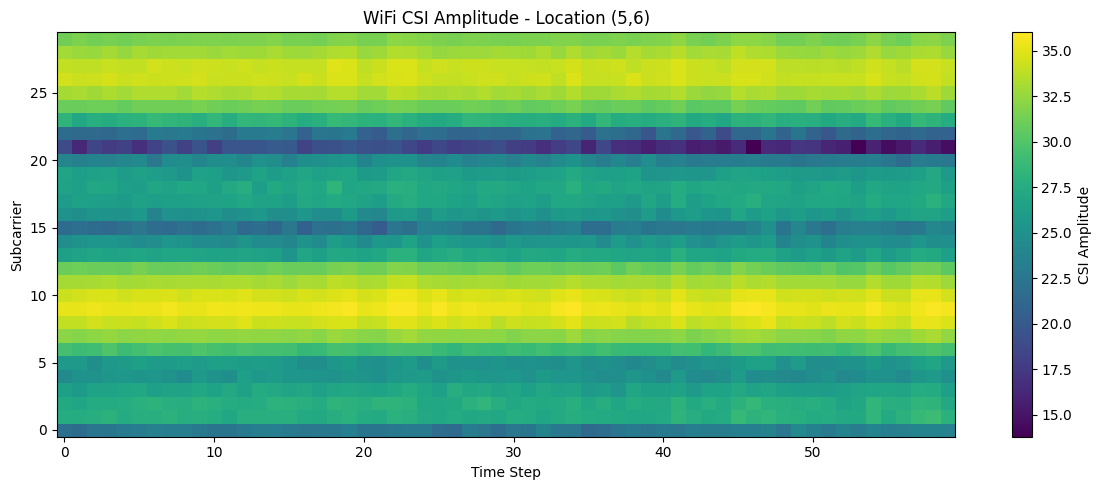

In [9]:
plt.figure(figsize=(12, 5))

plt.imshow(
    amplitude.T,
    aspect="auto",
    origin="lower",
    cmap="viridis"
)

plt.colorbar(label="CSI Amplitude")
plt.xlabel("Time Step")
plt.ylabel("Subcarrier")
plt.title("WiFi CSI Amplitude - Location (5,6)")

plt.tight_layout()
plt.show()

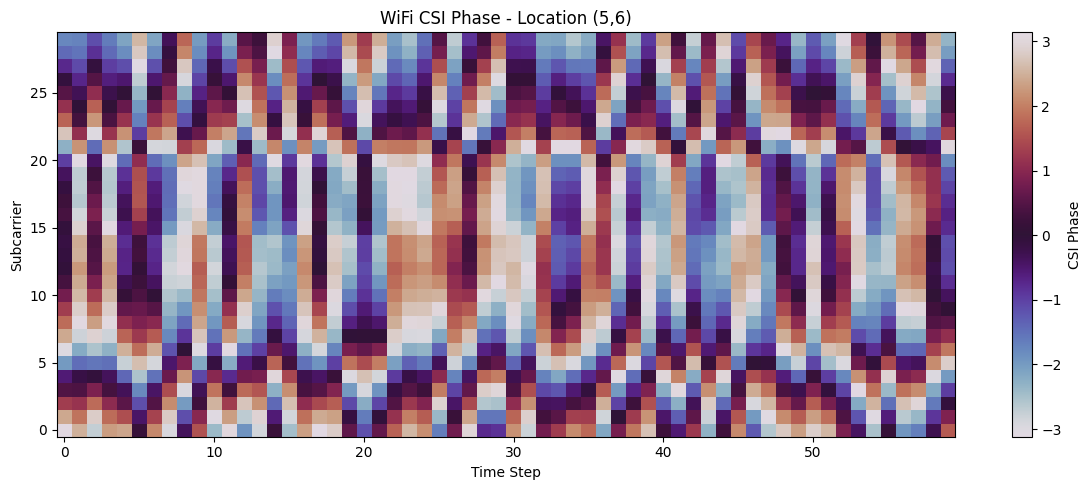

In [10]:
plt.figure(figsize=(12, 5))

plt.imshow(
    phase.T,
    aspect="auto",
    origin="lower",
    cmap="twilight"
)

plt.colorbar(label="CSI Phase")
plt.xlabel("Time Step")
plt.ylabel("Subcarrier")
plt.title("WiFi CSI Phase - Location (5,6)")

plt.tight_layout()
plt.show()

In [11]:
def load_location(csv_files, x, y):

    channels = []

    for antenna in [1, 2, 3]:

        filename = f"antenna_{antenna}_{x}_{y}.csv"

        matches = [
            path for path in csv_files
            if os.path.basename(path) == filename
        ]

        if len(matches) != 1:
            raise FileNotFoundError(filename)

        data = pd.read_csv(matches[0])

        amp_cols = [
            f"amplitude_{i}" for i in range(30)
        ]

        phase_cols = [
            f"phase_{i}" for i in range(30)
        ]

        amp = data[amp_cols].to_numpy(dtype=np.float32)
        ph = data[phase_cols].to_numpy(dtype=np.float32)

        channels.extend([amp, ph])

    lengths = [channel.shape[0] for channel in channels]

    if len(set(lengths)) != 1:
        raise ValueError("Panjang rekaman antena berbeda")

    X = np.stack(channels, axis=0)

    return X

In [12]:
X_sample = load_location(csv_files, 5, 6)

print("Bentuk input:", X_sample.shape)

Bentuk input: (6, 60, 30)


In [13]:
y_sample = np.array([5.0, 6.0], dtype=np.float32)

print("Input:", X_sample.shape)
print("Target:", y_sample)

Input: (6, 60, 30)
Target: [5. 6.]


In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Mengambil fase CSI
phase_raw = phase.copy()

# Unwrapping sepanjang dimensi subcarrier
phase_unwrapped = np.unwrap(
    phase_raw,
    axis=1
)

print("Shape fase asli:", phase_raw.shape)
print("Shape fase unwrapped:", phase_unwrapped.shape)

Shape fase asli: (60, 30)
Shape fase unwrapped: (60, 30)


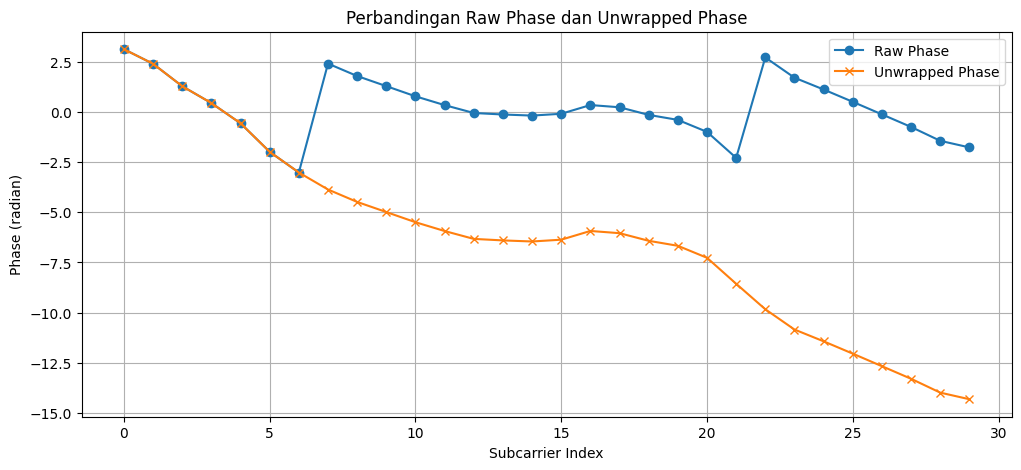

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(
    phase_raw[0],
    label="Raw Phase",
    marker="o"
)

plt.plot(
    phase_unwrapped[0],
    label="Unwrapped Phase",
    marker="x"
)

plt.xlabel("Subcarrier Index")
plt.ylabel("Phase (radian)")
plt.title("Perbandingan Raw Phase dan Unwrapped Phase")
plt.legend()
plt.grid(True)

plt.show()

In [16]:
def sanitize_phase(phase_data):

    phase_unwrapped = np.unwrap(
        phase_data,
        axis=1
    )

    n_subcarriers = phase_data.shape[1]

    x = np.arange(n_subcarriers)

    phase_clean = np.zeros_like(
        phase_unwrapped
    )

    for t in range(phase_data.shape[0]):

        coefficients = np.polyfit(
            x,
            phase_unwrapped[t],
            1
        )

        trend = np.polyval(
            coefficients,
            x
        )

        phase_clean[t] = (
            phase_unwrapped[t] - trend
        )

    return phase_clean


phase_clean = sanitize_phase(phase)

print("Phase sanitized:", phase_clean.shape)

Phase sanitized: (60, 30)


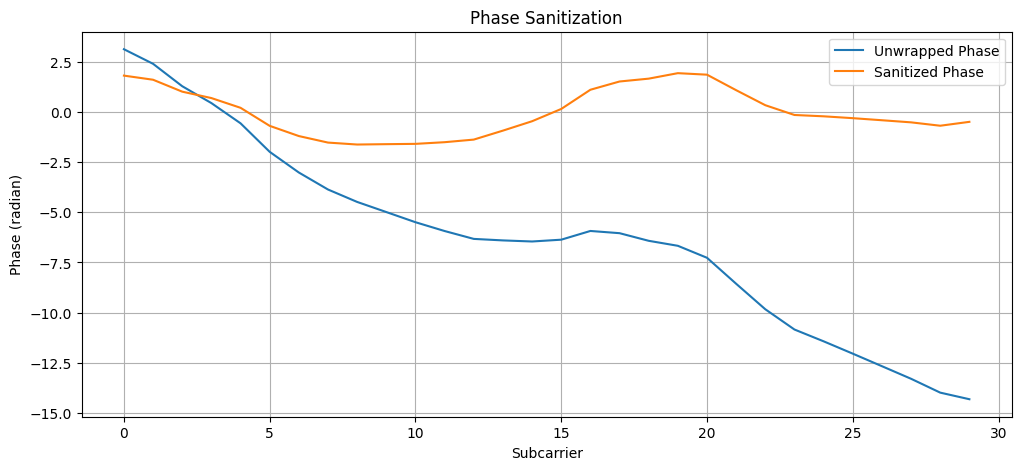

In [17]:
plt.figure(figsize=(12, 5))

plt.plot(
    phase_unwrapped[0],
    label="Unwrapped Phase"
)

plt.plot(
    phase_clean[0],
    label="Sanitized Phase"
)

plt.xlabel("Subcarrier")
plt.ylabel("Phase (radian)")
plt.title("Phase Sanitization")
plt.legend()
plt.grid(True)

plt.show()

In [18]:
def sanitize_phase(phase_data):

    phase_unwrapped = np.unwrap(
        phase_data,
        axis=1
    )

    n_subcarriers = phase_data.shape[1]

    x = np.arange(n_subcarriers)

    phase_clean = np.zeros_like(
        phase_unwrapped
    )

    for t in range(phase_data.shape[0]):

        coefficients = np.polyfit(
            x,
            phase_unwrapped[t],
            1
        )

        trend = np.polyval(
            coefficients,
            x
        )

        phase_clean[t] = (
            phase_unwrapped[t] - trend
        )

    return phase_clean


phase_clean = sanitize_phase(phase)

print("Phase sanitized:", phase_clean.shape)

Phase sanitized: (60, 30)


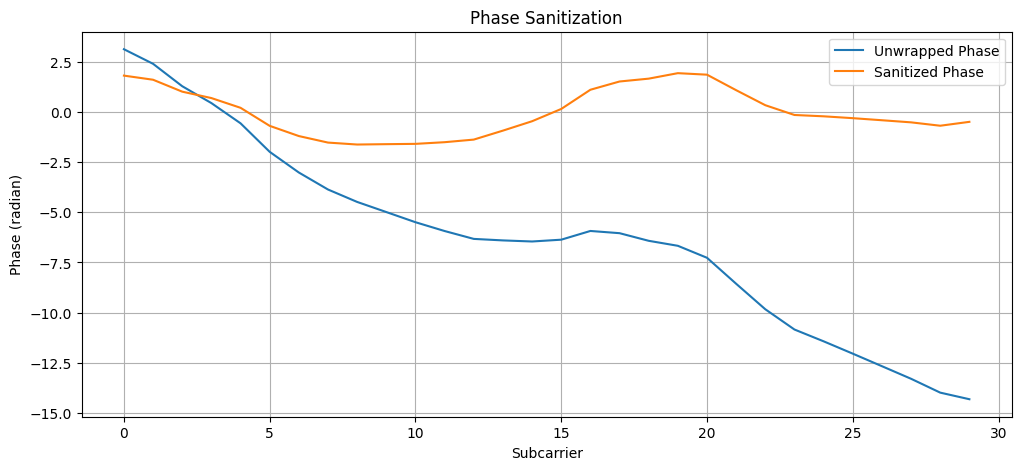

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    phase_unwrapped[0],
    label="Unwrapped Phase"
)

plt.plot(
    phase_clean[0],
    label="Sanitized Phase"
)

plt.xlabel("Subcarrier")
plt.ylabel("Phase (radian)")
plt.title("Phase Sanitization")
plt.legend()
plt.grid(True)

plt.show()

In [20]:
timestamps = df["timestamp"].to_numpy()

dt = np.diff(timestamps)

print("Minimum interval:", dt.min())
print("Median interval:", np.median(dt))
print("Maximum interval:", dt.max())

if np.any(dt <= 0):
    raise ValueError(
        "Timestamp tidak meningkat secara konsisten"
    )

fs = 1 / np.median(dt)

print("Estimasi sampling rate:", fs, "Hz")

Minimum interval: 0.0024429999999995983
Median interval: 0.0024990000000002927
Maximum interval: 0.0025469999999928
Estimasi sampling rate: 400.1600640255634 Hz


In [21]:
from scipy.signal import butter, sosfiltfilt

def butterworth_filter(
    signal,
    fs,
    cutoff=20,
    order=4
):

    if cutoff >= fs / 2:
        raise ValueError(
            "Cutoff harus lebih kecil dari Nyquist"
        )

    sos = butter(
        order,
        cutoff,
        btype="low",
        fs=fs,
        output="sos"
    )

    filtered = sosfiltfilt(
        sos,
        signal,
        axis=0
    )

    return filtered


amplitude_filtered = butterworth_filter(
    amplitude,
    fs=fs,
    cutoff=20
)

print(
    "Filtered amplitude:",
    amplitude_filtered.shape
)

Filtered amplitude: (60, 30)


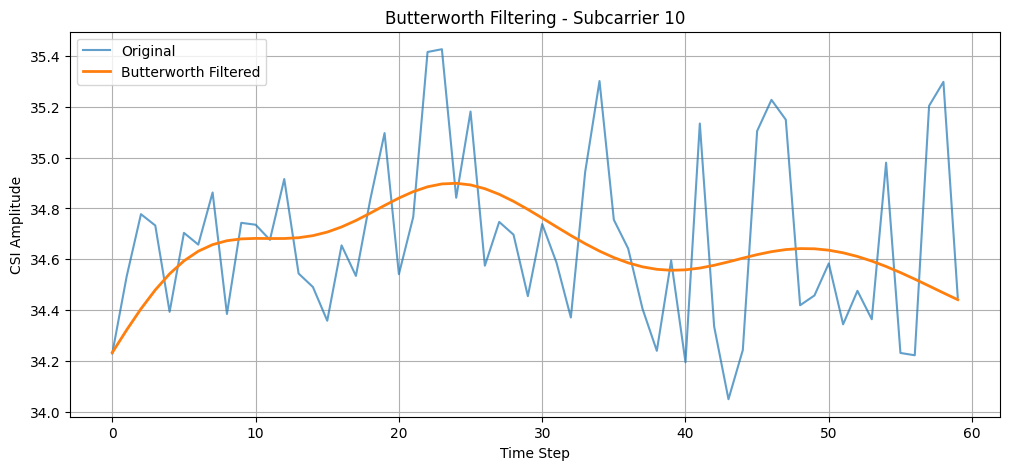

In [22]:
subcarrier = 10

plt.figure(figsize=(12, 5))

plt.plot(
    amplitude[:, subcarrier],
    label="Original",
    alpha=0.7
)

plt.plot(
    amplitude_filtered[:, subcarrier],
    label="Butterworth Filtered",
    linewidth=2
)

plt.xlabel("Time Step")
plt.ylabel("CSI Amplitude")
plt.title(
    f"Butterworth Filtering - Subcarrier {subcarrier}"
)

plt.legend()
plt.grid(True)
plt.show()

In [23]:
timestamp_list = []

for antenna in [1, 2, 3]:

    filename = f"antenna_{antenna}_5_6.csv"

    file_path = next(
        path for path in csv_files
        if os.path.basename(path) == filename
    )

    data = pd.read_csv(file_path)

    timestamp_list.append(
        data["timestamp"].to_numpy()
    )

for i in range(3):
    print(
        f"Antena {i+1}:",
        timestamp_list[i][:5]
    )

for i in range(1, 3):

    difference = (
        timestamp_list[0] -
        timestamp_list[i]
    )

    print(
        f"Selisih maksimum antena 1 dan {i+1}:",
        np.max(np.abs(difference))
    )

Antena 1: [0.       0.002536 0.005026 0.007573 0.010073]
Antena 2: [0.       0.002536 0.005026 0.007573 0.010073]
Antena 3: [0.       0.002536 0.005026 0.007573 0.010073]
Selisih maksimum antena 1 dan 2: 0.0
Selisih maksimum antena 1 dan 3: 0.0


In [24]:
import os
import re
import numpy as np

locations = set()

pattern = re.compile(
    r"antenna_(\d+)_(\d+)_(\d+)\.csv"
)

for file in csv_files:

    filename = os.path.basename(file)

    match = pattern.fullmatch(filename)

    if match:

        antenna, x, y = map(
            int,
            match.groups()
        )

        locations.add((x, y))

locations = sorted(locations)

print("Jumlah lokasi:", len(locations))
print("Contoh lokasi:", locations[:10])

Jumlah lokasi: 90
Contoh lokasi: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9)]


In [25]:
X_all = []
y_all = []

for x, y in locations:

    X = load_location(
        csv_files,
        x,
        y
    )

    X_all.append(X)

    y_all.append([x, y])

X_all = np.stack(
    X_all,
    axis=0
).astype(np.float32)

y_all = np.array(
    y_all,
    dtype=np.float32
)

print("Shape X:", X_all.shape)
print("Shape y:", y_all.shape)

Shape X: (90, 6, 60, 30)
Shape y: (90, 2)


In [26]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(X_all))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42
)

X_train = X_all[train_idx]
X_val = X_all[val_idx]
X_test = X_all[test_idx]

y_train = y_all[train_idx]
y_val = y_all[val_idx]
y_test = y_all[test_idx]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (63, 6, 60, 30)
Validation: (13, 6, 60, 30)
Test: (14, 6, 60, 30)


In [27]:
def preprocess_sample(
    sample,
    fs=400.16,
    cutoff=20
):

    processed = np.zeros_like(sample)

    for antenna in range(3):

        amp_idx = antenna * 2
        phase_idx = amp_idx + 1

        amplitude_data = sample[amp_idx]
        phase_data = sample[phase_idx]

        amplitude_filtered = butterworth_filter(
            amplitude_data,
            fs=fs,
            cutoff=cutoff
        )

        phase_sanitized = sanitize_phase(
            phase_data
        )

        processed[amp_idx] = amplitude_filtered
        processed[phase_idx] = phase_sanitized

    return processed

In [28]:
X_train_processed = np.stack([
    preprocess_sample(x)
    for x in X_train
])

X_val_processed = np.stack([
    preprocess_sample(x)
    for x in X_val
])

X_test_processed = np.stack([
    preprocess_sample(x)
    for x in X_test
])

print(
    "Train processed:",
    X_train_processed.shape
)

print(
    "Validation processed:",
    X_val_processed.shape
)

print(
    "Test processed:",
    X_test_processed.shape
)

/usr/local/lib/python3.13/dist-packages/scipy/signal/_arraytools.py:103: RuntimeWarning: invalid value encountered in subtract
  ext = np.concatenate((2 * left_end - left_ext,


Train processed: (63, 6, 60, 30)
Validation processed: (13, 6, 60, 30)
Test processed: (14, 6, 60, 30)


/usr/local/lib/python3.13/dist-packages/scipy/signal/_arraytools.py:105: RuntimeWarning: invalid value encountered in subtract
  2 * right_end - right_ext),


In [29]:
mean = X_train_processed.mean(
    axis=(0, 2, 3),
    keepdims=True
)

std = X_train_processed.std(
    axis=(0, 2, 3),
    keepdims=True
)

std = np.maximum(std, 1e-6)

X_train_normalized = (
    X_train_processed - mean
) / std

X_val_normalized = (
    X_val_processed - mean
) / std

X_test_normalized = (
    X_test_processed - mean
) / std

print(
    "Training mean:",
    X_train_normalized.mean()
)

print(
    "Training std:",
    X_train_normalized.std()
)

Training mean: nan
Training std: nan


In [30]:
import torch

from torch.utils.data import (
    TensorDataset,
    DataLoader
)

train_dataset = TensorDataset(
    torch.tensor(
        X_train_normalized,
        dtype=torch.float32
    ),
    torch.tensor(
        y_train,
        dtype=torch.float32
    )
)

val_dataset = TensorDataset(
    torch.tensor(
        X_val_normalized,
        dtype=torch.float32
    ),
    torch.tensor(
        y_val,
        dtype=torch.float32
    )
)

test_dataset = TensorDataset(
    torch.tensor(
        X_test_normalized,
        dtype=torch.float32
    ),
    torch.tensor(
        y_test,
        dtype=torch.float32
    )
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("DataLoader berhasil dibuat")

DataLoader berhasil dibuat


In [31]:
X_batch, y_batch = next(
    iter(train_loader)
)

print("Input batch:", X_batch.shape)
print("Target batch:", y_batch.shape)

Input batch: torch.Size([16, 6, 60, 30])
Target batch: torch.Size([16, 2])


In [32]:
import numpy as np

def clean_nonfinite(data):

    data = np.asarray(
        data,
        dtype=np.float64
    ).copy()

    data[~np.isfinite(data)] = np.nan

    n_time, n_subcarriers = data.shape

    for s in range(n_subcarriers):

        signal = data[:, s]

        valid = np.isfinite(signal)

        if valid.sum() == 0:
            raise ValueError(
                f"Subcarrier {s} tidak memiliki nilai valid"
            )

        if not valid.all():

            time = np.arange(n_time)

            signal[~valid] = np.interp(
                time[~valid],
                time[valid],
                signal[valid]
            )

            data[:, s] = signal

    return data.astype(np.float32)

In [33]:
def preprocess_sample(
    sample,
    fs=400.16,
    cutoff=20
):

    processed = np.zeros_like(
        sample,
        dtype=np.float32
    )

    for antenna in range(3):

        amp_idx = antenna * 2
        phase_idx = amp_idx + 1

        amplitude_data = clean_nonfinite(
            sample[amp_idx]
        )

        phase_data = clean_nonfinite(
            sample[phase_idx]
        )

        amplitude_filtered = butterworth_filter(
            amplitude_data,
            fs=fs,
            cutoff=cutoff
        )

        phase_sanitized = sanitize_phase(
            phase_data
        )

        processed[amp_idx] = amplitude_filtered
        processed[phase_idx] = phase_sanitized

    return processed

In [34]:
X_train_processed = np.stack([
    preprocess_sample(x)
    for x in X_train
])

X_val_processed = np.stack([
    preprocess_sample(x)
    for x in X_val
])

X_test_processed = np.stack([
    preprocess_sample(x)
    for x in X_test
])

print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

print(
    "Train finite:",
    np.isfinite(X_train_processed).all()
)

print(
    "Validation finite:",
    np.isfinite(X_val_processed).all()
)

print(
    "Test finite:",
    np.isfinite(X_test_processed).all()
)

Train: (63, 6, 60, 30)
Validation: (13, 6, 60, 30)
Test: (14, 6, 60, 30)
Train finite: True
Validation finite: True
Test finite: True


In [35]:
mean = X_train_processed.mean(
    axis=(0, 2, 3),
    keepdims=True
)

std = X_train_processed.std(
    axis=(0, 2, 3),
    keepdims=True
)

std = np.maximum(std, 1e-6)

X_train_normalized = (
    X_train_processed - mean
) / std

X_val_normalized = (
    X_val_processed - mean
) / std

X_test_normalized = (
    X_test_processed - mean
) / std

for name, data in [
    ("Train", X_train_normalized),
    ("Validation", X_val_normalized),
    ("Test", X_test_normalized)
]:

    print(
        name,
        "Finite:",
        np.isfinite(data).all()
    )

print(
    "Training mean:",
    X_train_normalized.mean()
)

print(
    "Training std:",
    X_train_normalized.std()
)

Train Finite: True
Validation Finite: True
Test Finite: True
Training mean: -4.2102954e-07
Training std: 1.0000001


In [36]:
X_batch, y_batch = next(iter(train_loader))

print("Input:", X_batch.shape)
print("Target:", y_batch.shape)

print(
    "Input valid:",
    torch.isfinite(X_batch).all().item()
)

print(
    "Target valid:",
    torch.isfinite(y_batch).all().item()
)

Input: torch.Size([16, 6, 60, 30])
Target: torch.Size([16, 2])
Input valid: False
Target valid: True


In [37]:
import numpy as np
import torch

print("=== NUMPY CHECK ===")

print(
    "Train:",
    np.isfinite(X_train_normalized).all()
)

print(
    "Validation:",
    np.isfinite(X_val_normalized).all()
)

print(
    "Test:",
    np.isfinite(X_test_normalized).all()
)

=== NUMPY CHECK ===
Train: True
Validation: True
Test: True


In [38]:
from torch.utils.data import TensorDataset, DataLoader

# Membuat ulang TensorDataset

train_dataset = TensorDataset(
    torch.from_numpy(
        X_train_normalized.copy()
    ).float(),
    torch.from_numpy(
        y_train.copy()
    ).float()
)

val_dataset = TensorDataset(
    torch.from_numpy(
        X_val_normalized.copy()
    ).float(),
    torch.from_numpy(
        y_val.copy()
    ).float()
)

test_dataset = TensorDataset(
    torch.from_numpy(
        X_test_normalized.copy()
    ).float(),
    torch.from_numpy(
        y_test.copy()
    ).float()
)

# Membuat ulang DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("DataLoader berhasil diperbarui")

DataLoader berhasil diperbarui


In [39]:
print("=== PYTORCH DATASET CHECK ===")

for name, dataset in [
    ("Train", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset)
]:

    X, y = dataset.tensors

    print(f"\n{name}")

    print("Input shape:", X.shape)
    print("Target shape:", y.shape)

    print(
        "Input finite:",
        torch.isfinite(X).all().item()
    )

    print(
        "Target finite:",
        torch.isfinite(y).all().item()
    )

=== PYTORCH DATASET CHECK ===

Train
Input shape: torch.Size([63, 6, 60, 30])
Target shape: torch.Size([63, 2])
Input finite: True
Target finite: True

Validation
Input shape: torch.Size([13, 6, 60, 30])
Target shape: torch.Size([13, 2])
Input finite: True
Target finite: True

Test
Input shape: torch.Size([14, 6, 60, 30])
Target shape: torch.Size([14, 2])
Input finite: True
Target finite: True


In [40]:
def validate_loader(loader, name):

    print(f"\nChecking {name}...")

    for batch_idx, (X, y) in enumerate(loader):

        if not torch.isfinite(X).all():
            raise ValueError(
                f"Invalid input pada batch {batch_idx}"
            )

        if not torch.isfinite(y).all():
            raise ValueError(
                f"Invalid target pada batch {batch_idx}"
            )

    print(f"{name}: ALL BATCHES VALID")


validate_loader(train_loader, "TRAIN")
validate_loader(val_loader, "VALIDATION")
validate_loader(test_loader, "TEST")


Checking TRAIN...
TRAIN: ALL BATCHES VALID

Checking VALIDATION...
VALIDATION: ALL BATCHES VALID

Checking TEST...
TEST: ALL BATCHES VALID


In [41]:
import torch
import torch.nn as nn

class CSI_CNN(nn.Module):

    def __init__(self):
        super(CSI_CNN, self).__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                in_channels=6,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            ),

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            ),

            nn.AdaptiveAvgPool2d(
                output_size=(1, 1)
            )
        )

        self.regressor = nn.Sequential(

            nn.Flatten(),

            nn.Linear(64, 32),

            nn.ReLU(),

            nn.Linear(32, 2)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.regressor(x)

        return x

In [42]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model_cnn = CSI_CNN().to(device)

print("Device:", device)

print(model_cnn)

Device: cuda
CSI_CNN(
  (features): Sequential(
    (0): Conv2d(6, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (regressor): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=32, bias=True)
    (2): ReLU()
    (3): Linear(in_features=32, out_features=2, bias=True)
  )
)


In [43]:
X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)

output = model_cnn(X_batch)

print("Input shape:", X_batch.shape)

print("Output shape:", output.shape)

print("Prediksi awal:", output[:5])

Input shape: torch.Size([16, 6, 60, 30])
Output shape: torch.Size([16, 2])
Prediksi awal: tensor([[-0.1561, -0.1128],
        [-0.1649, -0.1104],
        [-0.1563, -0.1528],
        [-0.1702, -0.1323],
        [-0.1597, -0.1416]], device='cuda:0', grad_fn=<SliceBackward0>)


In [44]:
import torch.optim as optim

criterion = nn.SmoothL1Loss()

optimizer = optim.Adam(
    model_cnn.parameters(),
    lr=0.001
)

epochs = 100

print("Loss Function:", criterion)

print("Optimizer:", optimizer.__class__.__name__)

print("Epochs:", epochs)

Loss Function: SmoothL1Loss()
Optimizer: Adam
Epochs: 100


In [45]:
import copy

def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=100
):

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):

        # TRAINING
        model.train()

        total_train_loss = 0

        for X, y in train_loader:

            X = X.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            predictions = model(X)

            loss = criterion(
                predictions,
                y
            )

            loss.backward()

            optimizer.step()

            total_train_loss += (
                loss.item() * X.size(0)
            )

        avg_train_loss = (
            total_train_loss /
            len(train_loader.dataset)
        )

        # VALIDATION
        model.eval()

        total_val_loss = 0

        with torch.no_grad():

            for X, y in val_loader:

                X = X.to(device)
                y = y.to(device)

                predictions = model(X)

                loss = criterion(
                    predictions,
                    y
                )

                total_val_loss += (
                    loss.item() * X.size(0)
                )

        avg_val_loss = (
            total_val_loss /
            len(val_loader.dataset)
        )

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)

        if avg_val_loss < best_val_loss:

            best_val_loss = avg_val_loss

            best_weights = copy.deepcopy(
                model.state_dict()
            )

        if (epoch + 1) % 10 == 0:

            print(
                f"Epoch [{epoch+1}/{epochs}] "
                f"Train Loss: {avg_train_loss:.4f} "
                f"Val Loss: {avg_val_loss:.4f}"
            )

    model.load_state_dict(best_weights)

    return model, train_losses, val_losses

In [46]:
model_cnn, train_losses, val_losses = train_model(
    model=model_cnn,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=epochs
)

print("Training CNN selesai")

Epoch [10/100] Train Loss: 1.9148 Val Loss: 2.0071
Epoch [20/100] Train Loss: 1.8114 Val Loss: 1.9764
Epoch [30/100] Train Loss: 1.7680 Val Loss: 2.0383
Epoch [40/100] Train Loss: 1.7049 Val Loss: 2.0807
Epoch [50/100] Train Loss: 1.6134 Val Loss: 2.0884
Epoch [60/100] Train Loss: 1.3937 Val Loss: 2.0824
Epoch [70/100] Train Loss: 1.2161 Val Loss: 1.9096
Epoch [80/100] Train Loss: 1.1172 Val Loss: 1.9362
Epoch [90/100] Train Loss: 1.0329 Val Loss: 1.8524
Epoch [100/100] Train Loss: 0.8948 Val Loss: 1.9040
Training CNN selesai


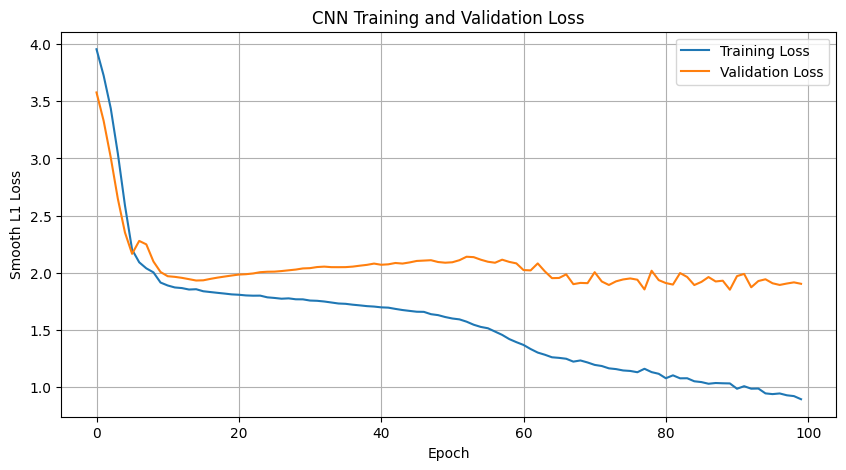

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Smooth L1 Loss")

plt.title("CNN Training and Validation Loss")

plt.legend()

plt.grid(True)

plt.show()

In [48]:
def evaluate_model(model, test_loader):

    model.eval()

    predictions_all = []
    targets_all = []

    with torch.no_grad():

        for X, y in test_loader:

            X = X.to(device)

            predictions = model(X)

            predictions_all.append(
                predictions.cpu().numpy()
            )

            targets_all.append(
                y.numpy()
            )

    predictions_all = np.concatenate(
        predictions_all,
        axis=0
    )

    targets_all = np.concatenate(
        targets_all,
        axis=0
    )

    distances = np.linalg.norm(
        predictions_all - targets_all,
        axis=1
    )

    mean_error = distances.mean()

    median_error = np.median(distances)

    rmse = np.sqrt(
        np.mean(
            np.sum(
                (predictions_all - targets_all)**2,
                axis=1
            )
        )
    )

    print("Mean Distance Error:", mean_error)

    print("Median Distance Error:", median_error)

    print("Position RMSE:", rmse)

    return predictions_all, targets_all, distances

In [49]:
cnn_predictions, cnn_targets, cnn_distances = evaluate_model(
    model_cnn,
    test_loader
)

Mean Distance Error: 3.6334693
Median Distance Error: 3.2216108
Position RMSE: 4.027379


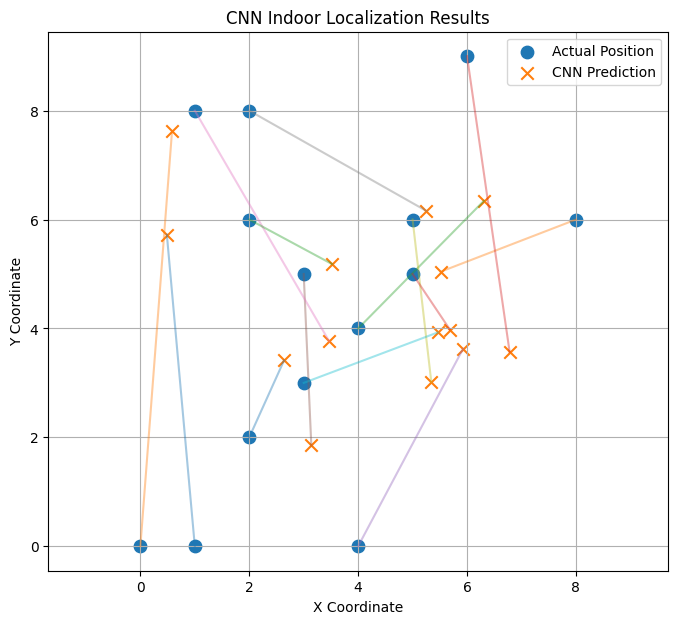

In [50]:
plt.figure(figsize=(8, 7))

plt.scatter(
    cnn_targets[:, 0],
    cnn_targets[:, 1],
    label="Actual Position",
    marker="o",
    s=80
)

plt.scatter(
    cnn_predictions[:, 0],
    cnn_predictions[:, 1],
    label="CNN Prediction",
    marker="x",
    s=80
)

for i in range(len(cnn_targets)):

    plt.plot(
        [
            cnn_targets[i, 0],
            cnn_predictions[i, 0]
        ],
        [
            cnn_targets[i, 1],
            cnn_predictions[i, 1]
        ],
        alpha=0.4
    )

plt.xlabel("X Coordinate")

plt.ylabel("Y Coordinate")

plt.title("CNN Indoor Localization Results")

plt.legend()

plt.grid(True)

plt.axis("equal")

plt.show()

In [51]:
torch.save(
    {
        "model_state_dict": model_cnn.state_dict(),
        "normalization_mean": mean,
        "normalization_std": std,
        "train_indices": train_idx,
        "validation_indices": val_idx,
        "test_indices": test_idx
    },
    "cnn_indoor_localization.pth"
)

print("Model CNN berhasil disimpan")

Model CNN berhasil disimpan


In [52]:
import numpy as np

# Menghitung rata-rata koordinat training
mean_position = y_train.mean(axis=0)

# Memprediksi koordinat yang sama untuk seluruh test set
baseline_predictions = np.tile(
    mean_position,
    (len(y_test), 1)
)

# Menghitung Euclidean Distance Error
baseline_distances = np.linalg.norm(
    baseline_predictions - y_test,
    axis=1
)

baseline_mde = baseline_distances.mean()

print("Mean training position:", mean_position)
print("Baseline MDE:", baseline_mde)
print("CNN MDE:", cnn_distances.mean())

Mean training position: [4.047619  4.6825395]
Baseline MDE: 3.2833638
CNN MDE: 3.6334693


In [53]:
import torch
import torch.nn as nn

class CSI_CNN_LSTM(nn.Module):

    def __init__(self):
        super(CSI_CNN_LSTM, self).__init__()

        # CNN untuk ekstraksi fitur setiap timestep
        self.cnn = nn.Sequential(

            nn.Conv1d(
                in_channels=6,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        # LSTM untuk mempelajari hubungan temporal
        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=64,
            num_layers=1,
            batch_first=True
        )

        # Regresi koordinat
        self.regressor = nn.Sequential(

            nn.Linear(64, 32),

            nn.ReLU(),

            nn.Linear(32, 2)
        )

    def forward(self, x):

        batch_size, channels, timesteps, subcarriers = x.shape

        # [B, C, T, S] -> [B, T, C, S]
        x = x.permute(0, 2, 1, 3)

        # [B, T, C, S] -> [B*T, C, S]
        x = x.reshape(
            batch_size * timesteps,
            channels,
            subcarriers
        )

        # Ekstraksi fitur CNN
        x = self.cnn(x)

        # [B*T, 64, 1] -> [B*T, 64]
        x = x.squeeze(-1)

        # [B*T, 64] -> [B, T, 64]
        x = x.reshape(
            batch_size,
            timesteps,
            64
        )

        # Pemodelan temporal LSTM
        lstm_output, _ = self.lstm(x)

        # Mengambil representasi timestep terakhir
        x = lstm_output[:, -1, :]

        # Prediksi koordinat
        output = self.regressor(x)

        return output

In [54]:
model_cnn_lstm = CSI_CNN_LSTM().to(device)

print(model_cnn_lstm)

X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)

with torch.no_grad():
    output = model_cnn_lstm(X_batch)

print("Input shape:", X_batch.shape)
print("Output shape:", output.shape)

CSI_CNN_LSTM(
  (cnn): Sequential(
    (0): Conv1d(6, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (3): ReLU()
    (4): AdaptiveAvgPool1d(output_size=1)
  )
  (lstm): LSTM(64, 64, batch_first=True)
  (regressor): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=2, bias=True)
  )
)
Input shape: torch.Size([16, 6, 60, 30])
Output shape: torch.Size([16, 2])


In [55]:
import torch.optim as optim

criterion_lstm = nn.SmoothL1Loss()

optimizer_lstm = optim.Adam(
    model_cnn_lstm.parameters(),
    lr=0.001
)

epochs_lstm = 100

In [56]:
model_cnn_lstm, lstm_train_losses, lstm_val_losses = train_model(
    model=model_cnn_lstm,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_lstm,
    optimizer=optimizer_lstm,
    epochs=epochs_lstm
)

print("Training CNN-LSTM selesai")

Epoch [10/100] Train Loss: 2.0938 Val Loss: 1.9624
Epoch [20/100] Train Loss: 1.8999 Val Loss: 2.0880
Epoch [30/100] Train Loss: 1.8968 Val Loss: 2.0801
Epoch [40/100] Train Loss: 1.8910 Val Loss: 2.0697
Epoch [50/100] Train Loss: 1.8707 Val Loss: 2.0442
Epoch [60/100] Train Loss: 1.8232 Val Loss: 1.9708
Epoch [70/100] Train Loss: 1.7133 Val Loss: 1.9694
Epoch [80/100] Train Loss: 1.5251 Val Loss: 1.8671
Epoch [90/100] Train Loss: 1.4465 Val Loss: 1.7735
Epoch [100/100] Train Loss: 1.3389 Val Loss: 1.8338
Training CNN-LSTM selesai


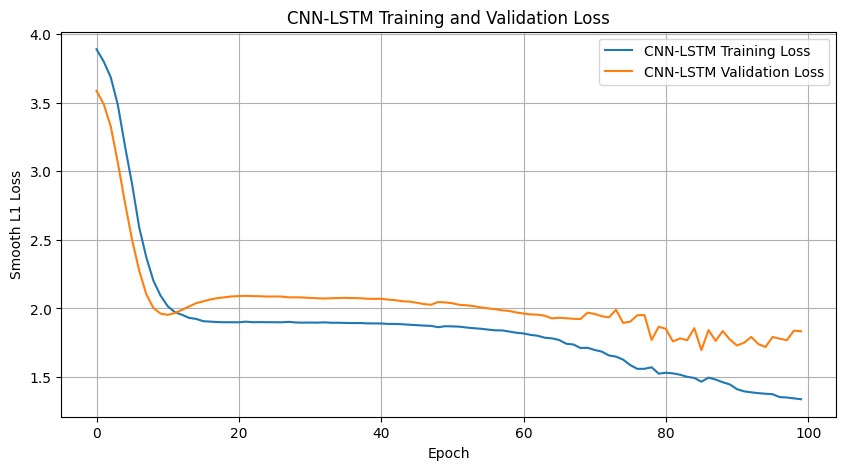

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    lstm_train_losses,
    label="CNN-LSTM Training Loss"
)

plt.plot(
    lstm_val_losses,
    label="CNN-LSTM Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Smooth L1 Loss")

plt.title("CNN-LSTM Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [58]:
lstm_predictions, lstm_targets, lstm_distances = evaluate_model(
    model_cnn_lstm,
    test_loader
)

Mean Distance Error: 3.3410785
Median Distance Error: 3.8959455
Position RMSE: 3.6464307


In [59]:
import pandas as pd
import numpy as np

results = pd.DataFrame({

    "Model": [
        "Mean Position Baseline",
        "CNN",
        "CNN-LSTM"
    ],

    "Mean Distance Error": [
        baseline_distances.mean(),
        cnn_distances.mean(),
        lstm_distances.mean()
    ],

    "Median Distance Error": [
        np.median(baseline_distances),
        np.median(cnn_distances),
        np.median(lstm_distances)
    ],

    "Position RMSE": [
        np.sqrt(np.mean(baseline_distances**2)),
        np.sqrt(np.mean(cnn_distances**2)),
        np.sqrt(np.mean(lstm_distances**2))
    ]

})

display(results)

,Model,Mean Distance Error,Median Distance Error,Position RMSE
0,Mean Position Baseline,3.283364,3.636611,3.715947
1,CNN,3.633469,3.221611,4.027379
2,CNN-LSTM,3.341079,3.895946,3.646431


In [60]:
torch.save(
    {
        "model_state_dict": model_cnn_lstm.state_dict(),
        "normalization_mean": mean,
        "normalization_std": std,
        "train_indices": train_idx,
        "validation_indices": val_idx,
        "test_indices": test_idx
    },
    "cnn_lstm_indoor_localization.pth"
)

print("Model CNN-LSTM berhasil disimpan")

Model CNN-LSTM berhasil disimpan


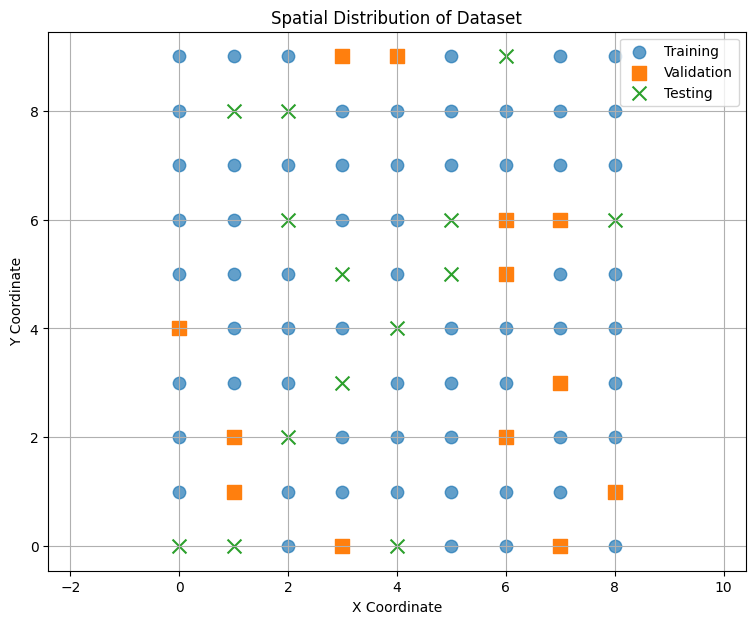

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.scatter(
    y_train[:, 0],
    y_train[:, 1],
    label="Training",
    s=80,
    alpha=0.7
)

plt.scatter(
    y_val[:, 0],
    y_val[:, 1],
    label="Validation",
    marker="s",
    s=90
)

plt.scatter(
    y_test[:, 0],
    y_test[:, 1],
    label="Testing",
    marker="x",
    s=100
)

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.title("Spatial Distribution of Dataset")

plt.legend()
plt.grid(True)
plt.axis("equal")

plt.show()

In [62]:
import numpy as np

def extract_statistical_features(X):

    # Mean sepanjang dimensi waktu
    mean_features = np.mean(
        X,
        axis=2
    )

    # Standard deviation sepanjang dimensi waktu
    std_features = np.std(
        X,
        axis=2
    )

    # Menggabungkan fitur
    features = np.concatenate(
        [
            mean_features,
            std_features
        ],
        axis=1
    )

    # Flatten menjadi vektor
    features = features.reshape(
        X.shape[0],
        -1
    )

    return features


X_train_knn = extract_statistical_features(
    X_train_normalized
)

X_val_knn = extract_statistical_features(
    X_val_normalized
)

X_test_knn = extract_statistical_features(
    X_test_normalized
)

print("Train:", X_train_knn.shape)
print("Validation:", X_val_knn.shape)
print("Test:", X_test_knn.shape)

Train: (63, 360)
Validation: (13, 360)
Test: (14, 360)


In [63]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

k_values = [1, 3, 5, 7, 9, 11]

validation_results = []

for k in k_values:

    knn = KNeighborsRegressor(
        n_neighbors=k,
        weights="distance"
    )

    knn.fit(
        X_train_knn,
        y_train
    )

    predictions = knn.predict(
        X_val_knn
    )

    distances = np.linalg.norm(
        predictions - y_val,
        axis=1
    )

    mde = distances.mean()

    validation_results.append(mde)

    print(
        f"K={k}, Validation MDE={mde:.4f}"
    )

K=1, Validation MDE=4.5666
K=3, Validation MDE=3.7978
K=5, Validation MDE=3.5435
K=7, Validation MDE=3.6512
K=9, Validation MDE=3.5430
K=11, Validation MDE=3.4525


In [64]:
best_index = np.argmin(
    validation_results
)

best_k = k_values[best_index]

print("Best K:", best_k)

print(
    "Best Validation MDE:",
    validation_results[best_index]
)

Best K: 11
Best Validation MDE: 3.4524968728079353


In [65]:
best_knn = KNeighborsRegressor(
    n_neighbors=best_k,
    weights="distance"
)

best_knn.fit(
    X_train_knn,
    y_train
)

knn_predictions = best_knn.predict(
    X_test_knn
)

knn_distances = np.linalg.norm(
    knn_predictions - y_test,
    axis=1
)

knn_mde = knn_distances.mean()

knn_median = np.median(
    knn_distances
)

knn_rmse = np.sqrt(
    np.mean(knn_distances**2)
)

print("KNN Mean Distance Error:", knn_mde)
print("KNN Median Distance Error:", knn_median)
print("KNN Position RMSE:", knn_rmse)

KNN Mean Distance Error: 3.4761771093442184
KNN Median Distance Error: 3.3555311840632287
KNN Position RMSE: 3.8172855239765227


In [66]:
import pandas as pd

comparison = pd.DataFrame({

    "Model": [
        "Mean Position",
        "KNN",
        "CNN",
        "CNN-LSTM"
    ],

    "MDE": [
        baseline_distances.mean(),
        knn_distances.mean(),
        cnn_distances.mean(),
        lstm_distances.mean()
    ],

    "Median Error": [
        np.median(baseline_distances),
        np.median(knn_distances),
        np.median(cnn_distances),
        np.median(lstm_distances)
    ],

    "Position RMSE": [
        np.sqrt(np.mean(baseline_distances**2)),
        np.sqrt(np.mean(knn_distances**2)),
        np.sqrt(np.mean(cnn_distances**2)),
        np.sqrt(np.mean(lstm_distances**2))
    ]

})

display(
    comparison.sort_values("MDE")
)

,Model,MDE,Median Error,Position RMSE
0,Mean Position,3.283364,3.636611,3.715947
3,CNN-LSTM,3.341079,3.895946,3.646431
1,KNN,3.476177,3.355531,3.817286
2,CNN,3.633469,3.221611,4.027379


In [67]:
import pandas as pd
import numpy as np

error_analysis = pd.DataFrame({
    "Actual_X": y_test[:, 0],
    "Actual_Y": y_test[:, 1],

    "CNN_Error": cnn_distances,
    "CNN_LSTM_Error": lstm_distances,
    "KNN_Error": knn_distances,
    "Baseline_Error": baseline_distances
})

display(
    error_analysis.sort_values(
        "CNN_LSTM_Error",
        ascending=False
    )
)

,Actual_X,Actual_Y,CNN_Error,CNN_LSTM_Error,KNN_Error,Baseline_Error
11,0.0,0.0,7.640009,4.845122,5.894022,6.189458
6,1.0,8.0,4.904792,4.799562,4.217350,4.504834
4,4.0,0.0,4.109321,4.758386,3.117651,4.682782
0,1.0,0.0,5.745487,4.639253,5.562583,5.586963
7,2.0,8.0,3.736251,4.549833,4.989216,3.898498
3,6.0,9.0,5.486497,4.290448,5.373069,4.738381
10,2.0,2.0,1.550871,3.991403,3.364720,3.374724
12,2.0,6.0,1.727906,3.800488,3.095306,2.434840
9,3.0,3.0,2.630438,3.117640,3.590592,1.982030
1,8.0,6.0,2.664440,3.007500,3.346343,4.166176


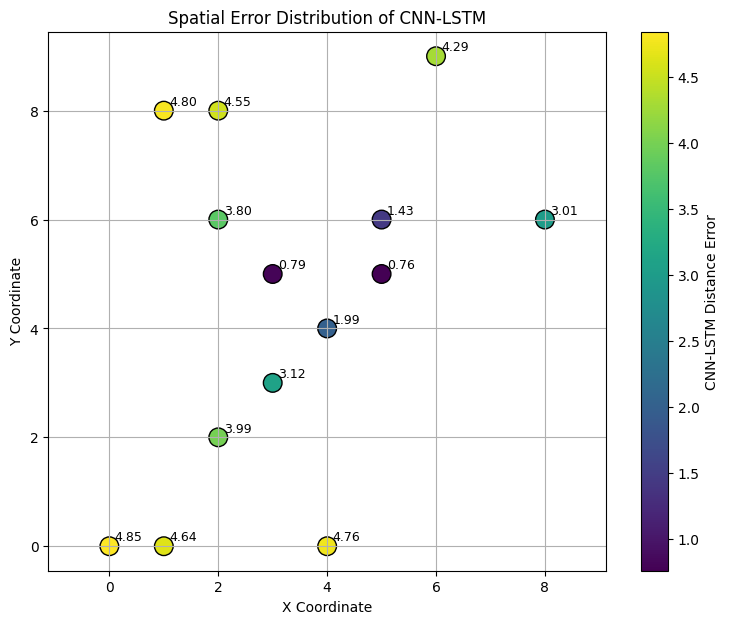

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

scatter = plt.scatter(
    y_test[:, 0],
    y_test[:, 1],
    c=lstm_distances,
    cmap="viridis",
    s=180,
    edgecolors="black"
)

plt.colorbar(
    scatter,
    label="CNN-LSTM Distance Error"
)

for i in range(len(y_test)):
    plt.annotate(
        f"{lstm_distances[i]:.2f}",
        (
            y_test[i, 0] + 0.1,
            y_test[i, 1] + 0.1
        ),
        fontsize=9
    )

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("Spatial Error Distribution of CNN-LSTM")
plt.grid(True)
plt.axis("equal")
plt.show()

In [69]:
from sklearn.neighbors import NearestNeighbors

nearest_model = NearestNeighbors(
    n_neighbors=1,
    metric="euclidean"
)

nearest_model.fit(y_train)

nearest_distances, nearest_indices = (
    nearest_model.kneighbors(y_test)
)

nearest_distances = nearest_distances.flatten()

spatial_analysis = pd.DataFrame({
    "Actual_X": y_test[:, 0],
    "Actual_Y": y_test[:, 1],
    "Nearest_Train_Distance": nearest_distances,
    "CNN_LSTM_Error": lstm_distances
})

display(spatial_analysis)

,Actual_X,Actual_Y,Nearest_Train_Distance,CNN_LSTM_Error
0,1.0,0.0,1.0,4.639253
1,8.0,6.0,1.0,3.007500
2,4.0,4.0,1.0,1.993099
3,6.0,9.0,1.0,4.290448
4,4.0,0.0,1.0,4.758386
5,3.0,5.0,1.0,0.793585
6,1.0,8.0,1.0,4.799562
7,2.0,8.0,1.0,4.549833
8,5.0,6.0,1.0,1.432191
9,3.0,3.0,1.0,3.117640


Spearman correlation: nan
P-value: nan


/tmp/ipykernel_1403/3142000454.py:3: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  correlation, p_value = spearmanr(


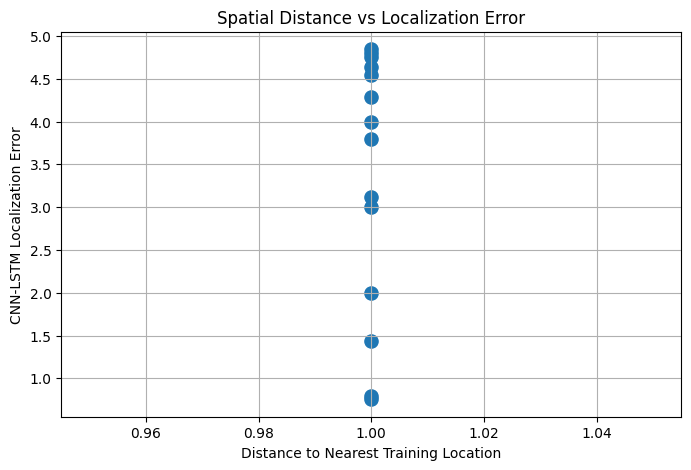

In [70]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    nearest_distances,
    lstm_distances
)

print("Spearman correlation:", correlation)
print("P-value:", p_value)

plt.figure(figsize=(8, 5))

plt.scatter(
    nearest_distances,
    lstm_distances,
    s=90
)

plt.xlabel("Distance to Nearest Training Location")
plt.ylabel("CNN-LSTM Localization Error")

plt.title("Spatial Distance vs Localization Error")
plt.grid(True)
plt.show()

In [71]:
def select_csi_features(X, mode="both"):

    X_selected = X.copy()

    amplitude_channels = [0, 2, 4]
    phase_channels = [1, 3, 5]

    if mode == "amplitude":
        X_selected[:, phase_channels, :, :] = 0

    elif mode == "phase":
        X_selected[:, amplitude_channels, :, :] = 0

    elif mode == "both":
        pass

    else:
        raise ValueError("Mode tidak dikenal")

    return X_selected

In [72]:
import torch
from torch.utils.data import TensorDataset, DataLoader

def create_ablation_loader(X, y, mode, shuffle=False):

    X_selected = select_csi_features(
        X,
        mode
    )

    dataset = TensorDataset(
        torch.tensor(
            X_selected,
            dtype=torch.float32
        ),
        torch.tensor(
            y,
            dtype=torch.float32
        )
    )

    return DataLoader(
        dataset,
        batch_size=16,
        shuffle=shuffle
    )

In [73]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import random

ablation_results = []

for mode in ["amplitude", "phase", "both"]:

    print(f"\nTraining mode: {mode}")

    # Menetapkan seed agar inisialisasi lebih konsisten
    torch.manual_seed(42)
    np.random.seed(42)
    random.seed(42)

    train_loader_ablation = create_ablation_loader(
        X_train_normalized,
        y_train,
        mode,
        shuffle=True
    )

    val_loader_ablation = create_ablation_loader(
        X_val_normalized,
        y_val,
        mode
    )

    test_loader_ablation = create_ablation_loader(
        X_test_normalized,
        y_test,
        mode
    )

    model = CSI_CNN_LSTM().to(device)

    criterion = nn.SmoothL1Loss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    model, train_loss, val_loss = train_model(
        model,
        train_loader_ablation,
        val_loader_ablation,
        criterion,
        optimizer,
        epochs=100
    )

    predictions, targets, distances = evaluate_model(
        model,
        test_loader_ablation
    )

    ablation_results.append({
        "Input": mode,
        "MDE": distances.mean(),
        "Median Error": np.median(distances),
        "Position RMSE": np.sqrt(
            np.mean(distances**2)
        )
    })

    torch.save(
        model.state_dict(),
        f"cnn_lstm_{mode}.pth"
    )

ablation_df = pd.DataFrame(ablation_results)

display(
    ablation_df.sort_values("MDE")
)


Training mode: amplitude
Epoch [10/100] Train Loss: 2.1374 Val Loss: 2.1334
Epoch [20/100] Train Loss: 1.8993 Val Loss: 2.0889
Epoch [30/100] Train Loss: 1.8979 Val Loss: 2.0876
Epoch [40/100] Train Loss: 1.8781 Val Loss: 2.0784
Epoch [50/100] Train Loss: 1.8400 Val Loss: 2.0122
Epoch [60/100] Train Loss: 1.7915 Val Loss: 1.9494
Epoch [70/100] Train Loss: 1.7402 Val Loss: 1.9006
Epoch [80/100] Train Loss: 1.6988 Val Loss: 1.9393
Epoch [90/100] Train Loss: 1.6063 Val Loss: 1.7790
Epoch [100/100] Train Loss: 1.6033 Val Loss: 1.8427
Mean Distance Error: 3.0283396
Median Distance Error: 3.4548454
Position RMSE: 3.3369017

Training mode: phase
Epoch [10/100] Train Loss: 2.1218 Val Loss: 2.1242
Epoch [20/100] Train Loss: 1.8961 Val Loss: 2.0868
Epoch [30/100] Train Loss: 1.8954 Val Loss: 2.0864
Epoch [40/100] Train Loss: 1.8823 Val Loss: 2.0710
Epoch [50/100] Train Loss: 1.8514 Val Loss: 2.0614
Epoch [60/100] Train Loss: 1.8739 Val Loss: 2.0564
Epoch [70/100] Train Loss: 1.8522 Val Loss: 2.

,Input,MDE,Median Error,Position RMSE
0,amplitude,3.028340,3.454845,3.336902
1,phase,3.200017,3.750005,3.577876
2,both,3.383883,3.970008,3.660094


In [74]:
import torch
import numpy as np
import random

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"Random seed: {seed}")

In [75]:
import copy
import torch
import torch.nn as nn

def train_model_best(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=100
):

    best_val_loss = float("inf")
    best_state = None

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        model.train()

        train_loss = 0
        train_samples = 0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            loss.backward()
            optimizer.step()

            batch_size = X_batch.size(0)

            train_loss += loss.item() * batch_size
            train_samples += batch_size

        train_loss /= train_samples

        model.eval()

        val_loss = 0
        val_samples = 0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                predictions = model(X_batch)

                loss = criterion(
                    predictions,
                    y_batch
                )

                batch_size = X_batch.size(0)

                val_loss += loss.item() * batch_size
                val_samples += batch_size

        val_loss /= val_samples

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(best_state)

    return (
        model,
        train_losses,
        val_losses,
        best_val_loss
    )

In [76]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# =====================================
# FUNGSI PEMILIHAN FITUR CSI
# =====================================

def select_csi_features(X, mode="both"):

    X_selected = X.copy()

    amplitude_channels = [0, 2, 4]
    phase_channels = [1, 3, 5]

    if mode == "amplitude":

        X_selected[:, phase_channels, :, :] = 0

    elif mode == "phase":

        X_selected[:, amplitude_channels, :, :] = 0

    elif mode == "both":

        pass

    else:

        raise ValueError("Mode tidak dikenal")

    return X_selected


# =====================================
# FUNGSI MEMBUAT DATALOADER
# =====================================

def create_ablation_loader(
    X,
    y,
    mode,
    shuffle=False
):

    X_selected = select_csi_features(
        X,
        mode
    )

    dataset = TensorDataset(

        torch.tensor(
            X_selected,
            dtype=torch.float32
        ),

        torch.tensor(
            y,
            dtype=torch.float32
        )

    )

    loader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=shuffle
    )

    return loader


print("Fungsi ablation berhasil dibuat!")

Fungsi ablation berhasil dibuat!


In [77]:
import os

print("Current directory:", os.getcwd())

print("\nFiles in current directory:")

for file in os.listdir():
    print(file)

Current directory: /content

Files in current directory:
.config
wifi_csi_dataset
dataset.zip
cnn_lstm_indoor_localization.pth
cnn_indoor_localization.pth
cnn_lstm_phase.pth
cnn_lstm_amplitude.pth
cnn_lstm_both.pth
sample_data


In [78]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [79]:
import os

drive_path = "/content/drive/MyDrive"

print("=== FILE GOOGLE DRIVE ===")

for item in os.listdir(drive_path):
    print(item)

=== FILE GOOGLE DRIVE ===
Adik Drive
I_Jurnal Modul 4_Habib Aulia Ulhaq_2311512014_062155.pdf
IMG_20240903_133414.jpg
KRS S3 RILL NO PEK .pdf
Screenshot_2024-09-10-09-36-01-618_com.instagram.android.jpg
Screenshot_2024-09-12-11-21-15-036_com.instagram.android.jpg
PPT KELOMPOK FISIKA.pdf
Screenshot 2024-12-03 204424.png
Screenshot_2025-01-10-08-43-33-561_id.co.bri.brimo.jpg
Screenshot_2025-01-10-08-42-39-451_id.co.bri.brimo.jpg
DOC-20250123-WA0024..pdf
Habib Aulia Ulhaq_2311512014.pdf
Habib Aulia Ulhaq-resume.pdf
KHS S3_Habib Aulia Ulhaq.pdf
KRS S4_Habib Aulia Ulhaq .pdf
KHS S2_Habib Aulia Ulhaq.pdf
Screenshot 2025-02-28 151527.png
Screenshot 2025-02-28 151632.png
Surat_Pernyataan_Asisten Magang_Habib Aulia Ulhaq.pdf
Form_Pendaftaran_Asisten Magang_LKJ_Habib Aulia Ulhaq.pdf
Screenshot 2025-04-25 151948.png
Strategy.mp4
Screenshot 2025-04-27 203213.png
IMG-20250526-WA0006.jpg
Project Akhir_LKJ_Habib Aulia Ulhaq.pdf
SBD - Kelas B - Kelompok 2.gdoc
Colab Notebooks
Habib Aulia Ulhaq_Career 

In [80]:
import os

drive_path = "/content/drive/MyDrive"

print("=== MENCARI DATASET CSI ===")

csv_files = []

for root, dirs, files in os.walk(drive_path):

    for file in files:

        if file.endswith(".csv"):

            csv_files.append(
                os.path.join(root, file)
            )

print("Jumlah CSV ditemukan:", len(csv_files))

print("\nContoh file:")

for file in csv_files[:10]:
    print(file)

=== MENCARI DATASET CSI ===
Jumlah CSV ditemukan: 5

Contoh file:
/content/drive/MyDrive/Barcelona_Face_Dataset/data_pemain.csv
/content/drive/MyDrive/UTS_WiFi_CSI/multiple_seed_results.csv
/content/drive/MyDrive/UTS_WiFi_CSI/statistical_significance_results.csv
/content/drive/MyDrive/UTS_WiFi_CSI/robustness_summary.csv
/content/drive/MyDrive/UTS_WiFi_CSI/spatial_generalization_results.csv


In [81]:
import os
import zipfile

zip_path = "/content/dataset.zip"

extract_path = "/content/wifi_csi"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak!")

Dataset berhasil diekstrak!


In [82]:
import os
import glob

dataset_path = "/content/wifi_csi"

csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

print("=== DATASET VERIFICATION ===")

print("Jumlah CSV:", len(csv_files))

print("\nContoh file:")

for file in sorted(csv_files)[:10]:
    print(os.path.basename(file))

=== DATASET VERIFICATION ===
Jumlah CSV: 270

Contoh file:
antenna_1_0_0.csv
antenna_1_0_1.csv
antenna_1_0_2.csv
antenna_1_0_3.csv
antenna_1_0_4.csv
antenna_1_0_5.csv
antenna_1_0_6.csv
antenna_1_0_7.csv
antenna_1_0_8.csv
antenna_1_0_9.csv


In [83]:
import shutil
import os

source = "/content/dataset.zip"

destination_folder = "/content/drive/MyDrive/UTS_WiFi_CSI"

os.makedirs(
    destination_folder,
    exist_ok=True
)

destination = os.path.join(
    destination_folder,
    "dataset.zip"
)

shutil.copy2(
    source,
    destination
)

print("Dataset berhasil disimpan ke Google Drive!")

Dataset berhasil disimpan ke Google Drive!


In [84]:
import copy
import torch
import torch.nn as nn

def train_model_best(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=100
):

    best_val_loss = float("inf")
    best_state = None

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        model.train()

        train_loss = 0
        train_samples = 0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            loss.backward()
            optimizer.step()

            batch_size = X_batch.size(0)

            train_loss += loss.item() * batch_size
            train_samples += batch_size

        train_loss /= train_samples

        model.eval()

        val_loss = 0
        val_samples = 0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                predictions = model(X_batch)

                loss = criterion(
                    predictions,
                    y_batch
                )

                batch_size = X_batch.size(0)

                val_loss += loss.item() * batch_size
                val_samples += batch_size

        val_loss /= val_samples

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(best_state)

    return (
        model,
        train_losses,
        val_losses,
        best_val_loss
    )

In [85]:
# ============================================================
# CELL 68 - ROBUSTNESS EXPERIMENT (MULTIPLE RANDOM SEEDS)
# CNN-LSTM WiFi CSI Indoor Localization
# AUTO SAVE + AUTO RESUME + INTERRUPT HANDLING
# ============================================================

import os
import gc
import copy
import random
import numpy as np
import pandas as pd
import torch

from IPython.display import display


# ============================================================
# 1. CONFIGURATION
# ============================================================

seeds = [42, 123, 2024, 2025, 2026]

modes = [
    "amplitude",
    "phase",
    "both"
]

EPOCHS = 100
LEARNING_RATE = 0.001

SAVE_DIR = "/content/drive/MyDrive/UTS_WiFi_CSI"

os.makedirs(SAVE_DIR, exist_ok=True)

RESULTS_PATH = os.path.join(
    SAVE_DIR,
    "multiple_seed_results.csv"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("CNN-LSTM ROBUSTNESS EXPERIMENT")
print("=" * 60)

print("Device:", device)
print("Total experiments:", len(seeds) * len(modes))
print("Epochs:", EPOCHS)
print("Results path:", RESULTS_PATH)


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print("Random seed:", seed)


# ============================================================
# 3. LOAD PREVIOUS RESULTS
# ============================================================

columns = [
    "Mode",
    "Seed",
    "MDE",
    "Median Error",
    "RMSE",
    "Best Validation Loss"
]

if os.path.exists(RESULTS_PATH):

    robustness_df = pd.read_csv(RESULTS_PATH)

    print("\nPrevious results found!")

    print(
        "Completed experiments:",
        len(robustness_df)
    )

else:

    robustness_df = pd.DataFrame(columns=columns)

    print("\nNo previous results found.")

    print("Starting new experiment.")


# ============================================================
# 4. CHECK REQUIRED COMPONENTS
# ============================================================

required_components = [
    "X_train_normalized",
    "X_val_normalized",
    "X_test_normalized",
    "y_train",
    "y_val",
    "y_test",
    "CSI_CNN_LSTM",
    "create_ablation_loader",
    "train_model_best",
    "evaluate_model"
]

missing = [
    name
    for name in required_components
    if name not in globals()
]

if missing:

    raise RuntimeError(
        "Missing components: " + ", ".join(missing)
    )

print("\nAll required components available.")


# ============================================================
# 5. ROBUSTNESS EXPERIMENT
# ============================================================

total_experiments = len(seeds) * len(modes)

completed = 0

try:

    for mode in modes:

        for seed in seeds:

            # --------------------------------------------
            # SKIP COMPLETED EXPERIMENTS
            # --------------------------------------------

            already_done = (

                (robustness_df["Mode"] == mode) &

                (robustness_df["Seed"] == seed)

            ).any()

            if already_done:

                print(
                    f"\n[SKIPPED] Mode: {mode} | Seed: {seed}"
                )

                completed += 1

                continue

            print("\n" + "=" * 60)

            print(
                f"Mode: {mode} | Seed: {seed}"
            )

            print(
                f"Progress: {completed + 1}/{total_experiments}"
            )

            print("=" * 60)

            # --------------------------------------------
            # SET RANDOM SEED
            # --------------------------------------------

            set_seed(seed)

            # --------------------------------------------
            # CREATE DATALOADERS
            # --------------------------------------------

            train_loader_seed = create_ablation_loader(
                X_train_normalized,
                y_train,
                mode,
                shuffle=True
            )

            val_loader_seed = create_ablation_loader(
                X_val_normalized,
                y_val,
                mode,
                shuffle=False
            )

            test_loader_seed = create_ablation_loader(
                X_test_normalized,
                y_test,
                mode,
                shuffle=False
            )

            # --------------------------------------------
            # INITIALIZE MODEL
            # --------------------------------------------

            model = CSI_CNN_LSTM().to(device)

            criterion = torch.nn.SmoothL1Loss()

            optimizer = torch.optim.Adam(
                model.parameters(),
                lr=LEARNING_RATE
            )

            # --------------------------------------------
            # TRAIN MODEL
            # --------------------------------------------

            model, train_losses, val_losses, best_val = (
                train_model_best(
                    model,
                    train_loader_seed,
                    val_loader_seed,
                    criterion,
                    optimizer,
                    epochs=EPOCHS
                )
            )

            # --------------------------------------------
            # EVALUATE MODEL
            # --------------------------------------------

            predictions, targets, distances = (
                evaluate_model(
                    model,
                    test_loader_seed
                )
            )

            # --------------------------------------------
            # CALCULATE METRICS
            # --------------------------------------------

            mde = float(
                np.mean(distances)
            )

            median_error = float(
                np.median(distances)
            )

            rmse = float(
                np.sqrt(np.mean(distances ** 2))
            )

            # --------------------------------------------
            # SAVE RESULT
            # --------------------------------------------

            new_result = pd.DataFrame([{

                "Mode": mode,

                "Seed": seed,

                "MDE": mde,

                "Median Error": median_error,

                "RMSE": rmse,

                "Best Validation Loss": float(best_val)

            }])

            robustness_df = pd.concat(
                [
                    robustness_df,
                    new_result
                ],
                ignore_index=True
            )

            robustness_df.to_csv(
                RESULTS_PATH,
                index=False
            )

            completed += 1

            print("\nEXPERIMENT COMPLETED")

            print(
                f"MDE: {mde:.4f}"
            )

            print(
                f"Median Error: {median_error:.4f}"
            )

            print(
                f"RMSE: {rmse:.4f}"
            )

            print(
                f"Best Validation Loss: {best_val:.4f}"
            )

            print("Result saved successfully.")

            # --------------------------------------------
            # MEMORY CLEANUP
            # --------------------------------------------

            del model
            del optimizer

            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()


# ============================================================
# 6. HANDLE INTERRUPTION
# ============================================================

except KeyboardInterrupt:

    print("\n" + "=" * 60)

    print("TRAINING INTERRUPTED")

    print("Completed results remain saved.")

    print("Run this cell again to resume.")

    print("=" * 60)


# ============================================================
# 7. FINAL RESULTS
# ============================================================

finally:

    if os.path.exists(RESULTS_PATH):

        robustness_df = pd.read_csv(
            RESULTS_PATH
        )

        robustness_df = robustness_df.sort_values(
            by=["Mode", "Seed"]
        ).reset_index(drop=True)

        print("\n" + "=" * 60)

        print("ROBUSTNESS EXPERIMENT RESULTS")

        print("=" * 60)

        print(
            "Completed:",
            len(robustness_df),
            "/",
            total_experiments
        )

        display(robustness_df)

        # --------------------------------------------
        # SUMMARY STATISTICS
        # --------------------------------------------

        if len(robustness_df) > 0:

            summary = robustness_df.groupby(
                "Mode"
            ).agg(

                Mean_MDE=("MDE", "mean"),

                Std_MDE=("MDE", "std"),

                Mean_RMSE=("RMSE", "mean"),

                Std_RMSE=("RMSE", "std"),

                Experiments=("Seed", "count")

            ).reset_index()

            print("\n=== ROBUSTNESS SUMMARY ===")

            display(summary)

            summary_path = os.path.join(
                SAVE_DIR,
                "robustness_summary.csv"
            )

            summary.to_csv(
                summary_path,
                index=False
            )

            print("\nSummary saved:", summary_path)

        print("\nResults saved:", RESULTS_PATH)

CNN-LSTM ROBUSTNESS EXPERIMENT
Device: cuda
Total experiments: 15
Epochs: 100
Results path: /content/drive/MyDrive/UTS_WiFi_CSI/multiple_seed_results.csv

Previous results found!
Completed experiments: 15

All required components available.

[SKIPPED] Mode: amplitude | Seed: 42

[SKIPPED] Mode: amplitude | Seed: 123

[SKIPPED] Mode: amplitude | Seed: 2024

[SKIPPED] Mode: amplitude | Seed: 2025

[SKIPPED] Mode: amplitude | Seed: 2026

[SKIPPED] Mode: phase | Seed: 42

[SKIPPED] Mode: phase | Seed: 123

[SKIPPED] Mode: phase | Seed: 2024

[SKIPPED] Mode: phase | Seed: 2025

[SKIPPED] Mode: phase | Seed: 2026

[SKIPPED] Mode: both | Seed: 42

[SKIPPED] Mode: both | Seed: 123

[SKIPPED] Mode: both | Seed: 2024

[SKIPPED] Mode: both | Seed: 2025

[SKIPPED] Mode: both | Seed: 2026

ROBUSTNESS EXPERIMENT RESULTS
Completed: 15 / 15


,Mode,Seed,MDE,Median Error,RMSE,Best Validation Loss
0,amplitude,42,3.036905,3.609395,3.371779,1.783364
1,amplitude,123,2.981279,3.225926,3.421130,1.983440
2,amplitude,2024,3.227010,3.886477,3.561136,1.767962
3,amplitude,2025,3.157045,3.574651,3.467994,1.823007
4,amplitude,2026,3.255091,3.426185,3.700313,1.842633
5,both,42,3.278524,3.827513,3.570600,1.679057
6,both,123,3.176052,3.410151,3.556376,2.024238
7,both,2024,3.396892,3.810838,3.626420,1.688667
8,both,2025,3.436689,3.543400,3.808633,1.661476
9,both,2026,3.249272,3.293852,3.580963,1.756245



=== ROBUSTNESS SUMMARY ===


,Mode,Mean_MDE,Std_MDE,Mean_RMSE,Std_RMSE,Experiments
0,amplitude,3.131466,0.118916,3.504470,0.129854,5
1,both,3.307486,0.107459,3.628598,0.104003,5
2,phase,3.327913,0.059239,3.728708,0.068402,5



Summary saved: /content/drive/MyDrive/UTS_WiFi_CSI/robustness_summary.csv

Results saved: /content/drive/MyDrive/UTS_WiFi_CSI/multiple_seed_results.csv


In [86]:
robustness_summary = (
    robustness_df
    .groupby("Mode")
    .agg(
        Mean_MDE=("MDE", "mean"),
        Std_MDE=("MDE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std")
    )
    .reset_index()
)

display(
    robustness_summary.sort_values(
        "Mean_MDE"
    )
)

,Mode,Mean_MDE,Std_MDE,Mean_RMSE,Std_RMSE
0,amplitude,3.131466,0.118916,3.504470,0.129854
1,both,3.307486,0.107459,3.628598,0.104003
2,phase,3.327913,0.059239,3.728708,0.068402


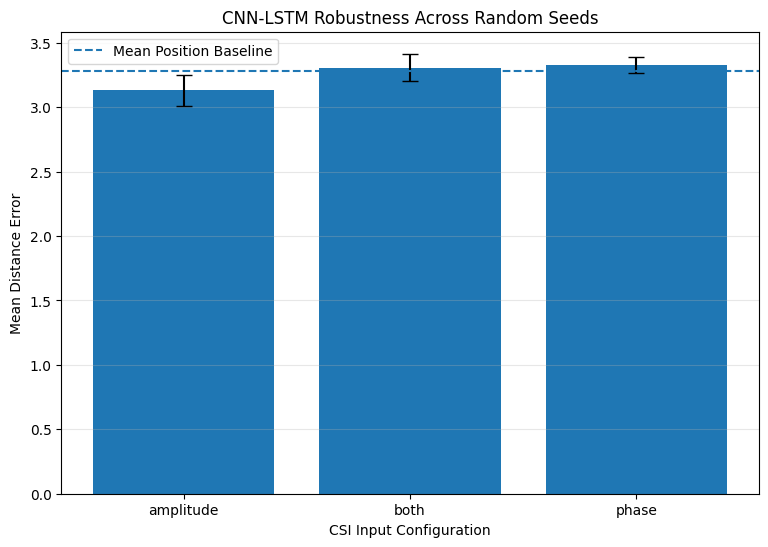

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.bar(
    robustness_summary["Mode"],
    robustness_summary["Mean_MDE"],
    yerr=robustness_summary["Std_MDE"],
    capsize=6
)

plt.axhline(
    y=baseline_distances.mean(),
    linestyle="--",
    label="Mean Position Baseline"
)

plt.xlabel("CSI Input Configuration")
plt.ylabel("Mean Distance Error")

plt.title(
    "CNN-LSTM Robustness Across Random Seeds"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [88]:
robustness_df.to_csv(
    "cnn_lstm_robustness_results.csv",
    index=False
)

robustness_summary.to_csv(
    "cnn_lstm_robustness_summary.csv",
    index=False
)

print("Hasil eksperimen berhasil disimpan")

Hasil eksperimen berhasil disimpan


In [89]:
import os
import numpy as np
import pandas as pd

from scipy.stats import (
    friedmanchisquare,
    wilcoxon
)

from itertools import combinations
from IPython.display import display

SAVE_DIR = "/content/drive/MyDrive/UTS_WiFi_CSI"

RESULTS_PATH = os.path.join(
    SAVE_DIR,
    "multiple_seed_results.csv"
)

df = pd.read_csv(RESULTS_PATH)

print("Total experiments:", len(df))

display(df)

pivot = df.pivot(
    index="Seed",
    columns="Mode",
    values="MDE"
)

pivot = pivot[
    ["amplitude", "phase", "both"]
].dropna()

print("\n=== MDE ACROSS RANDOM SEEDS ===")

display(pivot)

statistic, p_value = friedmanchisquare(
    pivot["amplitude"],
    pivot["phase"],
    pivot["both"]
)

print("\n=== FRIEDMAN TEST ===")

print("Statistic:", statistic)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:

    print(
        "Significant differences detected "
        "among CSI configurations."
    )

else:

    print(
        "No statistically significant "
        "difference detected."
    )

modes = [
    "amplitude",
    "phase",
    "both"
]

results = []

for mode1, mode2 in combinations(modes, 2):

    stat, p = wilcoxon(
        pivot[mode1],
        pivot[mode2],
        alternative="two-sided",
        zero_method="wilcox",
        method="exact"
    )

    results.append({

        "Comparison": f"{mode1} vs {mode2}",

        "Statistic": stat,

        "P-value": p,

        "Mean Difference": (
            pivot[mode1] - pivot[mode2]
        ).mean()

    })


stat_df = pd.DataFrame(results)

from statsmodels.stats.multitest import multipletests

adjusted = multipletests(
    stat_df["P-value"],
    alpha=0.05,
    method="holm"
)

stat_df["Adjusted P-value"] = adjusted[1]

stat_df["Significant"] = adjusted[0]


print("\n=== PAIRWISE STATISTICAL COMPARISON ===")

display(stat_df)

stat_df.to_csv(
    os.path.join(
        SAVE_DIR,
        "statistical_significance_results.csv"
    ),
    index=False
)

print("\nStatistical analysis completed.")

Total experiments: 15


,Mode,Seed,MDE,Median Error,RMSE,Best Validation Loss
0,amplitude,42,3.036905,3.609395,3.371779,1.783364
1,amplitude,123,2.981279,3.225926,3.421130,1.983440
2,amplitude,2024,3.227010,3.886477,3.561136,1.767962
3,amplitude,2025,3.157045,3.574651,3.467994,1.823007
4,amplitude,2026,3.255091,3.426185,3.700313,1.842633
5,phase,42,3.235346,3.673244,3.614044,2.026644
6,phase,123,3.307068,3.381376,3.717235,2.029429
7,phase,2024,3.373870,3.457493,3.768639,2.006581
8,phase,2025,3.343657,3.700262,3.763881,2.057282
9,phase,2026,3.379622,3.522738,3.779741,2.011769



=== MDE ACROSS RANDOM SEEDS ===


Mode,amplitude,phase,both
Seed,,,
42,3.036905,3.235346,3.278524
123,2.981279,3.307068,3.176052
2024,3.227010,3.373870,3.396892
2025,3.157045,3.343657,3.436689
2026,3.255091,3.379622,3.249272



=== FRIEDMAN TEST ===
Statistic: 4.799999999999997
P-value: 0.09071795328941264
No statistically significant difference detected.

=== PAIRWISE STATISTICAL COMPARISON ===


,Comparison,Statistic,P-value,Mean Difference,Adjusted P-value,Significant
0,amplitude vs phase,0.0,0.0625,-0.196447,0.1875,False
1,amplitude vs both,1.0,0.1250,-0.176020,0.2500,False
2,phase vs both,6.0,0.8125,0.020427,0.8125,False



Statistical analysis completed.


In [90]:
import numpy as np
import pandas as pd
import torch
import os

SAVE_DIR = "/content/drive/MyDrive/UTS_WiFi_CSI"

os.makedirs(SAVE_DIR, exist_ok=True)

SPLIT_SEEDS = [42, 123, 2024, 2025, 2026]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

device = DEVICE

print("Device:", DEVICE)

required_variables = [
    "X_train",
    "X_val",
    "X_test",
    "y_train",
    "y_val",
    "y_test"
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:

    raise RuntimeError(
        "Missing variables: "
        + str(missing_variables)
    )

def to_numpy(data):

    if isinstance(data, torch.Tensor):

        return data.detach().cpu().numpy()

    return np.asarray(data)


X_all = np.concatenate(
    [
        to_numpy(X_train),
        to_numpy(X_val),
        to_numpy(X_test)
    ],
    axis=0
).astype(np.float32)

y_all = np.concatenate(
    [
        to_numpy(y_train),
        to_numpy(y_val),
        to_numpy(y_test)
    ],
    axis=0
).astype(np.float32)

print("\n=== DATASET VERIFICATION ===")

print("X_all:", X_all.shape)
print("y_all:", y_all.shape)

assert X_all.ndim == 4

assert X_all.shape[1:] == (6, 60, 30)

assert y_all.ndim == 2

assert y_all.shape[1] == 2

assert len(X_all) == len(y_all)

print("\nDataset dimensions: VALID")

nan_count = np.isnan(X_all).sum()

posinf_count = np.isposinf(X_all).sum()

neginf_count = np.isneginf(X_all).sum()

total_invalid = (
    nan_count
    + posinf_count
    + neginf_count
)

print("\n=== INVALID VALUE ANALYSIS ===")

print("NaN values:", nan_count)

print("Positive infinity:", posinf_count)

print("Negative infinity:", neginf_count)

print("Total invalid values:", total_invalid)

invalid_mask = ~np.isfinite(X_all)

invalid_per_channel = invalid_mask.sum(
    axis=(0, 2, 3)
)

print("\nInvalid values per channel:")

for channel, count in enumerate(
    invalid_per_channel
):

    print(
        f"Channel {channel}: {count}"
    )

invalid_per_location = invalid_mask.sum(
    axis=(1, 2, 3)
)

affected_locations = np.where(
    invalid_per_location > 0
)[0]

print("\nAffected locations:", len(affected_locations))

print(
    "Maximum invalid values in one location:",
    invalid_per_location.max()
)

X_all_clean = X_all.copy()

assert np.isfinite(y_all).all(), (
    "Target coordinates contain NaN or Inf."
)

unique_locations = np.unique(
    y_all,
    axis=0
)

print("\n=== LOCATION VERIFICATION ===")

print(
    "Unique locations:",
    len(unique_locations)
)

assert len(unique_locations) == len(y_all), (
    "Duplicate coordinates detected."
)

print("\n=== FINAL DATASET STATUS ===")

print("X shape:", X_all_clean.shape)

print("Y shape:", y_all.shape)

print(
    "X contains invalid values:",
    not np.isfinite(X_all_clean).all()
)

print(
    "Y finite:",
    np.isfinite(y_all).all()
)

print("\nDataset inspection completed.")
print("Invalid CSI values will be handled after splitting.")

Device: cuda

=== DATASET VERIFICATION ===
X_all: (90, 6, 60, 30)
y_all: (90, 2)

Dataset dimensions: VALID

=== INVALID VALUE ANALYSIS ===
NaN values: 0
Positive infinity: 0
Negative infinity: 261
Total invalid values: 261

Invalid values per channel:
Channel 0: 3
Channel 1: 0
Channel 2: 254
Channel 3: 0
Channel 4: 4
Channel 5: 0

Affected locations: 54
Maximum invalid values in one location: 16

=== LOCATION VERIFICATION ===
Unique locations: 90

=== FINAL DATASET STATUS ===
X shape: (90, 6, 60, 30)
Y shape: (90, 2)
X contains invalid values: True
Y finite: True

Dataset inspection completed.
Invalid CSI values will be handled after splitting.


In [91]:
from torch.utils.data import TensorDataset, DataLoader

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def create_spatial_split(X, y, seed):

    indices = np.arange(len(X))

    train_idx, temp_idx = train_test_split(
        indices,
        train_size=63,
        random_state=seed,
        shuffle=True
    )

    val_idx, test_idx = train_test_split(
        temp_idx,
        train_size=13,
        random_state=seed,
        shuffle=True
    )

    return (
        X[train_idx],
        X[val_idx],
        X[test_idx],
        y[train_idx],
        y[val_idx],
        y[test_idx],
        train_idx,
        val_idx,
        test_idx
    )

def normalize_spatial_data(
    X_train,
    X_val,
    X_test
):
    mean = X_train.mean(
        axis=(0, 2, 3),
        keepdims=True
    )

    std = X_train.std(
        axis=(0, 2, 3),
        keepdims=True
    )

    std = np.maximum(std, 1e-6)

    X_train_norm = (
        X_train - mean
    ) / std

    X_val_norm = (
        X_val - mean
    ) / std

    X_test_norm = (
        X_test - mean
    ) / std

    return (
        X_train_norm.astype(np.float32),
        X_val_norm.astype(np.float32),
        X_test_norm.astype(np.float32)
    )

AMPLITUDE_CHANNELS = [0, 2, 4]


def select_amplitude(X):

    output = np.zeros_like(X)

    output[:, AMPLITUDE_CHANNELS] = (
        X[:, AMPLITUDE_CHANNELS]
    )

    return output

def create_spatial_loader(
    X,
    y,
    shuffle=False
):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )

    return DataLoader(
        dataset,
        batch_size=16,
        shuffle=shuffle,
        num_workers=0
    )


print("Spatial holdout functions ready.")

Spatial holdout functions ready.


In [92]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
import copy
import random
import os

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

device = DEVICE

print("Device:", DEVICE)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def create_spatial_split(X, y, seed=42):

    indices = np.arange(len(X))

    train_idx, temp_idx = train_test_split(
        indices,
        test_size=0.30,
        random_state=seed,
        shuffle=True
    )

    val_idx, test_idx = train_test_split(
        temp_idx,
        test_size=14/27,
        random_state=seed,
        shuffle=True
    )

    return (
        X[train_idx],
        X[val_idx],
        X[test_idx],
        y[train_idx],
        y[val_idx],
        y[test_idx],
        train_idx,
        val_idx,
        test_idx
    )


def normalize_spatial_data(X_train, X_val, X_test):

    X_train = np.asarray(
        X_train, dtype=np.float64
    ).copy()

    X_val = np.asarray(
        X_val, dtype=np.float64
    ).copy()

    X_test = np.asarray(
        X_test, dtype=np.float64
    ).copy()

    # Convert invalid values to NaN
    for X in [X_train, X_val, X_test]:
        X[~np.isfinite(X)] = np.nan

    # Statistics from training only
    valid = np.isfinite(X_train)

    count = valid.sum(
        axis=(0, 2, 3),
        keepdims=True
    )

    if np.any(count == 0):
        raise ValueError(
            "Ada kanal CSI yang seluruh data training-nya invalid."
        )

    train_sum = np.where(
        valid, X_train, 0.0
    ).sum(
        axis=(0, 2, 3),
        keepdims=True
    )

    mean = train_sum / count

    # Imputation using training mean
    X_train = np.where(
        np.isfinite(X_train), X_train, mean
    )

    X_val = np.where(
        np.isfinite(X_val), X_val, mean
    )

    X_test = np.where(
        np.isfinite(X_test), X_test, mean
    )

    std = X_train.std(
        axis=(0, 2, 3),
        keepdims=True
    )

    std = np.maximum(std, 1e-6)

    X_train = ((X_train - mean) / std).astype(np.float32)
    X_val = ((X_val - mean) / std).astype(np.float32)
    X_test = ((X_test - mean) / std).astype(np.float32)

    assert np.isfinite(X_train).all()
    assert np.isfinite(X_val).all()
    assert np.isfinite(X_test).all()

    return X_train, X_val, X_test


def create_spatial_loader(X, y, shuffle=False):

    X = torch.tensor(
        np.array(X, copy=True),
        dtype=torch.float32
    )

    y = torch.tensor(
        np.array(y, copy=True),
        dtype=torch.float32
    )

    dataset = TensorDataset(X, y)

    return DataLoader(
        dataset,
        batch_size=16,
        shuffle=shuffle,
        num_workers=0
    )


print("Preprocessing functions ready.")

Device: cuda
Preprocessing functions ready.


In [93]:
def train_spatial_model(
    model,
    train_loader,
    val_loader,
    epochs=100,
    patience=20,
    lr=0.001
):

    criterion = nn.SmoothL1Loss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    best_val = float("inf")

    best_state = copy.deepcopy(
        model.state_dict()
    )

    patience_counter = 0

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # TRAINING
        model.train()

        train_loss = 0.0
        train_samples = 0

        for inputs, targets in train_loader:

            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(
                outputs,
                targets
            )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite training loss at epoch {epoch+1}"
                )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            batch_size = inputs.size(0)

            train_loss += loss.item() * batch_size
            train_samples += batch_size

        train_loss /= train_samples

        # VALIDATION
        model.eval()

        val_loss = 0.0
        val_samples = 0

        with torch.no_grad():

            for inputs, targets in val_loader:

                inputs = inputs.to(DEVICE)
                targets = targets.to(DEVICE)

                outputs = model(inputs)

                loss = criterion(
                    outputs,
                    targets
                )

                if not torch.isfinite(loss):
                    raise RuntimeError(
                        f"Non-finite validation loss at epoch {epoch+1}"
                    )

                batch_size = inputs.size(0)

                val_loss += loss.item() * batch_size
                val_samples += batch_size

        val_loss /= val_samples

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # SAVE BEST MODEL
        if val_loss < best_val:

            best_val = val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1

        if (epoch + 1) % 10 == 0:

            print(
                f"Epoch {epoch+1}/{epochs} | "
                f"Train: {train_loss:.4f} | "
                f"Val: {val_loss:.4f}"
            )

        # EARLY STOPPING
        if patience_counter >= patience:

            print(
                f"Early stopping at epoch {epoch+1}"
            )

            break

    # RESTORE BEST MODEL
    model.load_state_dict(best_state)

    return model, best_val


print("Training function ready.")

Training function ready.


In [94]:
SEEDS = [42, 123, 2024, 2025, 2026]

results = []

X_all = np.asarray(X_all, dtype=np.float32)
y_all = np.asarray(y_all, dtype=np.float32)

assert X_all.shape[1:] == (6, 60, 30)
assert y_all.shape[1] == 2
assert np.isfinite(y_all).all()

print("Dataset:", X_all.shape)

for seed in SEEDS:

    print("\n" + "=" * 60)
    print("SPATIAL SPLIT SEED:", seed)
    print("=" * 60)

    set_seed(seed)

    (
        X_tr,
        X_va,
        X_te,
        y_tr,
        y_va,
        y_te,
        train_idx,
        val_idx,
        test_idx
    ) = create_spatial_split(
        X_all,
        y_all,
        seed=seed
    )

    (
        X_tr,
        X_va,
        X_te
    ) = normalize_spatial_data(
        X_tr,
        X_va,
        X_te
    )

    print("Train:", X_tr.shape)
    print("Validation:", X_va.shape)
    print("Test:", X_te.shape)

    print(
        "Train finite:",
        np.isfinite(X_tr).all()
    )

    train_loader = create_spatial_loader(
        X_tr, y_tr, shuffle=True
    )

    val_loader = create_spatial_loader(
        X_va, y_va, shuffle=False
    )

    test_loader = create_spatial_loader(
        X_te, y_te, shuffle=False
    )

    model = CSI_CNN_LSTM().to(DEVICE)

    model, best_val = train_spatial_model(
        model,
        train_loader,
        val_loader,
        epochs=100,
        patience=20,
        lr=0.001
    )

    model.eval()

    predictions = []
    targets = []

    with torch.no_grad():

        for inputs, labels in test_loader:

            inputs = inputs.to(DEVICE)

            outputs = model(inputs)

            predictions.append(
                outputs.cpu().numpy()
            )

            targets.append(
                labels.numpy()
            )

    predictions = np.concatenate(
        predictions, axis=0
    )

    targets = np.concatenate(
        targets, axis=0
    )

    distances = np.linalg.norm(
        predictions - targets,
        axis=1
    )

    mde = float(
        np.mean(distances)
    )

    median_error = float(
        np.median(distances)
    )

    rmse = float(
        np.sqrt(np.mean(distances ** 2))
    )

    mean_position = np.mean(
        y_tr,
        axis=0
    )

    baseline_predictions = np.tile(
        mean_position,
        (len(y_te), 1)
    )

    baseline_distances = np.linalg.norm(
        baseline_predictions - y_te,
        axis=1
    )

    baseline_mde = float(
        np.mean(baseline_distances)
    )

    results.append({

        "Seed": seed,
        "CNN_LSTM_MDE": mde,
        "CNN_LSTM_Median": median_error,
        "CNN_LSTM_RMSE": rmse,
        "Baseline_MDE": baseline_mde,
        "Best_Validation_Loss": best_val

    })

    print("\nRESULT")

    print(f"CNN-LSTM MDE: {mde:.4f}")
    print(f"CNN-LSTM RMSE: {rmse:.4f}")
    print(f"Baseline MDE: {baseline_mde:.4f}")

results_df = pd.DataFrame(results)

print("\n=== SPATIAL GENERALIZATION RESULTS ===")

display(results_df)

print("\n=== SUMMARY ===")

summary = results_df[
    [
        "CNN_LSTM_MDE",
        "CNN_LSTM_RMSE",
        "Baseline_MDE"
    ]
].agg(["mean", "std"])

display(summary)

# Save results
SAVE_DIR = "/content/drive/MyDrive/UTS_WiFi_CSI"

os.makedirs(SAVE_DIR, exist_ok=True)

results_df.to_csv(
    os.path.join(
        SAVE_DIR,
        "spatial_generalization_results.csv"
    ),
    index=False
)

print("\nExperiment completed successfully.")

Dataset: (90, 6, 60, 30)

SPATIAL SPLIT SEED: 42
Train: (63, 6, 60, 30)
Validation: (13, 6, 60, 30)
Test: (14, 6, 60, 30)
Train finite: True
Epoch 10/100 | Train: 2.0746 | Val: 2.2210
Epoch 20/100 | Train: 1.8981 | Val: 2.1627
Epoch 30/100 | Train: 1.8870 | Val: 2.1533
Early stopping at epoch 33

RESULT
CNN-LSTM MDE: 3.3537
CNN-LSTM RMSE: 3.5980
Baseline MDE: 3.4233

SPATIAL SPLIT SEED: 123
Train: (63, 6, 60, 30)
Validation: (13, 6, 60, 30)
Test: (14, 6, 60, 30)
Train finite: True
Epoch 10/100 | Train: 1.9809 | Val: 2.4204
Epoch 20/100 | Train: 1.7282 | Val: 2.3461
Epoch 30/100 | Train: 1.7243 | Val: 2.2777
Early stopping at epoch 33

RESULT
CNN-LSTM MDE: 4.3586
CNN-LSTM RMSE: 4.5011
Baseline MDE: 4.3233

SPATIAL SPLIT SEED: 2024
Train: (63, 6, 60, 30)
Validation: (13, 6, 60, 30)
Test: (14, 6, 60, 30)
Train finite: True
Epoch 10/100 | Train: 1.9847 | Val: 1.9073
Epoch 20/100 | Train: 1.9205 | Val: 1.6841
Epoch 30/100 | Train: 1.9096 | Val: 1.6769
Epoch 40/100 | Train: 1.8017 | Val: 1.7

,Seed,CNN_LSTM_MDE,CNN_LSTM_Median,CNN_LSTM_RMSE,Baseline_MDE,Best_Validation_Loss
0,42,3.353686,3.265973,3.597978,3.423284,2.144452
1,123,4.358559,4.489926,4.501144,4.323264,2.112569
2,2024,3.831242,4.190848,4.147821,3.797491,1.676859
3,2025,3.636917,3.393038,3.838233,3.665888,1.509029
4,2026,3.361263,3.211280,3.925871,3.549854,1.373704



=== SUMMARY ===


,CNN_LSTM_MDE,CNN_LSTM_RMSE,Baseline_MDE
mean,3.708333,4.002210,3.751956
std,0.415100,0.341415,0.348118



Experiment completed successfully.


In [95]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
import copy
import random
import os

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

device = DEVICE

print("Device:", DEVICE)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def create_spatial_split(X, y, seed=42):

    indices = np.arange(len(X))

    train_idx, temp_idx = train_test_split(
        indices,
        test_size=0.30,
        random_state=seed,
        shuffle=True
    )

    val_idx, test_idx = train_test_split(
        temp_idx,
        test_size=14/27,
        random_state=seed,
        shuffle=True
    )

    return (
        X[train_idx],
        X[val_idx],
        X[test_idx],
        y[train_idx],
        y[val_idx],
        y[test_idx],
        train_idx,
        val_idx,
        test_idx
    )


def normalize_spatial_data(X_train, X_val, X_test):

    X_train = np.asarray(
        X_train, dtype=np.float64
    ).copy()

    X_val = np.asarray(
        X_val, dtype=np.float64
    ).copy()

    X_test = np.asarray(
        X_test, dtype=np.float64
    ).copy()

    # Convert invalid values to NaN
    for X in [X_train, X_val, X_test]:
        X[~np.isfinite(X)] = np.nan

    # Statistics from training only
    valid = np.isfinite(X_train)

    count = valid.sum(
        axis=(0, 2, 3),
        keepdims=True
    )

    if np.any(count == 0):
        raise ValueError(
            "Ada kanal CSI yang seluruh data training-nya invalid."
        )

    train_sum = np.where(
        valid, X_train, 0.0
    ).sum(
        axis=(0, 2, 3),
        keepdims=True
    )

    mean = train_sum / count

    # Imputation using training mean
    X_train = np.where(
        np.isfinite(X_train), X_train, mean
    )

    X_val = np.where(
        np.isfinite(X_val), X_val, mean
    )

    X_test = np.where(
        np.isfinite(X_test), X_test, mean
    )

    std = X_train.std(
        axis=(0, 2, 3),
        keepdims=True
    )

    std = np.maximum(std, 1e-6)

    X_train = ((X_train - mean) / std).astype(np.float32)
    X_val = ((X_val - mean) / std).astype(np.float32)
    X_test = ((X_test - mean) / std).astype(np.float32)

    assert np.isfinite(X_train).all()
    assert np.isfinite(X_val).all()
    assert np.isfinite(X_test).all()

    return X_train, X_val, X_test


def create_spatial_loader(X, y, shuffle=False):

    X = torch.tensor(
        np.array(X, copy=True),
        dtype=torch.float32
    )

    y = torch.tensor(
        np.array(y, copy=True),
        dtype=torch.float32
    )

    dataset = TensorDataset(X, y)

    return DataLoader(
        dataset,
        batch_size=16,
        shuffle=shuffle,
        num_workers=0
    )


print("Preprocessing functions ready.")


Device: cuda
Preprocessing functions ready.


In [96]:
def train_spatial_model(
    model,
    train_loader,
    val_loader,
    epochs=100,
    patience=20,
    lr=0.001
):

    criterion = nn.SmoothL1Loss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    best_val = float("inf")

    best_state = copy.deepcopy(
        model.state_dict()
    )

    patience_counter = 0

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # TRAINING
        model.train()

        train_loss = 0.0
        train_samples = 0

        for inputs, targets in train_loader:

            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(
                outputs,
                targets
            )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite training loss at epoch {epoch+1}"
                )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            batch_size = inputs.size(0)

            train_loss += loss.item() * batch_size
            train_samples += batch_size

        train_loss /= train_samples

        # VALIDATION
        model.eval()

        val_loss = 0.0
        val_samples = 0

        with torch.no_grad():

            for inputs, targets in val_loader:

                inputs = inputs.to(DEVICE)
                targets = targets.to(DEVICE)

                outputs = model(inputs)

                loss = criterion(
                    outputs,
                    targets
                )

                if not torch.isfinite(loss):
                    raise RuntimeError(
                        f"Non-finite validation loss at epoch {epoch+1}"
                    )

                batch_size = inputs.size(0)

                val_loss += loss.item() * batch_size
                val_samples += batch_size

        val_loss /= val_samples

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # SAVE BEST MODEL
        if val_loss < best_val:

            best_val = val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1

        if (epoch + 1) % 10 == 0:

            print(
                f"Epoch {epoch+1}/{epochs} | "
                f"Train: {train_loss:.4f} | "
                f"Val: {val_loss:.4f}"
            )

        # EARLY STOPPING
        if patience_counter >= patience:

            print(
                f"Early stopping at epoch {epoch+1}"
            )

            break

    # RESTORE BEST MODEL
    model.load_state_dict(best_state)

    return model, best_val


print("Training function ready.")

Training function ready.


In [97]:
import os
import glob
import re
import numpy as np
import pandas as pd

# ==================================================
# 1. FIND DATASET
# ==================================================

# Membatasi pencarian hanya pada direktori ekstraksi utama agar tidak mendeteksi duplikat
search_roots = [
    "/content/wifi_csi"
]

csv_files = []

for root in search_roots:
    csv_files.extend(
        glob.glob(
            os.path.join(root, "**", "antenna_*.csv"),
            recursive=True
        )
    )

csv_files = sorted(set(csv_files))

print("Jumlah CSV ditemukan:", len(csv_files))

if len(csv_files) == 0:
    raise FileNotFoundError(
        "Dataset CSI tidak ditemukan. "
        "Pastikan dataset sudah di-upload atau Drive sudah di-mount."
    )

# ==================================================
# 2. GROUP FILES BY LOCATION
# ==================================================

locations = {}

pattern = re.compile(
    r"^antenna_([123])_(\d+)_(\d+)\.csv$"
)

for file in csv_files:

    filename = os.path.basename(file)

    match = pattern.match(filename)

    if match is None:
        continue

    antenna = int(match.group(1))
    x = int(match.group(2))
    y = int(match.group(3))

    location = (x, y)

    if location not in locations:
        locations[location] = {}

    if antenna in locations[location]:
        raise ValueError(
            f"File duplikat untuk lokasi {location}, "
            f"antena {antenna}"
        )

    locations[location][antenna] = file

print("Jumlah lokasi:", len(locations))

# ==================================================
# 3. LOAD CSI
# ==================================================

X_data = []
y_data = []

amplitude_cols = [
    f"amplitude_{i}" for i in range(30)
]

phase_cols = [
    f"phase_{i}" for i in range(30)
]

for location in sorted(locations.keys()):

    antenna_files = locations[location]

    if set(antenna_files.keys()) != {1, 2, 3}:
        raise ValueError(
            f"Antena tidak lengkap pada lokasi {location}"
        )

    channels = []

    for antenna in [1, 2, 3]:

        df = pd.read_csv(
            antenna_files[antenna]
        )

        required_cols = amplitude_cols + phase_cols

        missing = [
            col for col in required_cols
            if col not in df.columns
        ]

        if missing:
            raise ValueError(
                f"Kolom hilang: {missing}"
            )

        if len(df) != 60:
            raise ValueError(
                f"Jumlah time step bukan 60: "
                f"{antenna_files[antenna]}"
            )

        amplitude = df[
            amplitude_cols
        ].to_numpy(dtype=np.float64)

        phase = df[
            phase_cols
        ].to_numpy(dtype=np.float64)

        channels.append(amplitude)
        channels.append(phase)

    sample = np.stack(
        channels,
        axis=0
    )

    X_data.append(sample)
    y_data.append(location)

# ==================================================
# 4. BUILD ARRAYS
# ==================================================

X_all = np.stack(
    X_data,
    axis=0
).astype(np.float64)

y_all = np.array(
    y_data,
    dtype=np.float32
)

# ==================================================
# 5. DATA VERIFICATION
# ==================================================

print("\n=== DATASET VERIFICATION ===")

print("X_all:", X_all.shape)
print("y_all:", y_all.shape)

print(
    "NaN count:",
    np.isnan(X_all).sum()
)

print(
    "Inf count:",
    np.isinf(X_all).sum()
)

print(
    "Finite targets:",
    np.isfinite(y_all).all()
)

assert X_all.shape == (90, 6, 60, 30)
assert y_all.shape == (90, 2)
assert np.isfinite(y_all).all()

print("\nDataset reconstruction completed.")

Jumlah CSV ditemukan: 270
Jumlah lokasi: 90

=== DATASET VERIFICATION ===
X_all: (90, 6, 60, 30)
y_all: (90, 2)
NaN count: 0
Inf count: 261
Finite targets: True

Dataset reconstruction completed.


In [98]:
import numpy as np

# ==================================================
# CELL: CSI DATA CLEANING
# ==================================================

print("=== BEFORE CLEANING ===")

print("Shape:", X_all.shape)
print("NaN:", np.isnan(X_all).sum())
print("Inf:", np.isinf(X_all).sum())

# Salin data agar dataset asli tidak berubah
X_all_clean = X_all.copy().astype(np.float64)

# ==================================================
# 1. REPLACE NON-FINITE VALUES
# ==================================================

# Setiap channel diproses secara terpisah
# Urutan channel:
# 0 = Antenna 1 Amplitude
# 1 = Antenna 1 Phase
# 2 = Antenna 2 Amplitude
# 3 = Antenna 2 Phase
# 4 = Antenna 3 Amplitude
# 5 = Antenna 3 Phase

for sample_idx in range(X_all_clean.shape[0]):

    for channel_idx in range(X_all_clean.shape[1]):

        channel = X_all_clean[
            sample_idx,
            channel_idx
        ]

        finite_mask = np.isfinite(channel)

        if finite_mask.all():
            continue

        # Gunakan median nilai valid pada channel
        if finite_mask.any():

            replacement = np.median(
                channel[finite_mask]
            )

        else:

            # Jika seluruh channel tidak valid,
            # hentikan proses untuk pemeriksaan
            raise ValueError(
                f"Channel tidak memiliki nilai valid: "
                f"sample={sample_idx}, "
                f"channel={channel_idx}"
            )

        channel[~finite_mask] = replacement

        X_all_clean[
            sample_idx,
            channel_idx
        ] = channel

# ==================================================
# 2. CONVERT TO FLOAT32
# ==================================================

X_all_clean = X_all_clean.astype(
    np.float32
)

# ==================================================
# 3. FINAL VALIDATION
# ==================================================

print("\n=== AFTER CLEANING ===")

print("Shape:", X_all_clean.shape)

print(
    "NaN:",
    np.isnan(X_all_clean).sum()
)

print(
    "Inf:",
    np.isinf(X_all_clean).sum()
)

print(
    "All finite:",
    np.isfinite(X_all_clean).all()
)

assert X_all_clean.shape == (
    90, 6, 60, 30
)

assert np.isfinite(X_all_clean).all()

assert np.isfinite(y_all).all()

print("\nCSI DATA CLEANING SUCCESSFUL")

# ==================================================
# 4. UPDATE WORKING DATASET
# ==================================================

X_all = X_all_clean

print("\nDataset ready for spatial splitting.")

print("X_all:", X_all.shape)
print("y_all:", y_all.shape)

=== BEFORE CLEANING ===
Shape: (90, 6, 60, 30)
NaN: 0
Inf: 261

=== AFTER CLEANING ===
Shape: (90, 6, 60, 30)
NaN: 0
Inf: 0
All finite: True

CSI DATA CLEANING SUCCESSFUL

Dataset ready for spatial splitting.
X_all: (90, 6, 60, 30)
y_all: (90, 2)


=== SPATIAL DATA SPLIT ===
Train: (63, 6, 60, 30)
Validation: (13, 6, 60, 30)
Test: (14, 6, 60, 30)

Location overlap: NONE
Train normalized: (63, 6, 60, 30), finite: True
Validation normalized: (13, 6, 60, 30), finite: True
Test normalized: (14, 6, 60, 30), finite: True

Training channel means: [ 1.1889476e-06  5.0458957e-09  2.5834987e-07  2.0839551e-08
 -6.3780124e-07  6.0550751e-09]

Training channel stds: [1.         0.99999994 1.         0.9999999  0.9999998  0.99999994]


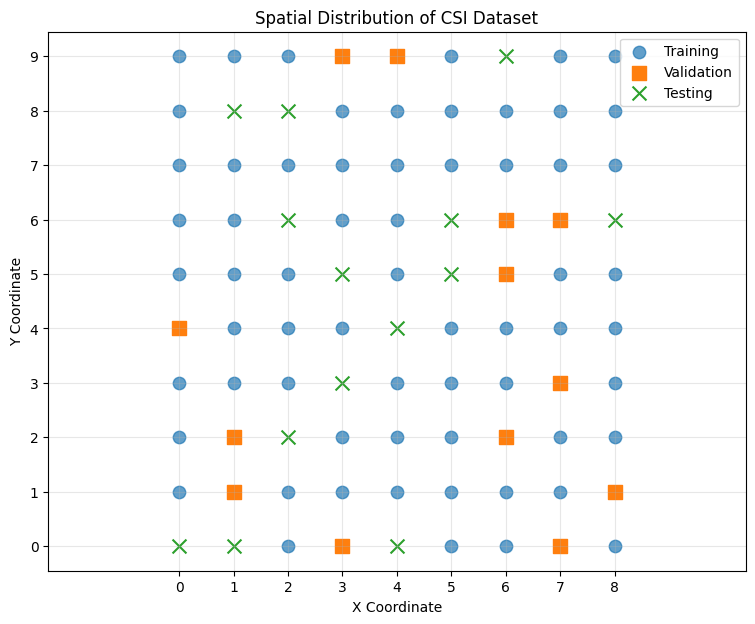


SPATIAL SPLITTING COMPLETED


In [99]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# ==================================================
# 1. VERIFY DATASET
# ==================================================

assert X_all.shape == (90, 6, 60, 30)
assert y_all.shape == (90, 2)
assert np.isfinite(X_all).all()
assert np.isfinite(y_all).all()

# ==================================================
# 2. SPLIT UNIQUE LOCATIONS
# ==================================================

SEED = 42

indices = np.arange(len(y_all))

# 70% training, 30% temporary
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    shuffle=True
)

# Temporary dibagi menjadi validation dan test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    shuffle=True
)

X_train = X_all[train_idx].copy()
X_val = X_all[val_idx].copy()
X_test = X_all[test_idx].copy()

y_train = y_all[train_idx].copy()
y_val = y_all[val_idx].copy()
y_test = y_all[test_idx].copy()

print("=== SPATIAL DATA SPLIT ===")

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# ==================================================
# 3. VERIFY LOCATION SEPARATION
# ==================================================

train_locations = set(map(tuple, y_train))
val_locations = set(map(tuple, y_val))
test_locations = set(map(tuple, y_test))

assert train_locations.isdisjoint(val_locations)
assert train_locations.isdisjoint(test_locations)
assert val_locations.isdisjoint(test_locations)

print("\nLocation overlap: NONE")

# ==================================================
# 4. NORMALIZATION USING TRAINING DATA
# ==================================================

# Statistik dihitung per channel
# Hanya menggunakan training data

mean = X_train.mean(
    axis=(0, 2, 3),
    keepdims=True
)

std = X_train.std(
    axis=(0, 2, 3),
    keepdims=True
)

std = np.maximum(std, 1e-6)

X_train_normalized = (
    (X_train - mean) / std
).astype(np.float32)

X_val_normalized = (
    (X_val - mean) / std
).astype(np.float32)

X_test_normalized = (
    (X_test - mean) / std
).astype(np.float32)

# ==================================================
# 5. VALIDATE NORMALIZATION
# ==================================================

for name, data in [
    ("Train", X_train_normalized),
    ("Validation", X_val_normalized),
    ("Test", X_test_normalized)
]:
    assert np.isfinite(data).all()
    print(
        f"{name} normalized: {data.shape}, "
        f"finite: {np.isfinite(data).all()}"
    )

print("\nTraining channel means:",
      X_train_normalized.mean(axis=(0, 2, 3)))

print("\nTraining channel stds:",
      X_train_normalized.std(axis=(0, 2, 3)))

# ==================================================
# 6. VISUALIZE SPATIAL DISTRIBUTION
# ==================================================

plt.figure(figsize=(9, 7))

plt.scatter(
    y_train[:, 0],
    y_train[:, 1],
    label="Training",
    marker="o",
    s=80,
    alpha=0.7
)

plt.scatter(
    y_val[:, 0],
    y_val[:, 1],
    label="Validation",
    marker="s",
    s=100
)

plt.scatter(
    y_test[:, 0],
    y_test[:, 1],
    label="Testing",
    marker="x",
    s=100
)

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.title("Spatial Distribution of CSI Dataset")

plt.xticks(range(9))
plt.yticks(range(10))

plt.grid(alpha=0.3)
plt.legend()
plt.axis("equal")
plt.show()

print("\nSPATIAL SPLITTING COMPLETED")

In [100]:
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader

# ==================================================
# 1. CONFIGURATION
# ==================================================

SEED = 42
BATCH_SIZE = 16
EPOCHS = 100
PATIENCE = 15
LEARNING_RATE = 0.001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ==================================================
# 2. CREATE DATA LOADERS
# ==================================================

def make_loader(X, y, shuffle=False):

    X_tensor = torch.tensor(
        X, dtype=torch.float32
    )

    y_tensor = torch.tensor(
        y, dtype=torch.float32
    )

    dataset = TensorDataset(
        X_tensor, y_tensor
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )


train_loader = make_loader(
    X_train_normalized, y_train, True
)

val_loader = make_loader(
    X_val_normalized, y_val
)

test_loader = make_loader(
    X_test_normalized, y_test
)

# ==================================================
# 3. CNN-LSTM ARCHITECTURE
# ==================================================

class CSI_CNN_LSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv1d(6, 32, 3, padding=1),
            nn.ReLU(),

            nn.Conv1d(32, 64, 3, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=64,
            batch_first=True
        )

        self.regressor = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )

    def forward(self, x):

        # x: (batch, 6, 60, 30)

        batch, channels, time, subcarriers = x.shape

        # CNN extracts subcarrier features
        x = x.permute(0, 2, 1, 3)

        x = x.reshape(
            batch * time,
            channels,
            subcarriers
        )

        x = self.cnn(x)

        x = x.reshape(
            batch, time, 64
        )

        # LSTM processes temporal sequence
        x, _ = self.lstm(x)

        x = x[:, -1, :]

        return self.regressor(x)

Device: cuda


In [101]:
import torch

print("CUDA Available:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA Available: True
Device: cuda
GPU: Tesla T4


In [102]:
required = [
    "X_train_normalized",
    "X_val_normalized",
    "X_test_normalized",
    "y_train",
    "y_val",
    "y_test"
]

print("=== DATASET CHECK ===")

for name in required:
    if name in globals():
        print(f"[OK] {name}: {globals()[name].shape}")
    else:
        print(f"[MISSING] {name}")

=== DATASET CHECK ===
[OK] X_train_normalized: (63, 6, 60, 30)
[OK] X_val_normalized: (13, 6, 60, 30)
[OK] X_test_normalized: (14, 6, 60, 30)
[OK] y_train: (63, 2)
[OK] y_val: (13, 2)
[OK] y_test: (14, 2)


In [103]:
SEED = 42
BATCH_SIZE = 16
EPOCHS = 100
PATIENCE = 15
LEARNING_RATE = 0.001

device = torch.device("cuda")

print("Training device:", device)

Training device: cuda


Training device: cuda
Epoch [10/100] | Train: 2.1353 | Val: 2.1450
Epoch [20/100] | Train: 1.9002 | Val: 2.0915
Epoch [30/100] | Train: 1.9007 | Val: 2.0909
Early stopping at epoch 38

=== TRAINING COMPLETED ===
Best Epoch: 23
Best Validation Loss: 2.0748486518859863


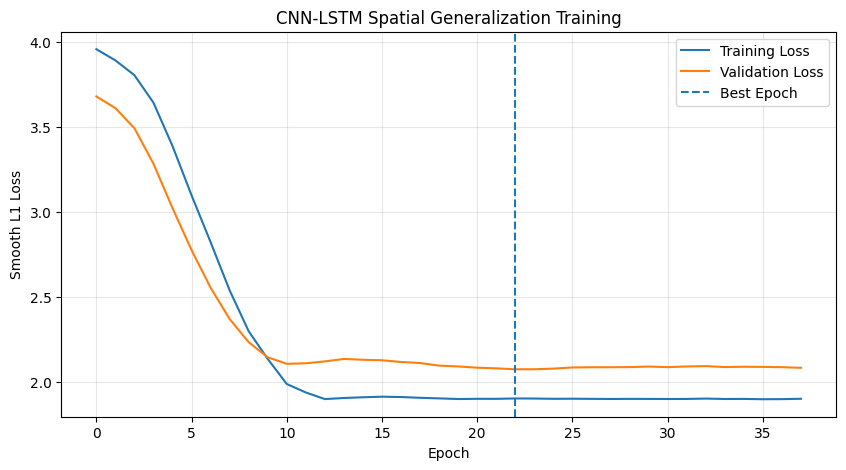


=== SPATIAL GENERALIZATION RESULTS ===
MDE: 3.2830
Median Error: 3.6594
Position RMSE: 3.7084


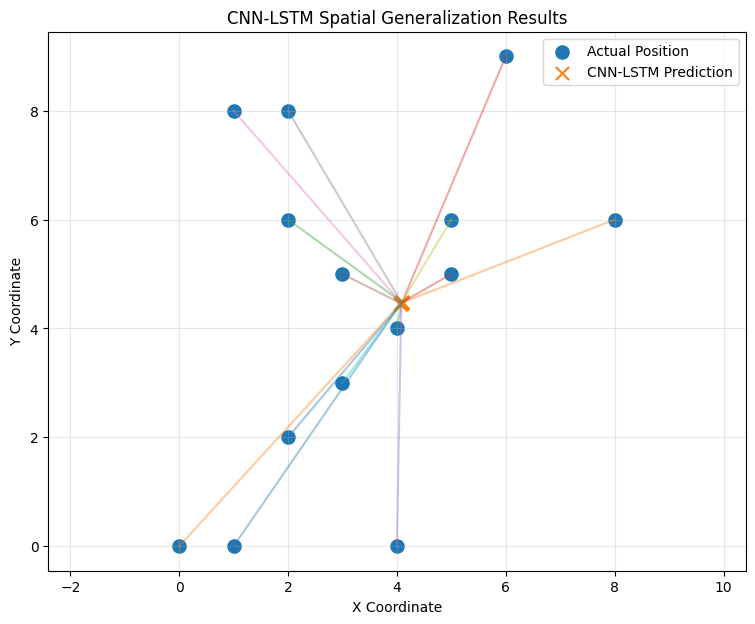

In [104]:
import torch
import torch.nn as nn
import numpy as np
import random
import copy
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader

# ==================================================
# 1. CONFIGURATION
# ==================================================

SEED = 42
BATCH_SIZE = 16
EPOCHS = 100
PATIENCE = 15
LEARNING_RATE = 0.001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Training device:", device)

# ==================================================
# 2. DATA LOADERS
# ==================================================

def make_loader(X, y, shuffle=False):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )

train_loader = make_loader(
    X_train_normalized, y_train, True
)

val_loader = make_loader(
    X_val_normalized, y_val
)

test_loader = make_loader(
    X_test_normalized, y_test
)

# ==================================================
# 3. CNN-LSTM MODEL
# ==================================================

class CSI_CNN_LSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv1d(6, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )

        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=64,
            batch_first=True
        )

        self.regressor = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )

    def forward(self, x):

        batch, channels, time, subcarriers = x.shape

        x = x.permute(0, 2, 1, 3)

        x = x.reshape(
            batch * time,
            channels,
            subcarriers
        )

        x = self.cnn(x)

        x = x.reshape(batch, time, 64)

        x, _ = self.lstm(x)

        x = x[:, -1, :]

        return self.regressor(x)


model = CSI_CNN_LSTM().to(device)

criterion = nn.SmoothL1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# ==================================================
# 4. TRAINING WITH EARLY STOPPING
# ==================================================

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
best_epoch = 0

patience_counter = 0

for epoch in range(EPOCHS):

    model.train()
    train_loss_sum = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        if not torch.isfinite(loss):
            raise ValueError("Non-finite training loss")

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(X_batch)

    train_loss = train_loss_sum / len(train_loader.dataset)

    model.eval()
    val_loss_sum = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            if not torch.isfinite(loss):
                raise ValueError("Non-finite validation loss")

            val_loss_sum += loss.item() * len(X_batch)

    val_loss = val_loss_sum / len(val_loader.dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_state = copy.deepcopy(
            model.state_dict()
        )

        patience_counter = 0

    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}"
        )

    if patience_counter >= PATIENCE:

        print(f"Early stopping at epoch {epoch+1}")
        break

# ==================================================
# 5. RESTORE AND SAVE BEST MODEL
# ==================================================

model.load_state_dict(best_state)

torch.save(
    model.state_dict(),
    "/content/best_spatial_cnn_lstm.pth"
)

print("\n=== TRAINING COMPLETED ===")
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)

# ==================================================
# 6. TRAINING VISUALIZATION
# ==================================================

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.axvline(
    best_epoch - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Smooth L1 Loss")
plt.title("CNN-LSTM Spatial Generalization Training")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

# ==================================================
# 7. TEST EVALUATION
# ==================================================

model.eval()

predictions_all = []
targets_all = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        predictions = model(X_batch)

        predictions_all.append(
            predictions.cpu().numpy()
        )

        targets_all.append(
            y_batch.numpy()
        )

predictions_all = np.concatenate(predictions_all)
targets_all = np.concatenate(targets_all)

distances = np.linalg.norm(
    predictions_all - targets_all,
    axis=1
)

mde = float(np.mean(distances))
median_error = float(np.median(distances))
rmse = float(np.sqrt(np.mean(distances ** 2)))

print("\n=== SPATIAL GENERALIZATION RESULTS ===")

print(f"MDE: {mde:.4f}")
print(f"Median Error: {median_error:.4f}")
print(f"Position RMSE: {rmse:.4f}")

# ==================================================
# 8. VISUALIZE PREDICTION RESULTS
# ==================================================

plt.figure(figsize=(9, 7))

plt.scatter(
    targets_all[:, 0],
    targets_all[:, 1],
    label="Actual Position",
    s=90
)

plt.scatter(
    predictions_all[:, 0],
    predictions_all[:, 1],
    marker="x",
    label="CNN-LSTM Prediction",
    s=90
)

for actual, predicted in zip(
    targets_all, predictions_all
):
    plt.plot(
        [actual[0], predicted[0]],
        [actual[1], predicted[1]],
        alpha=0.4
    )

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("CNN-LSTM Spatial Generalization Results")
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.show()

=== PREDICTION DISTRIBUTION ===
Prediction mean: [4.08279   4.4672313]
Prediction std: [0.00823704 0.0083319 ]
Actual mean: [3.2857144 4.428571 ]
Actual std: [2.118914  2.9450758]

=== BASELINE COMPARISON ===


,Model,MDE,Median Error,Position RMSE
0,Mean Position Baseline,3.283364,3.636611,3.715947
1,CNN-LSTM,3.282974,3.659431,3.708396


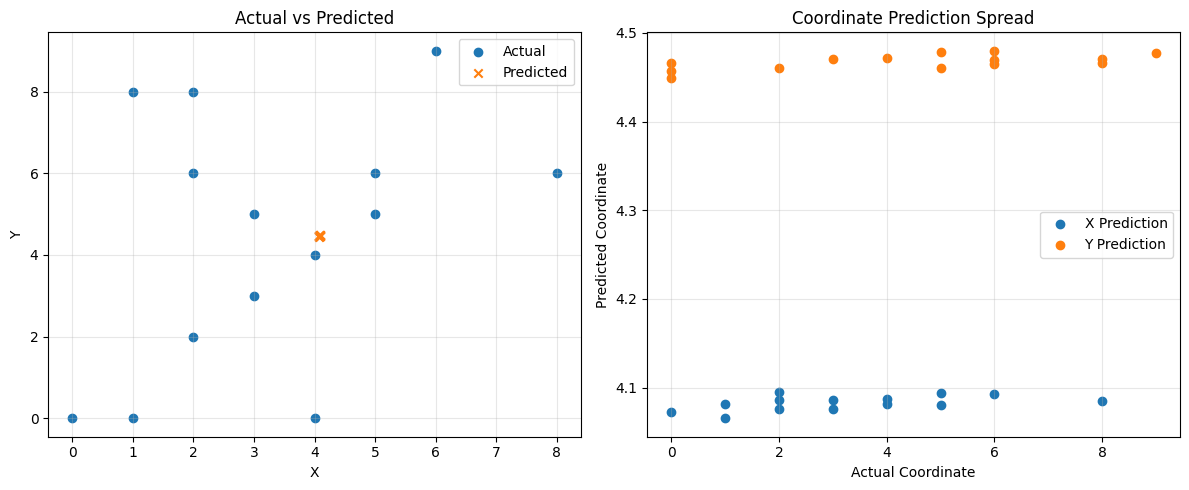

In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. VERIFY PREDICTION DISTRIBUTION
# ==========================================

pred = np.asarray(predictions_all)
actual = np.asarray(targets_all)

assert pred.shape == actual.shape
assert pred.shape[1] == 2

assert np.isfinite(pred).all()
assert np.isfinite(actual).all()

print("=== PREDICTION DISTRIBUTION ===")

print("Prediction mean:", pred.mean(axis=0))
print("Prediction std:", pred.std(axis=0))

print("Actual mean:", actual.mean(axis=0))
print("Actual std:", actual.std(axis=0))

# ==========================================
# 2. MEAN POSITION BASELINE
# ==========================================

train_positions = np.asarray(y_train)

baseline_position = train_positions.mean(axis=0)

baseline_predictions = np.repeat(
    baseline_position[None, :],
    len(actual),
    axis=0
)

baseline_distances = np.linalg.norm(
    baseline_predictions - actual,
    axis=1
)

model_distances = np.linalg.norm(
    pred - actual,
    axis=1
)

# ==========================================
# 3. METRIC COMPARISON
# ==========================================

def calculate_metrics(distances):

    return {
        "MDE": np.mean(distances),
        "Median Error": np.median(distances),
        "Position RMSE": np.sqrt(
            np.mean(distances ** 2)
        )
    }

results = pd.DataFrame([
    {
        "Model": "Mean Position Baseline",
        **calculate_metrics(baseline_distances)
    },
    {
        "Model": "CNN-LSTM",
        **calculate_metrics(model_distances)
    }
])

print("\n=== BASELINE COMPARISON ===")
display(results)

# ==========================================
# 4. PREDICTION SPREAD
# ==========================================

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5)
)

axes[0].scatter(
    actual[:, 0],
    actual[:, 1],
    label="Actual"
)

axes[0].scatter(
    pred[:, 0],
    pred[:, 1],
    marker="x",
    label="Predicted"
)

axes[0].set_title("Actual vs Predicted")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(
    actual[:, 0],
    pred[:, 0],
    label="X Prediction"
)

axes[1].scatter(
    actual[:, 1],
    pred[:, 1],
    label="Y Prediction"
)

axes[1].set_title("Coordinate Prediction Spread")
axes[1].set_xlabel("Actual Coordinate")
axes[1].set_ylabel("Predicted Coordinate")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Amplitude Features
Spearman correlation: 0.3020
P-value: 0.000000

Phase Features
Spearman correlation: 0.2703
P-value: 0.000000


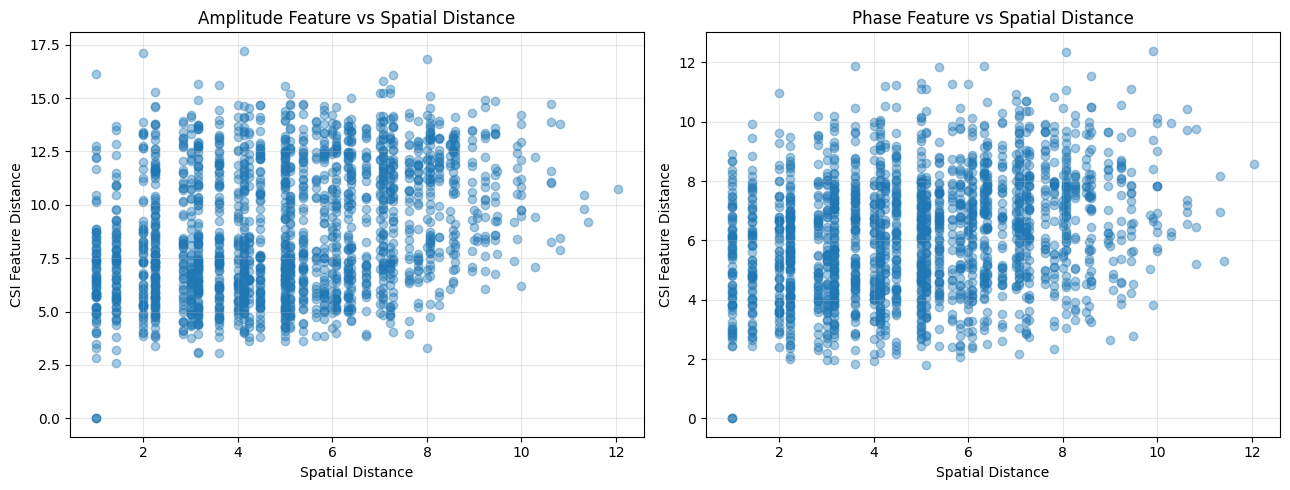

In [106]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

# ==========================================
# CSI FEATURE DISCRIMINABILITY ANALYSIS
# ==========================================

X = np.asarray(X_train_normalized, dtype=np.float64)
y = np.asarray(y_train, dtype=np.float64)

assert X.ndim == 4
assert X.shape[1:] == (6, 60, 30)
assert len(X) == len(y)
assert np.isfinite(X).all()
assert np.isfinite(y).all()

# ==========================================
# 1. EXTRACT CSI FEATURES
# ==========================================

# Amplitude dari tiga antena
amplitude = X[:, :3, :, :]

# Phase dari tiga antena
phase = X[:, 3:, :, :]

# Mean dan standard deviation temporal
amp_mean = amplitude.mean(axis=2)
amp_std = amplitude.std(axis=2)

phase_mean = phase.mean(axis=2)
phase_std = phase.std(axis=2)

# Flatten fitur
amp_features = np.concatenate([
    amp_mean.reshape(len(X), -1),
    amp_std.reshape(len(X), -1)
], axis=1)

phase_features = np.concatenate([
    phase_mean.reshape(len(X), -1),
    phase_std.reshape(len(X), -1)
], axis=1)

# ==========================================
# 2. DISTANCE CORRELATION
# ==========================================

spatial_distance = pdist(
    y,
    metric="euclidean"
)

def analyze_features(features, name):

    feature_distance = pdist(
        features,
        metric="euclidean"
    )

    if np.std(feature_distance) < 1e-12:
        print(f"{name}: Feature distances constant")
        return np.nan

    correlation, p_value = spearmanr(
        spatial_distance,
        feature_distance
    )

    print(f"\n{name}")
    print(f"Spearman correlation: {correlation:.4f}")
    print(f"P-value: {p_value:.6f}")

    return correlation

amp_corr = analyze_features(
    amp_features,
    "Amplitude Features"
)

phase_corr = analyze_features(
    phase_features,
    "Phase Features"
)

# ==========================================
# 3. VISUALIZATION
# ==========================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

axes[0].scatter(
    spatial_distance,
    pdist(amp_features),
    alpha=0.4
)

axes[0].set_title(
    "Amplitude Feature vs Spatial Distance"
)

axes[0].set_xlabel("Spatial Distance")
axes[0].set_ylabel("CSI Feature Distance")
axes[0].grid(alpha=0.3)

axes[1].scatter(
    spatial_distance,
    pdist(phase_features),
    alpha=0.4
)

axes[1].set_title(
    "Phase Feature vs Spatial Distance"
)

axes[1].set_xlabel("Spatial Distance")
axes[1].set_ylabel("CSI Feature Distance")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [107]:
import numpy as np
import pandas as pd

from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

# ==========================================
# 1. FEATURE EXTRACTION
# ==========================================

def extract_amplitude_features(X):

    X = np.asarray(X, dtype=np.float64)

    assert X.ndim == 4
    assert X.shape[1] == 6
    assert np.isfinite(X).all()

    amplitude = X[:, :3, :, :]

    mean_features = amplitude.mean(axis=2)
    std_features = amplitude.std(axis=2)

    features = np.concatenate([
        mean_features.reshape(len(X), -1),
        std_features.reshape(len(X), -1)
    ], axis=1)

    return features


Xtr = extract_amplitude_features(X_train_normalized)
Xva = extract_amplitude_features(X_val_normalized)
Xte = extract_amplitude_features(X_test_normalized)

# ==========================================
# 2. FEATURE STANDARDIZATION
# ==========================================

scaler = StandardScaler()

Xtr = scaler.fit_transform(Xtr)
Xva = scaler.transform(Xva)
Xte = scaler.transform(Xte)

Xtr = np.nan_to_num(Xtr)
Xva = np.nan_to_num(Xva)
Xte = np.nan_to_num(Xte)

print("Training features:", Xtr.shape)
print("Validation features:", Xva.shape)
print("Testing features:", Xte.shape)

# ==========================================
# 3. KNN HYPERPARAMETER SELECTION
# ==========================================

k_values = [1, 3, 5, 7, 9, 11, 15]

validation_results = []

for k in k_values:

    knn = KNeighborsRegressor(
        n_neighbors=k,
        weights="distance"
    )

    knn.fit(Xtr, y_train)

    pred_val = knn.predict(Xva)

    distances = np.linalg.norm(
        pred_val - y_val,
        axis=1
    )

    mde = np.mean(distances)

    validation_results.append({
        "K": k,
        "Validation MDE": mde
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

best_k = int(
    validation_df.loc[
        validation_df["Validation MDE"].idxmin(),
        "K"
    ]
)

print("Best K:", best_k)

# ==========================================
# 4. FINAL TEST EVALUATION
# ==========================================

knn = KNeighborsRegressor(
    n_neighbors=best_k,
    weights="distance"
)

knn.fit(Xtr, y_train)

pred_test = knn.predict(Xte)

distances = np.linalg.norm(
    pred_test - y_test,
    axis=1
)

mde = np.mean(distances)
median_error = np.median(distances)
rmse = np.sqrt(np.mean(distances ** 2))

print("\n=== KNN AMPLITUDE RESULTS ===")
print(f"MDE: {mde:.4f}")
print(f"Median Error: {median_error:.4f}")
print(f"Position RMSE: {rmse:.4f}")

# ==========================================
# 5. COMPARE WITH BASELINE
# ==========================================

baseline_position = np.mean(y_train, axis=0)

baseline_pred = np.tile(
    baseline_position,
    (len(y_test), 1)
)

baseline_distances = np.linalg.norm(
    baseline_pred - y_test,
    axis=1
)

comparison = pd.DataFrame([
    {
        "Model": "Mean Position Baseline",
        "MDE": np.mean(baseline_distances),
        "RMSE": np.sqrt(
            np.mean(baseline_distances ** 2)
        )
    },
    {
        "Model": "KNN Amplitude",
        "MDE": mde,
        "RMSE": rmse
    }
])

display(comparison)

Training features: (63, 180)
Validation features: (13, 180)
Testing features: (14, 180)


,K,Validation MDE
0,1,3.941502
1,3,3.527630
2,5,3.308755
3,7,3.495000
4,9,3.303684
5,11,3.369810
6,15,3.414371


Best K: 9

=== KNN AMPLITUDE RESULTS ===
MDE: 3.6635
Median Error: 3.8344
Position RMSE: 3.9211


,Model,MDE,RMSE
0,Mean Position Baseline,3.283364,3.715947
1,KNN Amplitude,3.663494,3.921126


=== CSI VARIABILITY ANALYSIS ===
Mean spatial std: 0.5762384550042636
Median spatial std: 0.6377036356710898
Mean temporal std: 0.4368353092720516
Spatial / Temporal ratio: 1.3191205691987438


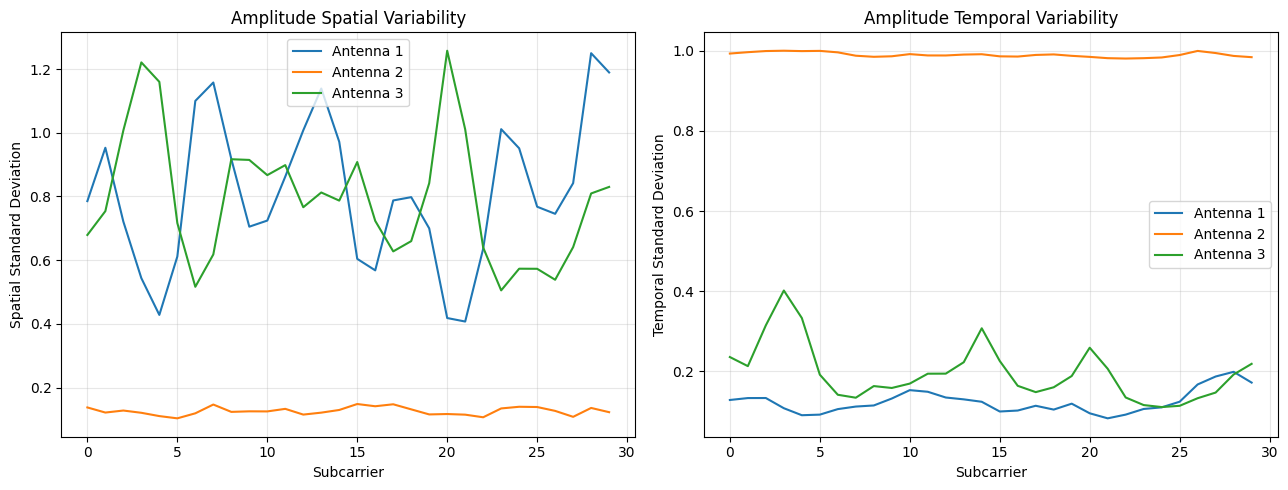

In [108]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# CSI FEATURE VARIABILITY ANALYSIS
# ==========================================

X = np.asarray(
    X_train_normalized,
    dtype=np.float64
)

assert X.shape[1:] == (6, 60, 30)
assert np.isfinite(X).all()

# Amplitude channels
amplitude = X[:, :3, :, :]

# Rata-rata temporal
amp_mean = amplitude.mean(axis=2)

# Variasi antar lokasi
spatial_std = amp_mean.std(axis=0)

# Variasi temporal
temporal_std = amplitude.std(axis=2)

print("=== CSI VARIABILITY ANALYSIS ===")

print(
    "Mean spatial std:",
    spatial_std.mean()
)

print(
    "Median spatial std:",
    np.median(spatial_std)
)

print(
    "Mean temporal std:",
    temporal_std.mean()
)

print(
    "Spatial / Temporal ratio:",
    spatial_std.mean() /
    (temporal_std.mean() + 1e-8)
)

# ==========================================
# VISUALIZATION
# ==========================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

for antenna in range(3):

    axes[0].plot(
        spatial_std[antenna],
        label=f"Antenna {antenna+1}"
    )

axes[0].set_title(
    "Amplitude Spatial Variability"
)

axes[0].set_xlabel("Subcarrier")
axes[0].set_ylabel("Spatial Standard Deviation")
axes[0].legend()
axes[0].grid(alpha=0.3)

for antenna in range(3):

    axes[1].plot(
        temporal_std[:, antenna, :].mean(axis=0),
        label=f"Antenna {antenna+1}"
    )

axes[1].set_title(
    "Amplitude Temporal Variability"
)

axes[1].set_xlabel("Subcarrier")
axes[1].set_ylabel("Temporal Standard Deviation")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

=== ANTENNA DISCRIMINABILITY ===


,Antenna,Spatial_STD,Temporal_STD,Discriminability_Ratio
0,1,0.810004,0.123841,6.618077
1,2,0.126379,0.990240,0.127647
2,3,0.792332,0.196425,4.205352


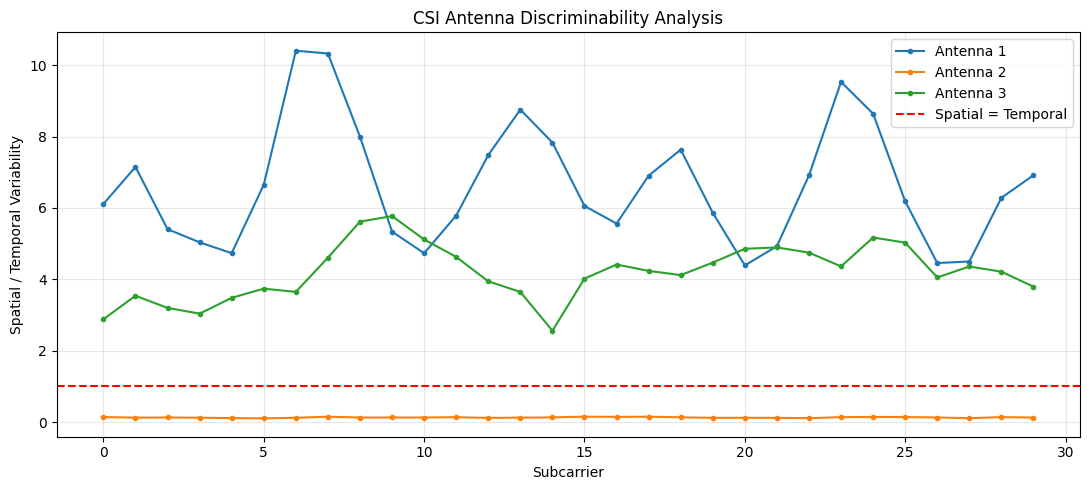


=== ANTENNA RANKING ===


,Antenna,Spatial_STD,Temporal_STD,Discriminability_Ratio
0,1,0.810004,0.123841,6.618077
2,3,0.792332,0.196425,4.205352
1,2,0.126379,0.990240,0.127647


In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# ANTENNA DISCRIMINABILITY ANALYSIS
# ==========================================

X = np.asarray(
    X_train_normalized,
    dtype=np.float64
)

assert X.shape[1:] == (6, 60, 30)
assert np.isfinite(X).all()

amplitude = X[:, :3, :, :]

# Mean amplitude setiap lokasi
location_mean = amplitude.mean(axis=2)

# Spatial variability per antena dan subcarrier
spatial_std = location_mean.std(axis=0)

# Temporal variability per lokasi
temporal_std = amplitude.std(axis=2)

# Rata-rata temporal variability antarlokasi
temporal_std_mean = temporal_std.mean(axis=0)

# Discriminability ratio
epsilon = 1e-8

discriminability = (
    spatial_std /
    (temporal_std_mean + epsilon)
)

# ==========================================
# ANTENNA SUMMARY
# ==========================================

results = []

for antenna in range(3):

    results.append({
        "Antenna": antenna + 1,
        "Spatial_STD": spatial_std[antenna].mean(),
        "Temporal_STD": temporal_std_mean[antenna].mean(),
        "Discriminability_Ratio":
            discriminability[antenna].mean()
    })

antenna_df = pd.DataFrame(results)

print("=== ANTENNA DISCRIMINABILITY ===")
display(antenna_df)

# ==========================================
# VISUALIZATION
# ==========================================

plt.figure(figsize=(11, 5))

for antenna in range(3):

    plt.plot(
        discriminability[antenna],
        marker="o",
        markersize=3,
        label=f"Antenna {antenna + 1}"
    )

plt.axhline(
    1.0,
    color="red",
    linestyle="--",
    label="Spatial = Temporal"
)

plt.xlabel("Subcarrier")
plt.ylabel("Spatial / Temporal Variability")
plt.title("CSI Antenna Discriminability Analysis")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# RANKING
# ==========================================

antenna_ranking = antenna_df.sort_values(
    "Discriminability_Ratio",
    ascending=False
)

print("\n=== ANTENNA RANKING ===")
display(antenna_ranking)

In [110]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, TensorDataset

# ==========================================
# ANTENNA ABLATION STUDY
# ==========================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", DEVICE)

# Amplitude channels assumed at indices 0, 1, 2
# Phase channels assumed at indices 3, 4, 5
# Verify channel ordering before running.

antenna_configs = {
    "Antenna 1": [0],
    "Antenna 2": [1],
    "Antenna 3": [2],
    "Antenna 1+3": [0, 2],
    "All Antennas": [0, 1, 2]
}

def create_antenna_loader(
    X, y, antennas,
    batch_size=16,
    shuffle=False
):
    X = np.asarray(X, dtype=np.float32).copy()
    y = np.asarray(y, dtype=np.float32)

    assert X.ndim == 4
    assert X.shape[1] == 6
    assert np.isfinite(X).all()
    assert np.isfinite(y).all()

    # Disable all phase channels
    X[:, 3:6, :, :] = 0.0

    # Disable unselected amplitude channels
    for antenna in range(3):
        if antenna not in antennas:
            X[:, antenna, :, :] = 0.0

    dataset = TensorDataset(
        torch.from_numpy(X),
        torch.from_numpy(y)
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )


# ==========================================
# RUN EXPERIMENT
# ==========================================

ablation_results = []
ablation_models = {}

for config_name, antennas in antenna_configs.items():

    print("\n" + "=" * 55)
    print("Configuration:", config_name)
    print("=" * 55)

    set_seed(42)

    train_loader = create_antenna_loader(
        X_train_normalized,
        y_train,
        antennas,
        shuffle=True
    )

    val_loader = create_antenna_loader(
        X_val_normalized,
        y_val,
        antennas
    )

    # Test data deliberately not evaluated here.
    model = CSI_CNN_LSTM().to(DEVICE)

    criterion = torch.nn.SmoothL1Loss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    model, train_losses, val_losses, best_val = (
        train_model_best(
            model,
            train_loader,
            val_loader,
            criterion,
            optimizer,
            epochs=100
        )
    )

    # Evaluate on validation data for model selection
    predictions, targets, distances = evaluate_model(
        model,
        val_loader
    )

    distances = np.asarray(distances)

    mde = float(np.mean(distances))
    median = float(np.median(distances))
    rmse = float(np.sqrt(np.mean(distances**2)))

    ablation_results.append({
        "Configuration": config_name,
        "Validation_MDE": mde,
        "Validation_Median": median,
        "Validation_RMSE": rmse,
        "Best_Validation_Loss": float(best_val)
    })

    ablation_models[config_name] = model

    print(
        f"Validation MDE: {mde:.4f} | "
        f"Validation RMSE: {rmse:.4f}"
    )

# ==========================================
# RESULTS
# ==========================================

ablation_df = pd.DataFrame(ablation_results)

ablation_df = ablation_df.sort_values(
    "Validation_MDE"
).reset_index(drop=True)

print("\n=== ANTENNA ABLATION RESULTS ===")

display(ablation_df)

best_configuration = ablation_df.iloc[0]["Configuration"]

print("\nBest antenna configuration:", best_configuration)

Training device: cuda

Configuration: Antenna 1
Mean Distance Error: 3.7991662
Median Distance Error: 3.4217353
Position RMSE: 3.963208
Validation MDE: 3.7992 | Validation RMSE: 3.9632

Configuration: Antenna 2
Mean Distance Error: 3.9136758
Median Distance Error: 4.097453
Position RMSE: 4.054882
Validation MDE: 3.9137 | Validation RMSE: 4.0549

Configuration: Antenna 3
Mean Distance Error: 3.8164937
Median Distance Error: 3.945096
Position RMSE: 3.9662092
Validation MDE: 3.8165 | Validation RMSE: 3.9662

Configuration: Antenna 1+3
Mean Distance Error: 3.535879
Median Distance Error: 3.2377188
Position RMSE: 3.7947671
Validation MDE: 3.5359 | Validation RMSE: 3.7948

Configuration: All Antennas
Mean Distance Error: 3.3635967
Median Distance Error: 2.770232
Position RMSE: 3.7360866
Validation MDE: 3.3636 | Validation RMSE: 3.7361

=== ANTENNA ABLATION RESULTS ===


,Configuration,Validation_MDE,Validation_Median,Validation_RMSE,Best_Validation_Loss
0,All Antennas,3.363597,2.770232,3.736086,1.746069
1,Antenna 1+3,3.535879,3.237719,3.794767,1.879460
2,Antenna 1,3.799166,3.421735,3.963208,2.008148
3,Antenna 3,3.816494,3.945096,3.966209,2.017001
4,Antenna 2,3.913676,4.097453,4.054882,2.063237



Best antenna configuration: All Antennas


Mean Distance Error: 3.3635967
Median Distance Error: 2.770232
Position RMSE: 3.7360866
=== PREDICTION DISTRIBUTION ===
Prediction mean: [4.0659757 4.49521  ]
Prediction std: [1.5432866  0.03186334]
Actual mean: [4.5384617 3.6923077]
Actual std: [2.5903783 2.99704  ]

=== VALIDATION BASELINE ===
CNN-LSTM MDE: 3.3635967
Baseline MDE: 3.978739


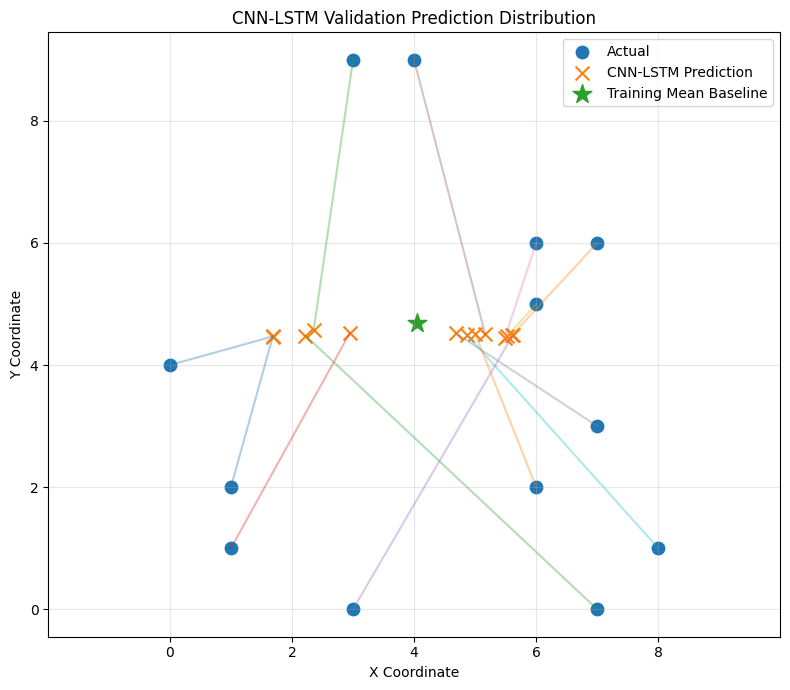

,Actual_X,Actual_Y,Predicted_X,Predicted_Y,CNN_LSTM_Error,Baseline_Error
2,7.0,0.0,2.221052,4.482588,6.552247,5.535588
4,3.0,0.0,5.615746,4.486465,5.193313,4.798300
9,8.0,1.0,4.874380,4.488885,4.684209,5.402075
5,4.0,9.0,5.163527,4.509637,4.638659,4.317723
12,3.0,9.0,2.355761,4.578063,4.468620,4.442744
3,1.0,1.0,2.947615,4.524093,4.026467,4.780071
7,7.0,3.0,4.685216,4.521828,2.770232,3.398160
11,6.0,2.0,5.005595,4.501761,2.692146,3.317802
10,1.0,2.0,1.684284,4.460986,2.554349,4.060049
1,7.0,6.0,5.599983,4.486595,2.061660,3.232995


In [111]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# BEST ANTENNA MODEL DIAGNOSTIC
# ==========================================

best_model = ablation_models["All Antennas"]

val_loader = create_antenna_loader(
    X_val_normalized,
    y_val,
    antennas=[0, 1, 2],
    shuffle=False
)

predictions, targets, distances = evaluate_model(
    best_model,
    val_loader
)

predictions = np.asarray(predictions)
targets = np.asarray(targets)
distances = np.asarray(distances)

print("=== PREDICTION DISTRIBUTION ===")

print("Prediction mean:", predictions.mean(axis=0))
print("Prediction std:", predictions.std(axis=0))

print("Actual mean:", targets.mean(axis=0))
print("Actual std:", targets.std(axis=0))

print("\n=== VALIDATION BASELINE ===")

baseline_position = np.asarray(y_train).mean(axis=0)

baseline_predictions = np.repeat(
    baseline_position.reshape(1, 2),
    len(targets),
    axis=0
)

baseline_distances = np.linalg.norm(
    baseline_predictions - targets,
    axis=1
)

print("CNN-LSTM MDE:", distances.mean())
print("Baseline MDE:", baseline_distances.mean())

# ==========================================
# VISUALIZATION
# ==========================================

plt.figure(figsize=(8, 7))

plt.scatter(
    targets[:, 0],
    targets[:, 1],
    label="Actual",
    s=80
)

plt.scatter(
    predictions[:, 0],
    predictions[:, 1],
    marker="x",
    s=100,
    label="CNN-LSTM Prediction"
)

for actual, predicted in zip(targets, predictions):

    plt.plot(
        [actual[0], predicted[0]],
        [actual[1], predicted[1]],
        alpha=0.35
    )

plt.scatter(
    baseline_position[0],
    baseline_position[1],
    marker="*",
    s=200,
    label="Training Mean Baseline"
)

plt.title("CNN-LSTM Validation Prediction Distribution")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()

# ==========================================
# INDIVIDUAL ERRORS
# ==========================================

diagnostic_df = pd.DataFrame({
    "Actual_X": targets[:, 0],
    "Actual_Y": targets[:, 1],
    "Predicted_X": predictions[:, 0],
    "Predicted_Y": predictions[:, 1],
    "CNN_LSTM_Error": distances,
    "Baseline_Error": baseline_distances
})

display(
    diagnostic_df.sort_values(
        "CNN_LSTM_Error",
        ascending=False
    )
)

=== COORDINATE-WISE ERROR ===


,Coordinate,MAE,RMSE,Prediction_STD,Actual_STD
0,X,1.718202,2.096010,1.543287,2.590378
1,Y,2.725624,3.092747,0.031863,2.997040


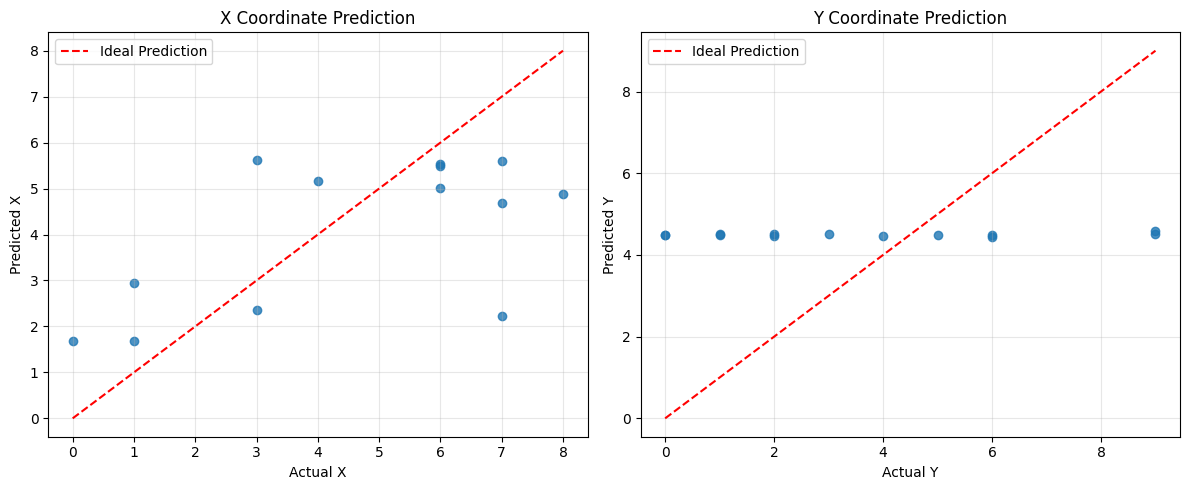

In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# COORDINATE-WISE ERROR ANALYSIS
# ==========================================

pred = np.asarray(predictions, dtype=np.float64)
true = np.asarray(targets, dtype=np.float64)

assert pred.shape == true.shape
assert pred.ndim == 2 and pred.shape[1] == 2
assert np.isfinite(pred).all()
assert np.isfinite(true).all()

error_x = pred[:, 0] - true[:, 0]
error_y = pred[:, 1] - true[:, 1]

results = pd.DataFrame({
    "Coordinate": ["X", "Y"],
    "MAE": [
        np.mean(np.abs(error_x)),
        np.mean(np.abs(error_y))
    ],
    "RMSE": [
        np.sqrt(np.mean(error_x**2)),
        np.sqrt(np.mean(error_y**2))
    ],
    "Prediction_STD": [
        np.std(pred[:, 0]),
        np.std(pred[:, 1])
    ],
    "Actual_STD": [
        np.std(true[:, 0]),
        np.std(true[:, 1])
    ]
})

print("=== COORDINATE-WISE ERROR ===")
display(results)

# ==========================================
# PREDICTION VS ACTUAL
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, name in enumerate(["X", "Y"]):

    axes[i].scatter(
        true[:, i],
        pred[:, i],
        alpha=0.8
    )

    low = min(true[:, i].min(), pred[:, i].min())
    high = max(true[:, i].max(), pred[:, i].max())

    axes[i].plot(
        [low, high],
        [low, high],
        "r--",
        label="Ideal Prediction"
    )

    axes[i].set_xlabel(f"Actual {name}")
    axes[i].set_ylabel(f"Predicted {name}")
    axes[i].set_title(f"{name} Coordinate Prediction")
    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

=== CSI COORDINATE CORRELATION ===


,Antenna,Mean_Abs_Corr_X,Mean_Abs_Corr_Y,Max_Abs_Corr_X,Max_Abs_Corr_Y
0,1,0.321761,0.117609,0.586823,0.271898
1,2,0.124203,0.093500,0.277034,0.231490
2,3,0.285501,0.097210,0.616896,0.261615


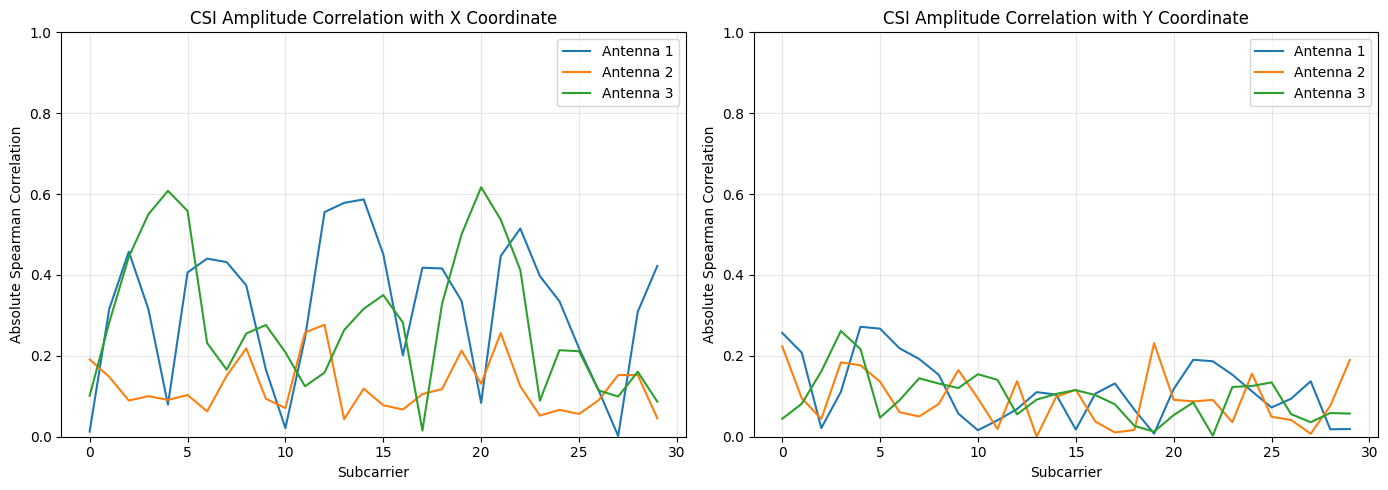


=== OVERALL CORRELATION ===
Mean absolute correlation X: 0.24382153887257776
Mean absolute correlation Y: 0.1027729663672003


In [113]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ==========================================
# CSI FEATURE VS COORDINATE ANALYSIS
# ==========================================

X = np.asarray(
    X_train_normalized,
    dtype=np.float64
)

y = np.asarray(
    y_train,
    dtype=np.float64
)

assert X.shape[1:] == (6, 60, 30)
assert y.shape[1] == 2
assert np.isfinite(X).all()
assert np.isfinite(y).all()

# Amplitude channels: antenna 1, 2, 3
amplitude = X[:, :3, :, :]

# Average over temporal dimension
features = amplitude.mean(axis=2)

# Shape: samples x antenna x subcarrier
n_samples, n_antennas, n_subcarriers = features.shape

corr_x = np.full(
    (n_antennas, n_subcarriers),
    np.nan
)

corr_y = np.full(
    (n_antennas, n_subcarriers),
    np.nan
)

for antenna in range(n_antennas):

    for subcarrier in range(n_subcarriers):

        feature = features[:, antenna, subcarrier]

        if np.std(feature) < 1e-8:
            continue

        corr_x[antenna, subcarrier] = spearmanr(
            feature, y[:, 0]
        ).statistic

        corr_y[antenna, subcarrier] = spearmanr(
            feature, y[:, 1]
        ).statistic

# ==========================================
# SUMMARY
# ==========================================

results = []

for antenna in range(n_antennas):

    results.append({
        "Antenna": antenna + 1,
        "Mean_Abs_Corr_X": np.nanmean(
            np.abs(corr_x[antenna])
        ),
        "Mean_Abs_Corr_Y": np.nanmean(
            np.abs(corr_y[antenna])
        ),
        "Max_Abs_Corr_X": np.nanmax(
            np.abs(corr_x[antenna])
        ),
        "Max_Abs_Corr_Y": np.nanmax(
            np.abs(corr_y[antenna])
        )
    })

correlation_df = pd.DataFrame(results)

print("=== CSI COORDINATE CORRELATION ===")
display(correlation_df)

# ==========================================
# VISUALIZATION
# ==========================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for antenna in range(n_antennas):

    axes[0].plot(
        np.abs(corr_x[antenna]),
        label=f"Antenna {antenna + 1}"
    )

    axes[1].plot(
        np.abs(corr_y[antenna]),
        label=f"Antenna {antenna + 1}"
    )

axes[0].set_title(
    "CSI Amplitude Correlation with X Coordinate"
)

axes[1].set_title(
    "CSI Amplitude Correlation with Y Coordinate"
)

for ax in axes:
    ax.set_xlabel("Subcarrier")
    ax.set_ylabel("Absolute Spearman Correlation")
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n=== OVERALL CORRELATION ===")

print(
    "Mean absolute correlation X:",
    np.nanmean(np.abs(corr_x))
)

print(
    "Mean absolute correlation Y:",
    np.nanmean(np.abs(corr_y))
)

Training features: (63, 180)
Validation features: (13, 180)

=== COORDINATE PREDICTABILITY ===


,Coordinate,Best_Alpha,Ridge_MAE,Ridge_RMSE,Baseline_MAE,Prediction_STD,Actual_STD
0,X,100,1.201011,1.469158,2.380952,2.220324,2.590378
1,Y,1000,2.873647,3.183246,2.772894,0.520683,2.997040


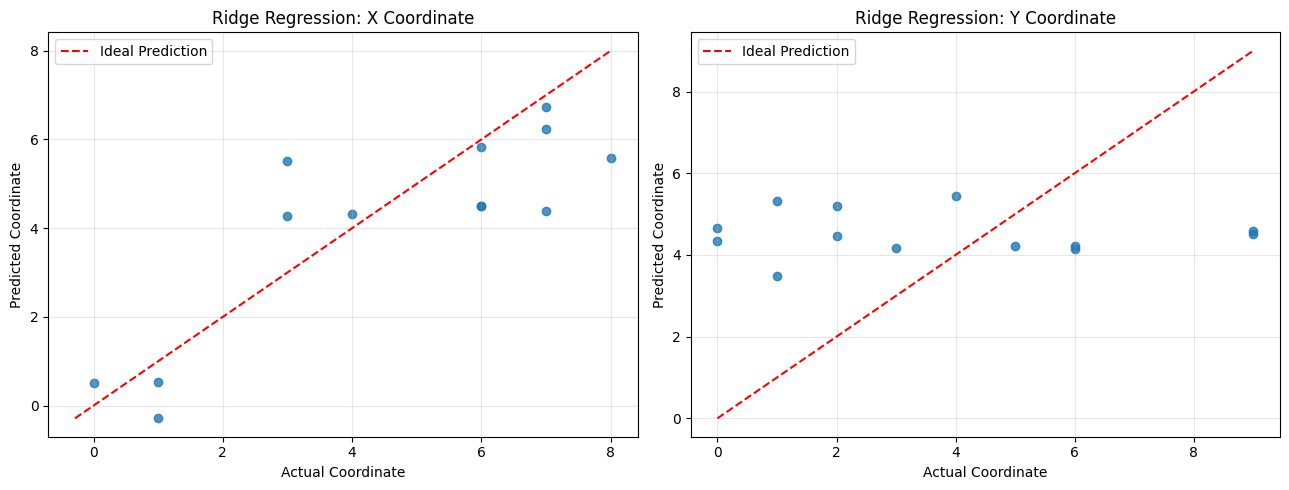

In [114]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ==========================================
# DIAGNOSTIC: CSI COORDINATE PREDICTABILITY
# ==========================================

def extract_amplitude_features(X):
    X = np.asarray(X, dtype=np.float64)

    assert X.ndim == 4
    assert X.shape[1] == 6
    assert np.isfinite(X).all()

    # Three amplitude channels
    amplitude = X[:, :3, :, :]

    # Mean and std over temporal dimension
    mean_features = amplitude.mean(axis=2)
    std_features = amplitude.std(axis=2)

    features = np.concatenate(
        [
            mean_features.reshape(len(X), -1),
            std_features.reshape(len(X), -1)
        ],
        axis=1
    )

    return features


Xtr = extract_amplitude_features(X_train_normalized)
Xval = extract_amplitude_features(X_val_normalized)

ytr = np.asarray(y_train, dtype=np.float64)
yval = np.asarray(y_val, dtype=np.float64)

assert np.isfinite(ytr).all()
assert np.isfinite(yval).all()

print("Training features:", Xtr.shape)
print("Validation features:", Xval.shape)

# ==========================================
# HYPERPARAMETER SELECTION
# ==========================================

alphas = [0.01, 0.1, 1, 10, 100, 1000]

models = {}
results = []

for coordinate, idx in [("X", 0), ("Y", 1)]:

    best_mae = np.inf
    best_model = None
    best_alpha = None

    for alpha in alphas:

        model = make_pipeline(
            StandardScaler(),
            Ridge(alpha=alpha)
        )

        model.fit(Xtr, ytr[:, idx])

        prediction = model.predict(Xval)

        mae = mean_absolute_error(
            yval[:, idx],
            prediction
        )

        if mae < best_mae:
            best_mae = mae
            best_model = model
            best_alpha = alpha

    models[coordinate] = best_model

    prediction = best_model.predict(Xval)

    baseline_prediction = np.full(
        len(yval),
        ytr[:, idx].mean()
    )

    results.append({
        "Coordinate": coordinate,
        "Best_Alpha": best_alpha,
        "Ridge_MAE": mean_absolute_error(
            yval[:, idx], prediction
        ),
        "Ridge_RMSE": np.sqrt(
            mean_squared_error(
                yval[:, idx], prediction
            )
        ),
        "Baseline_MAE": mean_absolute_error(
            yval[:, idx], baseline_prediction
        ),
        "Prediction_STD": np.std(prediction),
        "Actual_STD": np.std(yval[:, idx])
    })

diagnostic_df = pd.DataFrame(results)

print("\n=== COORDINATE PREDICTABILITY ===")
display(diagnostic_df)

# ==========================================
# VISUALIZATION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, coordinate, idx in zip(
    axes, ["X", "Y"], [0, 1]
):

    prediction = models[coordinate].predict(Xval)

    ax.scatter(
        yval[:, idx],
        prediction,
        alpha=0.8
    )

    lower = min(
        yval[:, idx].min(),
        prediction.min()
    )

    upper = max(
        yval[:, idx].max(),
        prediction.max()
    )

    ax.plot(
        [lower, upper],
        [lower, upper],
        "r--",
        label="Ideal Prediction"
    )

    ax.set_title(
        f"Ridge Regression: {coordinate} Coordinate"
    )

    ax.set_xlabel("Actual Coordinate")
    ax.set_ylabel("Predicted Coordinate")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [115]:
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

# ==========================================
# TEMPORAL FEATURE DIAGNOSTIC
# ==========================================

def extract_features(X, mode):

    X = np.asarray(X, dtype=np.float64)

    assert X.ndim == 4
    assert X.shape[1:] == (6, 60, 30)
    assert np.isfinite(X).all()

    amplitude = X[:, :3, :, :]

    if mode == "statistics":

        mean = amplitude.mean(axis=2)
        std = amplitude.std(axis=2)

        features = np.concatenate([
            mean.reshape(len(X), -1),
            std.reshape(len(X), -1)
        ], axis=1)

    elif mode == "raw_temporal":

        features = amplitude.reshape(len(X), -1)

    elif mode == "temporal_dynamics":

        mean = amplitude.mean(axis=2)
        std = amplitude.std(axis=2)

        temporal_diff = np.diff(
            amplitude,
            axis=2
        )

        diff_mean = np.mean(
            np.abs(temporal_diff),
            axis=2
        )

        diff_std = np.std(
            temporal_diff,
            axis=2
        )

        features = np.concatenate([
            mean.reshape(len(X), -1),
            std.reshape(len(X), -1),
            diff_mean.reshape(len(X), -1),
            diff_std.reshape(len(X), -1)
        ], axis=1)

    else:
        raise ValueError("Unknown feature mode")

    return features


feature_modes = [
    "statistics",
    "raw_temporal",
    "temporal_dynamics"
]

alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]

temporal_results = []

for mode in feature_modes:

    print("\n" + "=" * 55)
    print("Feature Mode:", mode)
    print("=" * 55)

    Xtr = extract_features(
        X_train_normalized,
        mode
    )

    Xval = extract_features(
        X_val_normalized,
        mode
    )

    ytr = np.asarray(y_train, dtype=np.float64)
    yval = np.asarray(y_val, dtype=np.float64)

    print("Feature dimension:", Xtr.shape[1])

    for coordinate, idx in [("X", 0), ("Y", 1)]:

        best_mae = np.inf
        best_alpha = None
        best_prediction = None

        for alpha in alphas:

            model = make_pipeline(
                StandardScaler(),
                Ridge(alpha=alpha)
            )

            model.fit(
                Xtr,
                ytr[:, idx]
            )

            prediction = model.predict(Xval)

            mae = mean_absolute_error(
                yval[:, idx],
                prediction
            )

            if mae < best_mae:

                best_mae = mae
                best_alpha = alpha
                best_prediction = prediction.copy()

        baseline = np.full(
            len(yval),
            ytr[:, idx].mean()
        )

        baseline_mae = mean_absolute_error(
            yval[:, idx],
            baseline
        )

        improvement = (
            (baseline_mae - best_mae)
            / baseline_mae
            * 100
        )

        temporal_results.append({
            "Feature_Mode": mode,
            "Coordinate": coordinate,
            "Feature_Dimension": Xtr.shape[1],
            "Best_Alpha": best_alpha,
            "MAE": best_mae,
            "Baseline_MAE": baseline_mae,
            "Improvement_Percent": improvement,
            "Prediction_STD": np.std(best_prediction),
            "Actual_STD": np.std(yval[:, idx])
        })

        print(
            f"{coordinate} | "
            f"MAE: {best_mae:.4f} | "
            f"Improvement: {improvement:.2f}%"
        )

temporal_df = pd.DataFrame(temporal_results)

print("\n=== TEMPORAL FEATURE DIAGNOSTIC RESULTS ===")

display(
    temporal_df.sort_values(
        ["Coordinate", "MAE"]
    ).reset_index(drop=True)
)


Feature Mode: statistics
Feature dimension: 180
X | MAE: 1.2010 | Improvement: 49.56%
Y | MAE: 2.8003 | Improvement: -0.99%

Feature Mode: raw_temporal
Feature dimension: 5400
X | MAE: 1.0708 | Improvement: 55.03%
Y | MAE: 3.1457 | Improvement: -13.44%

Feature Mode: temporal_dynamics
Feature dimension: 360
X | MAE: 1.2974 | Improvement: 45.51%
Y | MAE: 2.7162 | Improvement: 2.04%

=== TEMPORAL FEATURE DIAGNOSTIC RESULTS ===


,Feature_Mode,Coordinate,Feature_Dimension,Best_Alpha,MAE,Baseline_MAE,Improvement_Percent,Prediction_STD,Actual_STD
0,raw_temporal,X,5400,0.01,1.070797,2.380952,55.026512,2.628053,2.590378
1,statistics,X,180,100.00,1.201011,2.380952,49.557541,2.220324,2.590378
2,temporal_dynamics,X,360,100.00,1.297417,2.380952,45.508467,2.405600,2.590378
3,temporal_dynamics,Y,360,100.00,2.716245,2.772894,2.042938,1.677938,2.997040
4,statistics,Y,180,10000.00,2.800293,2.772894,-0.988118,0.102304,2.997040
5,raw_temporal,Y,5400,10000.00,3.145672,2.772894,-13.443651,0.824390,2.997040


In [116]:
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

# ==========================================
# NONLINEAR SPATIAL PREDICTABILITY
# ==========================================

feature_modes = [
    "statistics",
    "temporal_dynamics"
]

models_config = {
    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=100)
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

nonlinear_results = []

for feature_mode in feature_modes:

    print("\nFeature Mode:", feature_mode)

    Xtr = extract_features(
        X_train_normalized,
        feature_mode
    )

    Xval = extract_features(
        X_val_normalized,
        feature_mode
    )

    ytr = np.asarray(y_train, dtype=np.float64)
    yval = np.asarray(y_val, dtype=np.float64)

    for model_name, estimator in models_config.items():

        for coordinate, idx in [("X", 0), ("Y", 1)]:

            from sklearn.base import clone

            model = clone(estimator)

            model.fit(
                Xtr,
                ytr[:, idx]
            )

            prediction = model.predict(Xval)

            mae = mean_absolute_error(
                yval[:, idx],
                prediction
            )

            baseline = np.full(
                len(yval),
                ytr[:, idx].mean()
            )

            baseline_mae = mean_absolute_error(
                yval[:, idx],
                baseline
            )

            improvement = (
                (baseline_mae - mae)
                / baseline_mae
                * 100
            )

            nonlinear_results.append({
                "Feature_Mode": feature_mode,
                "Model": model_name,
                "Coordinate": coordinate,
                "MAE": mae,
                "Baseline_MAE": baseline_mae,
                "Improvement_Percent": improvement,
                "Prediction_STD": np.std(prediction)
            })

nonlinear_df = pd.DataFrame(nonlinear_results)

print("\n=== NONLINEAR PREDICTABILITY RESULTS ===")

display(
    nonlinear_df.sort_values(
        ["Coordinate", "MAE"]
    ).reset_index(drop=True)
)


Feature Mode: statistics

Feature Mode: temporal_dynamics

=== NONLINEAR PREDICTABILITY RESULTS ===


,Feature_Mode,Model,Coordinate,MAE,Baseline_MAE,Improvement_Percent,Prediction_STD
0,temporal_dynamics,Extra Trees,X,1.131042,2.380952,52.496246,1.994890
1,temporal_dynamics,Random Forest,X,1.138808,2.380952,52.170082,1.888181
2,statistics,Random Forest,X,1.153715,2.380952,51.543981,2.121203
3,statistics,Ridge,X,1.201011,2.380952,49.557541,2.220324
4,statistics,Extra Trees,X,1.248294,2.380952,47.571658,2.031172
5,temporal_dynamics,Ridge,X,1.297417,2.380952,45.508467,2.405600
6,temporal_dynamics,Random Forest,Y,2.547325,2.772894,8.134782,0.719863
7,temporal_dynamics,Extra Trees,Y,2.610481,2.772894,5.857174,0.745577
8,temporal_dynamics,Ridge,Y,2.716245,2.772894,2.042938,1.677938
9,statistics,Random Forest,Y,2.867087,2.772894,-3.396943,0.763666


=== CSI SPATIAL DISCRIMINABILITY ===
X pairs: 39
Y pairs: 39
Mean CSI distance X: 24.902141181540312
Mean CSI distance Y: 22.787516439644577
X/Y distance ratio: 1.092797508122334
Mann-Whitney U: 877.0
Exploratory p-value: 0.24634957630384957


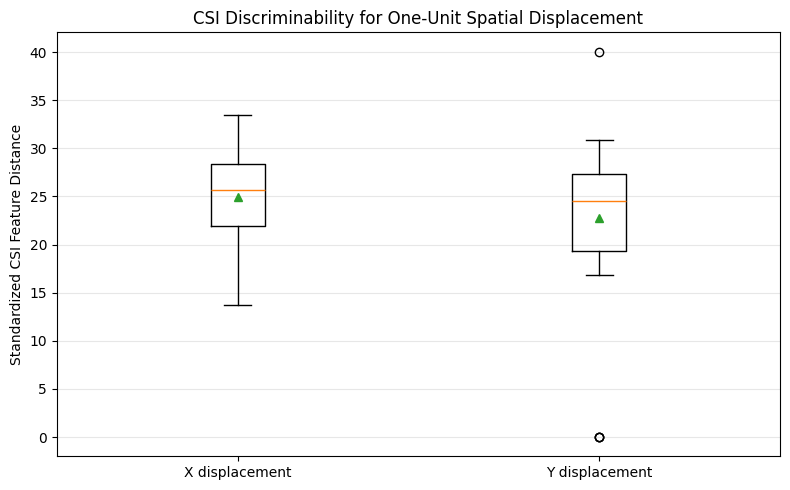

In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import euclidean
from scipy.stats import mannwhitneyu

# ==========================================
# CSI SPATIAL DISCRIMINABILITY ANALYSIS
# ==========================================

X = np.asarray(
    X_train_normalized,
    dtype=np.float64
)

coordinates = np.asarray(
    y_train,
    dtype=np.float64
)

assert X.ndim == 4
assert X.shape[1:] == (6, 60, 30)
assert len(X) == len(coordinates)
assert np.isfinite(X).all()

# Extract amplitude statistics
features = extract_features(
    X,
    "temporal_dynamics"
)

# Standardize feature dimensions using training only
feature_mean = features.mean(axis=0)
feature_std = features.std(axis=0)

feature_std = np.where(
    feature_std < 1e-8,
    1.0,
    feature_std
)

features = (
    features - feature_mean
) / feature_std

x_distances = []
y_distances = []

for i in range(len(coordinates)):

    for j in range(i + 1, len(coordinates)):

        dx = abs(
            coordinates[i, 0] -
            coordinates[j, 0]
        )

        dy = abs(
            coordinates[i, 1] -
            coordinates[j, 1]
        )

        feature_distance = euclidean(
            features[i],
            features[j]
        )

        # One-unit displacement along X
        if np.isclose(dx, 1) and np.isclose(dy, 0):

            x_distances.append(feature_distance)

        # One-unit displacement along Y
        elif np.isclose(dx, 0) and np.isclose(dy, 1):

            y_distances.append(feature_distance)

x_distances = np.asarray(x_distances)
y_distances = np.asarray(y_distances)

print("=== CSI SPATIAL DISCRIMINABILITY ===")

print("X pairs:", len(x_distances))
print("Y pairs:", len(y_distances))

if len(x_distances) == 0 or len(y_distances) == 0:
    raise ValueError(
        "Insufficient adjacent training pairs."
    )

print(
    "Mean CSI distance X:",
    np.mean(x_distances)
)

print(
    "Mean CSI distance Y:",
    np.mean(y_distances)
)

ratio = (
    np.mean(x_distances) /
    np.mean(y_distances)
)

print("X/Y distance ratio:", ratio)

statistic, p_value = mannwhitneyu(
    x_distances,
    y_distances,
    alternative="two-sided"
)

print("Mann-Whitney U:", statistic)
print("Exploratory p-value:", p_value)

# ==========================================
# VISUALIZATION
# ==========================================

plt.figure(figsize=(8, 5))

plt.boxplot(
    [x_distances, y_distances],
    tick_labels=[
        "X displacement",
        "Y displacement"
    ],
    showmeans=True
)

plt.ylabel("Standardized CSI Feature Distance")

plt.title(
    "CSI Discriminability for One-Unit Spatial Displacement"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

=== CSI SPATIAL AMBIGUITY ===
Mean physical distance to CSI neighbor: 3.362034169978172
Mean nearest physical distance: 1.0065748184503664
Spearman CSI vs spatial distance: 0.23068594511252485
Exploratory p-value: 5.2798904498966525e-25

=== MOST AMBIGUOUS LOCATIONS ===


,Actual_X,Actual_Y,Nearest_CSI_X,Nearest_CSI_Y,CSI_Neighbor_Physical_Distance,Nearest_Physical_Distance,CSI_Distance_To_Physical_Neighbor
45,5.0,9.0,6.0,0.0,9.055385,1.000000,24.758842
54,2.0,3.0,8.0,7.0,7.211103,1.000000,29.893148
49,2.0,9.0,3.0,2.0,7.071068,1.000000,24.051760
6,4.0,2.0,8.0,7.0,6.403124,1.000000,23.035072
18,1.0,3.0,0.0,9.0,6.082763,1.000000,27.367353
3,0.0,9.0,1.0,3.0,6.082763,1.000000,33.419596
0,6.0,7.0,7.0,1.0,6.082763,1.000000,27.772407
41,7.0,9.0,8.0,3.0,6.082763,1.000000,22.116820
12,7.0,8.0,2.0,5.0,5.830952,1.000000,30.218953
52,2.0,1.0,7.0,4.0,5.830952,1.000000,28.286836


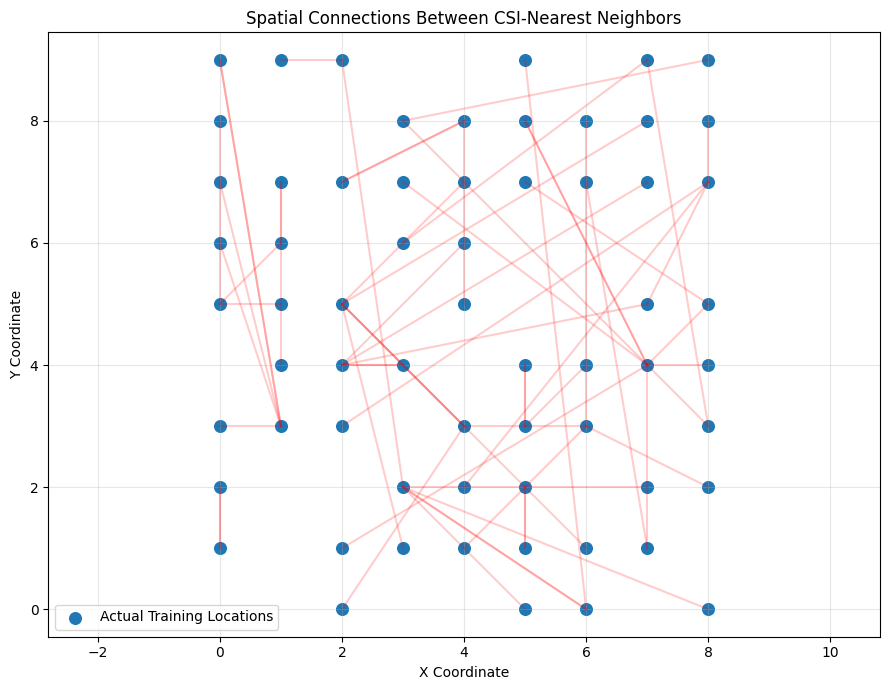

In [118]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import pairwise_distances
from scipy.stats import spearmanr

# ==========================================
# CSI SPATIAL AMBIGUITY ANALYSIS
# ==========================================

X = np.asarray(
    X_train_normalized,
    dtype=np.float64
)

coords = np.asarray(
    y_train,
    dtype=np.float64
)

features = extract_features(
    X,
    "temporal_dynamics"
)

# Standardization based on training set
mean = features.mean(axis=0)
std = features.std(axis=0)

std = np.where(std < 1e-8, 1.0, std)

features = (features - mean) / std

# CSI feature distance matrix
csi_dist = pairwise_distances(
    features,
    metric="euclidean"
)

# Physical distance matrix
spatial_dist = pairwise_distances(
    coords,
    metric="euclidean"
)

# Exclude self-comparisons
np.fill_diagonal(csi_dist, np.inf)
np.fill_diagonal(spatial_dist, np.inf)

# Nearest neighbor in CSI feature space
nearest_csi_idx = np.argmin(
    csi_dist,
    axis=1
)

# Nearest neighbor in physical space
nearest_spatial_idx = np.argmin(
    spatial_dist,
    axis=1
)

n = len(coords)
indices = np.arange(n)

# Physical distance to CSI-nearest neighbor
csi_neighbor_physical_distance = (
    spatial_dist[indices, nearest_csi_idx]
)

# Minimum possible physical neighbor distance
nearest_physical_distance = (
    spatial_dist[indices, nearest_spatial_idx]
)

# CSI distance of physically nearest neighbor
physical_neighbor_csi_distance = (
    csi_dist[indices, nearest_spatial_idx]
)

# Correlation across unique location pairs
upper = np.triu_indices(n, k=1)

rho, p_value = spearmanr(
    csi_dist[upper],
    spatial_dist[upper]
)

results = pd.DataFrame({
    "Actual_X": coords[:, 0],
    "Actual_Y": coords[:, 1],
    "Nearest_CSI_X": coords[nearest_csi_idx, 0],
    "Nearest_CSI_Y": coords[nearest_csi_idx, 1],
    "CSI_Neighbor_Physical_Distance":
        csi_neighbor_physical_distance,
    "Nearest_Physical_Distance":
        nearest_physical_distance,
    "CSI_Distance_To_Physical_Neighbor":
        physical_neighbor_csi_distance
})

print("=== CSI SPATIAL AMBIGUITY ===")

print(
    "Mean physical distance to CSI neighbor:",
    np.mean(csi_neighbor_physical_distance)
)

print(
    "Mean nearest physical distance:",
    np.mean(nearest_physical_distance)
)

print(
    "Spearman CSI vs spatial distance:",
    rho
)

print(
    "Exploratory p-value:",
    p_value
)

print("\n=== MOST AMBIGUOUS LOCATIONS ===")

display(
    results.sort_values(
        "CSI_Neighbor_Physical_Distance",
        ascending=False
    ).head(15)
)

# ==========================================
# VISUALIZATION
# ==========================================

plt.figure(figsize=(9, 7))

plt.scatter(
    coords[:, 0],
    coords[:, 1],
    s=70,
    label="Actual Training Locations"
)

for i in range(n):

    j = nearest_csi_idx[i]

    plt.plot(
        [coords[i, 0], coords[j, 0]],
        [coords[i, 1], coords[j, 1]],
        alpha=0.2,
        color="red"
    )

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.title(
    "Spatial Connections Between CSI-Nearest Neighbors"
)

plt.grid(alpha=0.3)
plt.axis("equal")
plt.legend()
plt.tight_layout()
plt.show()

=== AXIS-SPECIFIC SPATIAL AMBIGUITY ===


,Coordinate,Mean_Neighbor_Error,Median_Neighbor_Error,Spearman_Correlation,Exploratory_P_Value
0,X,1.825397,1.0,0.232906,1.810424e-25
1,Y,2.380952,2.0,0.057824,1.059081e-02



=== NEAREST CSI NEIGHBOR ERRORS ===


,Actual_X,Actual_Y,Neighbor_X,Neighbor_Y,X_Error,Y_Error
0,6.0,7.0,7.0,1.0,1.0,6.0
1,3.0,1.0,2.0,5.0,1.0,4.0
2,7.0,5.0,2.0,4.0,5.0,1.0
3,0.0,9.0,1.0,3.0,1.0,6.0
4,6.0,8.0,6.0,3.0,0.0,5.0
5,0.0,5.0,1.0,6.0,1.0,1.0
6,4.0,2.0,8.0,7.0,4.0,5.0
7,4.0,7.0,2.0,5.0,2.0,2.0
8,1.0,6.0,1.0,7.0,0.0,1.0
9,4.0,5.0,4.0,8.0,0.0,3.0


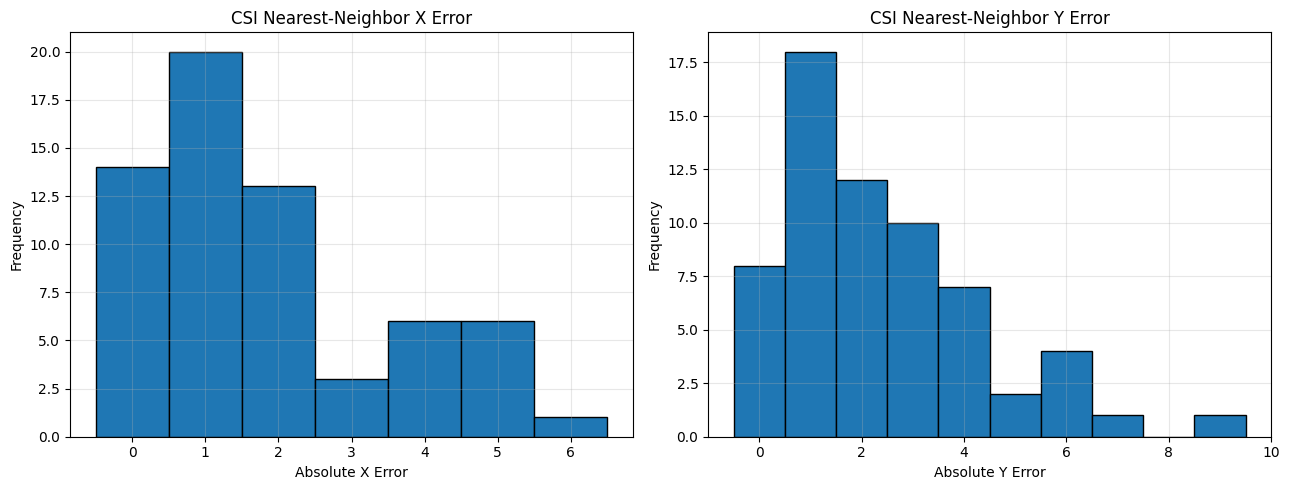

In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from sklearn.metrics import pairwise_distances

# ==========================================
# AXIS-SPECIFIC CSI SPATIAL AMBIGUITY
# ==========================================

coords = np.asarray(y_train, dtype=np.float64)

features = extract_features(
    np.asarray(X_train_normalized),
    "temporal_dynamics"
)

features = np.asarray(features, dtype=np.float64)

assert np.isfinite(features).all()
assert np.isfinite(coords).all()

# Standardization
mean = features.mean(axis=0)
std = features.std(axis=0)

std = np.where(std < 1e-8, 1.0, std)

features = (features - mean) / std

# CSI distance
csi_dist = pairwise_distances(
    features,
    metric="euclidean"
)

n = len(coords)

# Exclude self
np.fill_diagonal(csi_dist, np.inf)

nearest_idx = np.argmin(csi_dist, axis=1)

# Coordinate differences
dx = np.abs(
    coords[:, 0] - coords[nearest_idx, 0]
)

dy = np.abs(
    coords[:, 1] - coords[nearest_idx, 1]
)

# Pairwise coordinate distances
dist_x = np.abs(
    coords[:, 0, None] - coords[None, :, 0]
)

dist_y = np.abs(
    coords[:, 1, None] - coords[None, :, 1]
)

upper = np.triu_indices(n, k=1)

rho_x, p_x = spearmanr(
    csi_dist[upper],
    dist_x[upper]
)

rho_y, p_y = spearmanr(
    csi_dist[upper],
    dist_y[upper]
)

summary = pd.DataFrame({
    "Coordinate": ["X", "Y"],
    "Mean_Neighbor_Error": [
        np.mean(dx),
        np.mean(dy)
    ],
    "Median_Neighbor_Error": [
        np.median(dx),
        np.median(dy)
    ],
    "Spearman_Correlation": [
        rho_x,
        rho_y
    ],
    "Exploratory_P_Value": [
        p_x,
        p_y
    ]
})

print("=== AXIS-SPECIFIC SPATIAL AMBIGUITY ===")
display(summary)

print("\n=== NEAREST CSI NEIGHBOR ERRORS ===")

detail = pd.DataFrame({
    "Actual_X": coords[:, 0],
    "Actual_Y": coords[:, 1],
    "Neighbor_X": coords[nearest_idx, 0],
    "Neighbor_Y": coords[nearest_idx, 1],
    "X_Error": dx,
    "Y_Error": dy
})

display(detail.head(15))

# ==========================================
# VISUALIZATION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    dx,
    bins=np.arange(-0.5, np.max(dx) + 1.5, 1),
    edgecolor="black"
)

axes[0].set_title("CSI Nearest-Neighbor X Error")
axes[0].set_xlabel("Absolute X Error")
axes[0].set_ylabel("Frequency")
axes[0].grid(alpha=0.3)

axes[1].hist(
    dy,
    bins=np.arange(-0.5, np.max(dy) + 1.5, 1),
    edgecolor="black"
)

axes[1].set_title("CSI Nearest-Neighbor Y Error")
axes[1].set_xlabel("Absolute Y Error")
axes[1].set_ylabel("Frequency")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

=== CSI AXIS SEPARABILITY RESULTS ===


,Coordinate,Same_Axis_Mean_CSI_Distance,Different_Axis_Mean_CSI_Distance,Separability_Ratio,Same_Pairs,Different_Pairs
0,X,25.037382,26.722867,1.067319,192,1761
1,Y,26.494161,26.563445,1.002615,177,1776


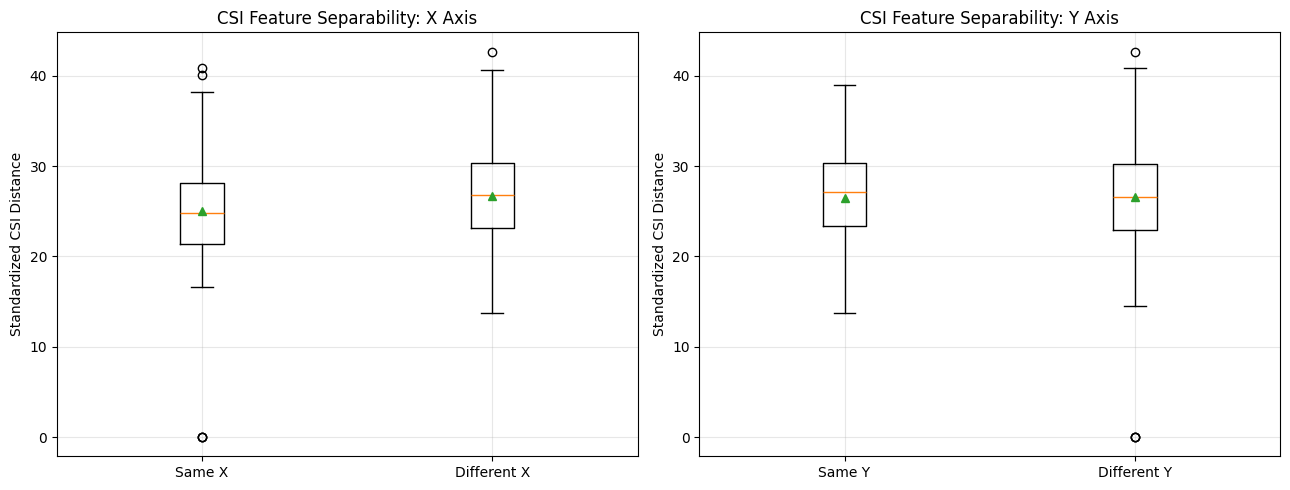


=== INTERPRETATION ===
X Axis | Separability Ratio: 1.0673
Y Axis | Separability Ratio: 1.0026


In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import pairwise_distances

# ==========================================
# CSI FEATURE SEPARABILITY BY AXIS
# ==========================================

coords = np.asarray(y_train, dtype=np.float64)

features = extract_features(
    np.asarray(X_train_normalized),
    "temporal_dynamics"
)

features = np.asarray(features, dtype=np.float64)

assert np.isfinite(features).all()
assert np.isfinite(coords).all()

# Standardize features
mean = features.mean(axis=0)
std = features.std(axis=0)
std = np.where(std < 1e-8, 1.0, std)

features = (features - mean) / std

# Pairwise CSI distances
D = pairwise_distances(features)

i, j = np.triu_indices(len(coords), k=1)

csi_distances = D[i, j]

results = []
plot_data = {}

for axis, name in enumerate(["X", "Y"]):

    same_axis = np.isclose(
        coords[i, axis],
        coords[j, axis]
    )

    same_dist = csi_distances[same_axis]
    different_dist = csi_distances[~same_axis]

    same_mean = np.mean(same_dist)
    different_mean = np.mean(different_dist)

    separability_ratio = (
        different_mean / same_mean
        if same_mean > 0 else np.nan
    )

    results.append({
        "Coordinate": name,
        "Same_Axis_Mean_CSI_Distance": same_mean,
        "Different_Axis_Mean_CSI_Distance": different_mean,
        "Separability_Ratio": separability_ratio,
        "Same_Pairs": len(same_dist),
        "Different_Pairs": len(different_dist)
    })

    plot_data[name] = (
        same_dist,
        different_dist
    )

separability_df = pd.DataFrame(results)

print("=== CSI AXIS SEPARABILITY RESULTS ===")
display(separability_df)

# ==========================================
# VISUALIZATION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name in zip(axes, ["X", "Y"]):

    same_dist, different_dist = plot_data[name]

    ax.boxplot(
        [same_dist, different_dist],
        tick_labels=[
            f"Same {name}",
            f"Different {name}"
        ],
        showmeans=True
    )

    ax.set_title(
        f"CSI Feature Separability: {name} Axis"
    )

    ax.set_ylabel("Standardized CSI Distance")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n=== INTERPRETATION ===")

for _, row in separability_df.iterrows():

    print(
        f"{row['Coordinate']} Axis | "
        f"Separability Ratio: "
        f"{row['Separability_Ratio']:.4f}"
    )

=== DISTANCE-CONTROLLED SEPARABILITY ===


,Axis,Pairs,Mean_CSI_Distance,Median_CSI_Distance,STD_CSI_Distance
0,X,39,24.902141,25.671175,4.978898
1,Y,39,22.787516,24.543825,8.031283



X/Y CSI Distance Ratio: 1.0928
Mann-Whitney U: 877.0000
Exploratory p-value: 0.246362


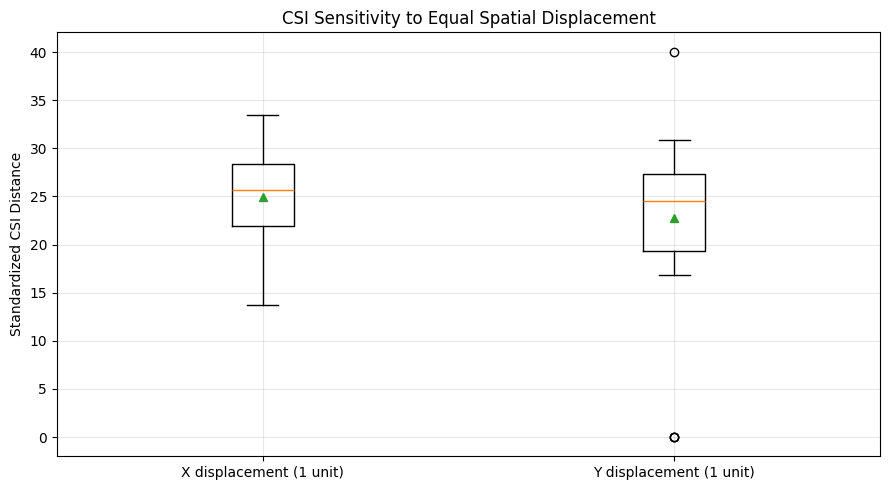

In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import pairwise_distances
from scipy.stats import mannwhitneyu

# ==========================================
# DISTANCE-CONTROLLED CSI SEPARABILITY
# ==========================================

coords = np.asarray(y_train, dtype=np.float64)

features = extract_features(
    np.asarray(X_train_normalized),
    "temporal_dynamics"
)

features = np.asarray(features, dtype=np.float64)

assert np.isfinite(features).all()
assert np.isfinite(coords).all()

# Standardization
mean = features.mean(axis=0)
std = features.std(axis=0)

std = np.where(std < 1e-8, 1.0, std)

features = (features - mean) / std

# CSI distance matrix
D = pairwise_distances(features)

i, j = np.triu_indices(len(coords), k=1)

dx = np.abs(coords[i, 0] - coords[j, 0])
dy = np.abs(coords[i, 1] - coords[j, 1])

csi_dist = D[i, j]

# Exact one-unit displacement
x_mask = np.isclose(dx, 1) & np.isclose(dy, 0)
y_mask = np.isclose(dx, 0) & np.isclose(dy, 1)

x_dist = csi_dist[x_mask]
y_dist = csi_dist[y_mask]

if len(x_dist) == 0 or len(y_dist) == 0:
    raise ValueError(
        "Tidak cukup pasangan lokasi dengan "
        "perpindahan tepat satu unit."
    )

# ==========================================
# DESCRIPTIVE STATISTICS
# ==========================================

results = pd.DataFrame({
    "Axis": ["X", "Y"],
    "Pairs": [len(x_dist), len(y_dist)],
    "Mean_CSI_Distance": [
        np.mean(x_dist),
        np.mean(y_dist)
    ],
    "Median_CSI_Distance": [
        np.median(x_dist),
        np.median(y_dist)
    ],
    "STD_CSI_Distance": [
        np.std(x_dist),
        np.std(y_dist)
    ]
})

print("=== DISTANCE-CONTROLLED SEPARABILITY ===")
display(results)

ratio = np.mean(x_dist) / np.mean(y_dist)

print(f"\nX/Y CSI Distance Ratio: {ratio:.4f}")

# Exploratory statistical comparison
stat, p = mannwhitneyu(
    x_dist,
    y_dist,
    alternative="two-sided"
)

print(f"Mann-Whitney U: {stat:.4f}")
print(f"Exploratory p-value: {p:.6g}")

# ==========================================
# VISUALIZATION
# ==========================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [x_dist, y_dist],
    tick_labels=[
        "X displacement (1 unit)",
        "Y displacement (1 unit)"
    ],
    showmeans=True
)

plt.ylabel("Standardized CSI Distance")
plt.title(
    "CSI Sensitivity to Equal Spatial Displacement"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

=== DISTANCE-CONTROLLED SEPARABILITY ===


,Axis,Pairs,Mean_CSI_Distance,Median_CSI_Distance,STD_CSI_Distance
0,X,39,24.902141,25.671175,4.978898
1,Y,39,22.787516,24.543825,8.031283



X/Y CSI Distance Ratio: 1.0928
Mann-Whitney U: 877.0000
Exploratory p-value: 0.246362


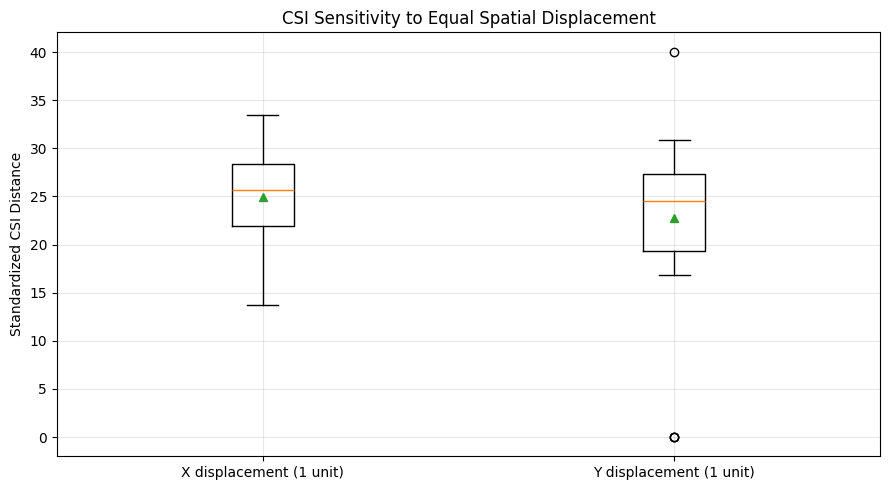

In [122]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import pairwise_distances
from scipy.stats import mannwhitneyu

# ==========================================
# DISTANCE-CONTROLLED CSI SEPARABILITY
# ==========================================

coords = np.asarray(y_train, dtype=np.float64)

features = extract_features(
    np.asarray(X_train_normalized),
    "temporal_dynamics"
)

features = np.asarray(features, dtype=np.float64)

assert np.isfinite(features).all()
assert np.isfinite(coords).all()

# Standardization
mean = features.mean(axis=0)
std = features.std(axis=0)

std = np.where(std < 1e-8, 1.0, std)

features = (features - mean) / std

# CSI distance matrix
D = pairwise_distances(features)

i, j = np.triu_indices(len(coords), k=1)

dx = np.abs(coords[i, 0] - coords[j, 0])
dy = np.abs(coords[i, 1] - coords[j, 1])

csi_dist = D[i, j]

# Exact one-unit displacement
x_mask = np.isclose(dx, 1) & np.isclose(dy, 0)
y_mask = np.isclose(dx, 0) & np.isclose(dy, 1)

x_dist = csi_dist[x_mask]
y_dist = csi_dist[y_mask]

if len(x_dist) == 0 or len(y_dist) == 0:
    raise ValueError(
        "Tidak cukup pasangan lokasi dengan "
        "perpindahan tepat satu unit."
    )

# ==========================================
# DESCRIPTIVE STATISTICS
# ==========================================

results = pd.DataFrame({
    "Axis": ["X", "Y"],
    "Pairs": [len(x_dist), len(y_dist)],
    "Mean_CSI_Distance": [
        np.mean(x_dist),
        np.mean(y_dist)
    ],
    "Median_CSI_Distance": [
        np.median(x_dist),
        np.median(y_dist)
    ],
    "STD_CSI_Distance": [
        np.std(x_dist),
        np.std(y_dist)
    ]
})

print("=== DISTANCE-CONTROLLED SEPARABILITY ===")
display(results)

ratio = np.mean(x_dist) / np.mean(y_dist)

print(f"\nX/Y CSI Distance Ratio: {ratio:.4f}")

# Exploratory statistical comparison
stat, p = mannwhitneyu(
    x_dist,
    y_dist,
    alternative="two-sided"
)

print(f"Mann-Whitney U: {stat:.4f}")
print(f"Exploratory p-value: {p:.6g}")

# ==========================================
# VISUALIZATION
# ==========================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [x_dist, y_dist],
    tick_labels=[
        "X displacement (1 unit)",
        "Y displacement (1 unit)"
    ],
    showmeans=True
)

plt.ylabel("Standardized CSI Distance")
plt.title(
    "CSI Sensitivity to Equal Spatial Displacement"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

=== CSI NEIGHBORHOOD PRESERVATION ===


,K,CSI_Physical_Overlap,Random_Expected_Overlap,Overlap_Improvement
0,1,0.126984,0.016129,0.110855
1,3,0.132275,0.048387,0.083888
2,5,0.177778,0.080645,0.097133
3,7,0.229025,0.112903,0.116122
4,10,0.263492,0.161290,0.102202



=== TRUSTWORTHINESS ===


,K,Trustworthiness
0,1,0.715847
1,3,0.638022
2,5,0.648716
3,7,0.650968
4,10,0.650794


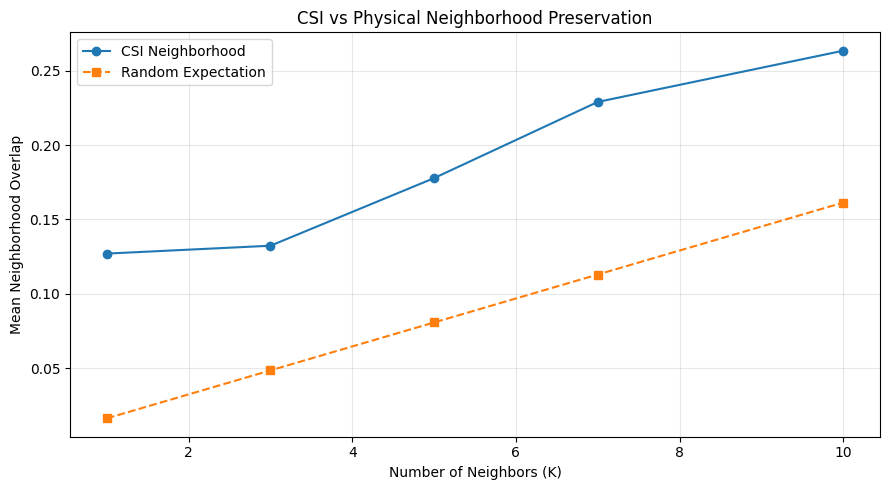

In [123]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.manifold import trustworthiness
from sklearn.metrics import pairwise_distances

# ==========================================
# CSI NEIGHBORHOOD PRESERVATION
# ==========================================

coords = np.asarray(y_train, dtype=np.float64)

features = extract_features(
    np.asarray(X_train_normalized),
    "temporal_dynamics"
)

features = np.asarray(features, dtype=np.float64)

assert np.isfinite(coords).all()
assert np.isfinite(features).all()

# Standardization
mean = features.mean(axis=0)
std = features.std(axis=0)
std = np.where(std < 1e-8, 1.0, std)

features = (features - mean) / std

# Distance matrices
physical_D = pairwise_distances(coords)
csi_D = pairwise_distances(features)

# Exclude self-neighbors
np.fill_diagonal(physical_D, np.inf)
np.fill_diagonal(csi_D, np.inf)

k_values = [1, 3, 5, 7, 10]

results = []

n = len(coords)

for k in k_values:

    if k >= n:
        continue

    physical_neighbors = np.argsort(
        physical_D, axis=1
    )[:, :k]

    csi_neighbors = np.argsort(
        csi_D, axis=1
    )[:, :k]

    overlaps = []

    for i in range(n):

        overlap = len(
            set(physical_neighbors[i]).intersection(
                set(csi_neighbors[i])
            )
        ) / k

        overlaps.append(overlap)

    mean_overlap = np.mean(overlaps)

    random_overlap = k / (n - 1)

    results.append({
        "K": k,
        "CSI_Physical_Overlap": mean_overlap,
        "Random_Expected_Overlap": random_overlap,
        "Overlap_Improvement": (
            mean_overlap - random_overlap
        )
    })

overlap_df = pd.DataFrame(results)

print("=== CSI NEIGHBORHOOD PRESERVATION ===")
display(overlap_df)

# Trustworthiness
trust_results = []

for k in k_values:

    if k >= n / 2:
        continue

    score = trustworthiness(
        coords,
        features,
        n_neighbors=k
    )

    trust_results.append({
        "K": k,
        "Trustworthiness": score
    })

trust_df = pd.DataFrame(trust_results)

print("\n=== TRUSTWORTHINESS ===")
display(trust_df)

# ==========================================
# VISUALIZATION
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    overlap_df["K"],
    overlap_df["CSI_Physical_Overlap"],
    marker="o",
    label="CSI Neighborhood"
)

plt.plot(
    overlap_df["K"],
    overlap_df["Random_Expected_Overlap"],
    marker="s",
    linestyle="--",
    label="Random Expectation"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean Neighborhood Overlap")
plt.title("CSI vs Physical Neighborhood Preservation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [124]:

# =====================================================
# FIX INPUT DIMENSION FOR EXTRA TREES
# =====================================================

# Gunakan data CSI asli dari eksperimen sebelumnya.
# Sesuaikan nama variabel apabila berbeda.

X_tr = np.asarray(X_train, dtype=np.float32)
X_va = np.asarray(X_val, dtype=np.float32)

print("Original training shape:", X_tr.shape)
print("Original validation shape:", X_va.shape)

def extract_temporal_dynamics(X):
    """
    Input : (samples, channels, time, subcarriers)
    Output: (samples, channels * subcarriers * 2)
    """

    if X.ndim != 4:
        raise ValueError(
            f"Expected 4D CSI input, received {X.shape}"
        )

    temporal_mean = np.mean(X, axis=2)
    temporal_std = np.std(X, axis=2)

    mean_features = temporal_mean.reshape(len(X), -1)
    std_features = temporal_std.reshape(len(X), -1)

    return np.concatenate(
        [mean_features, std_features],
        axis=1
    ).astype(np.float32)


X_tr = extract_temporal_dynamics(X_tr)
X_va = extract_temporal_dynamics(X_va)

print("\n=== EXTRACTED FEATURES ===")
print("Training features:", X_tr.shape)
print("Validation features:", X_va.shape)

assert X_tr.ndim == 2
assert X_va.ndim == 2
assert X_tr.shape[1] == X_va.shape[1]

print("\nFeature extraction successful.")


Original training shape: (63, 6, 60, 30)
Original validation shape: (13, 6, 60, 30)

=== EXTRACTED FEATURES ===
Training features: (63, 360)
Validation features: (13, 360)

Feature extraction successful.


Training: (63, 6, 60, 30)
Validation: (13, 6, 60, 30)
Extracted training features: (63, 360)
Extracted validation features: (13, 360)

AXIS-SPECIFIC FEATURE SELECTION: X
K=  5 | MAE=1.3410 | RMSE=1.7089 | Improvement=43.68%
K= 10 | MAE=1.2846 | RMSE=1.7429 | Improvement=46.05%
K= 20 | MAE=1.2365 | RMSE=1.6873 | Improvement=48.07%
K= 30 | MAE=1.1342 | RMSE=1.6117 | Improvement=52.36%
K= 50 | MAE=1.1791 | RMSE=1.6371 | Improvement=50.48%
K= 80 | MAE=1.1487 | RMSE=1.6099 | Improvement=51.75%
K=120 | MAE=1.2539 | RMSE=1.6909 | Improvement=47.34%
K=180 | MAE=1.2231 | RMSE=1.6008 | Improvement=48.63%
K=240 | MAE=1.2457 | RMSE=1.6343 | Improvement=47.68%
K=360 | MAE=1.2356 | RMSE=1.6813 | Improvement=48.11%

Best X: K=30, MAE=1.1342

AXIS-SPECIFIC FEATURE SELECTION: Y
K=  5 | MAE=2.7503 | RMSE=3.1872 | Improvement=0.81%
K= 10 | MAE=2.4371 | RMSE=2.9284 | Improvement=12.11%
K= 20 | MAE=2.6140 | RMSE=3.1495 | Improvement=5.73%
K= 30 | MAE=2.6188 | RMSE=3.1684 | Improvement=5.56%
K= 50 | MAE=2.4

,Coordinate,Selected_Features,Validation_MAE,Validation_RMSE,Baseline_MAE,Improvement_Percent,Prediction_STD
0,X,30,1.134231,1.611696,2.380952,52.362307,1.900772
1,X,80,1.148718,1.609939,2.380952,51.753846,2.048283
2,X,50,1.179103,1.637138,2.380952,50.477692,2.044322
3,X,180,1.223077,1.600769,2.380952,48.630769,1.897475
4,X,360,1.235577,1.681275,2.380952,48.105769,1.973873
5,X,20,1.236538,1.687323,2.380952,48.065384,2.097727
6,X,240,1.245705,1.634280,2.380952,47.680384,1.948270
7,X,120,1.253910,1.690852,2.380952,47.335769,1.962671
8,X,10,1.284571,1.742854,2.380952,46.048038,2.026066
9,X,5,1.340990,1.708909,2.380952,43.678421,1.839879


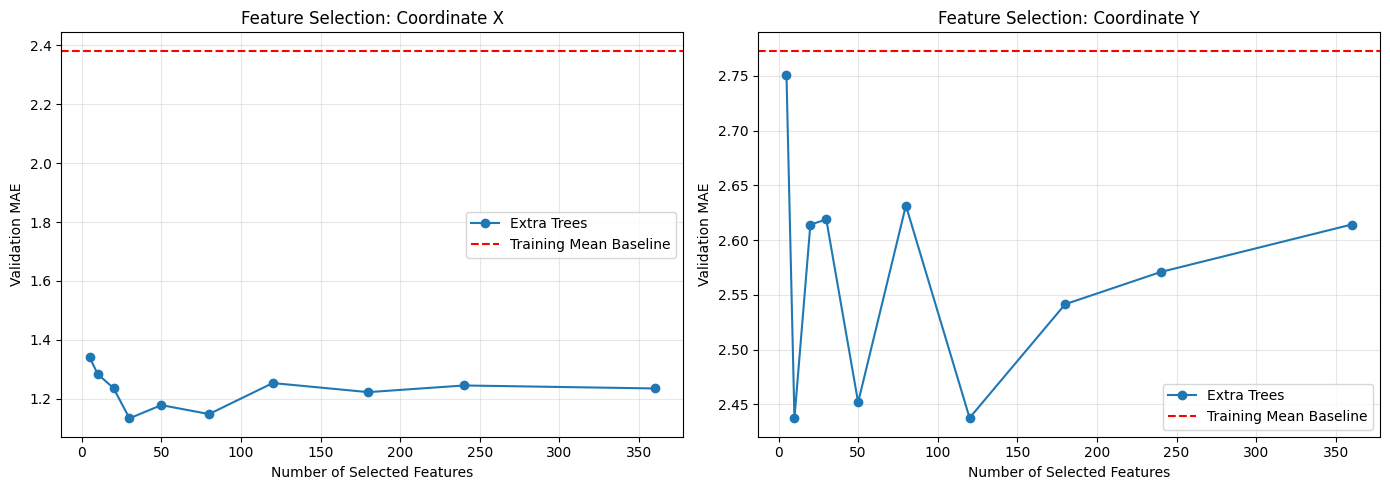


=== BEST AXIS-SPECIFIC CONFIGURATIONS ===


,Coordinate,Selected_Features,Validation_MAE,Validation_RMSE,Baseline_MAE,Improvement_Percent,Prediction_STD
0,X,30,1.134231,1.611696,2.380952,52.362307,1.900772
1,Y,10,2.437147,2.928395,2.772893,12.108146,1.703112



Axis-specific feature selection completed.


In [125]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# =====================================================
# 1. DATA VALIDATION
# =====================================================

SEED = 42

X_tr = np.asarray(X_train_normalized, dtype=np.float32)
X_va = np.asarray(X_val_normalized, dtype=np.float32)

y_tr = np.asarray(y_train, dtype=np.float32)
y_va = np.asarray(y_val, dtype=np.float32)

assert X_tr.ndim == 4
assert X_va.ndim == 4
assert X_tr.shape[1] == 6
assert X_tr.shape[2:] == (60, 30)
assert X_va.shape[1:] == X_tr.shape[1:]
assert y_tr.shape == (len(X_tr), 2)
assert y_va.shape == (len(X_va), 2)

assert np.isfinite(X_tr).all()
assert np.isfinite(X_va).all()
assert np.isfinite(y_tr).all()
assert np.isfinite(y_va).all()

print("Training:", X_tr.shape)
print("Validation:", X_va.shape)

# =====================================================
# 2. FEATURE EXTRACTION
# =====================================================

# 6 channels x 30 subcarriers
# Mean and std across 60 temporal samples
# Total features = 360

def extract_csi_features(X):

    mean_features = X.mean(axis=2)
    std_features = X.std(axis=2)

    features = np.concatenate(
        [
            mean_features.reshape(len(X), -1),
            std_features.reshape(len(X), -1)
        ],
        axis=1
    )

    return features.astype(np.float32)


F_train = extract_csi_features(X_tr)
F_val = extract_csi_features(X_va)

print("Extracted training features:", F_train.shape)
print("Extracted validation features:", F_val.shape)

# =====================================================
# 3. FEATURE SELECTION EXPERIMENT
# =====================================================

feature_counts = [5, 10, 20, 30, 50, 80, 120, 180, 240, 360]

feature_counts = [
    k for k in feature_counts
    if k <= F_train.shape[1]
]

results = []
best_models = {}

for axis_idx, axis_name in enumerate(["X", "Y"]):

    print("\n" + "=" * 55)
    print("AXIS-SPECIFIC FEATURE SELECTION:", axis_name)
    print("=" * 55)

    target_train = y_tr[:, axis_idx]
    target_val = y_va[:, axis_idx]

    baseline_prediction = np.full(
        len(target_val),
        target_train.mean()
    )

    baseline_mae = mean_absolute_error(
        target_val,
        baseline_prediction
    )

    best_mae = float("inf")
    best_k = None
    best_pipeline = None

    for k in feature_counts:

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("selector", SelectKBest(
                score_func=f_regression,
                k=k
            )),
            ("model", ExtraTreesRegressor(
                n_estimators=200,
                min_samples_leaf=2,
                max_features=1.0,
                random_state=SEED,
                n_jobs=-1
            ))
        ])

        pipeline.fit(F_train, target_train)

        predictions = pipeline.predict(F_val)

        mae = mean_absolute_error(
            target_val,
            predictions
        )

        rmse = np.sqrt(
            mean_squared_error(target_val, predictions)
        )

        improvement = (
            (baseline_mae - mae) / baseline_mae * 100
            if baseline_mae > 0 else np.nan
        )

        results.append({
            "Coordinate": axis_name,
            "Selected_Features": k,
            "Validation_MAE": mae,
            "Validation_RMSE": rmse,
            "Baseline_MAE": baseline_mae,
            "Improvement_Percent": improvement,
            "Prediction_STD": np.std(predictions)
        })

        print(
            f"K={k:3d} | "
            f"MAE={mae:.4f} | "
            f"RMSE={rmse:.4f} | "
            f"Improvement={improvement:.2f}%"
        )

        if mae < best_mae:
            best_mae = mae
            best_k = k
            best_pipeline = pipeline

    best_models[axis_name] = {
        "model": best_pipeline,
        "best_k": best_k,
        "best_mae": best_mae
    }

    print(
        f"\nBest {axis_name}: "
        f"K={best_k}, MAE={best_mae:.4f}"
    )

# =====================================================
# 4. RESULTS TABLE
# =====================================================

feature_selection_df = pd.DataFrame(results)

print("\n=== FEATURE SELECTION RESULTS ===")

display(
    feature_selection_df.sort_values(
        ["Coordinate", "Validation_MAE"]
    ).reset_index(drop=True)
)

# =====================================================
# 5. VISUALIZATION
# =====================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, axis_name in enumerate(["X", "Y"]):

    subset = feature_selection_df[
        feature_selection_df["Coordinate"] == axis_name
    ].sort_values("Selected_Features")

    axes[idx].plot(
        subset["Selected_Features"],
        subset["Validation_MAE"],
        marker="o",
        label="Extra Trees"
    )

    axes[idx].axhline(
        subset["Baseline_MAE"].iloc[0],
        color="red",
        linestyle="--",
        label="Training Mean Baseline"
    )

    axes[idx].set_title(
        f"Feature Selection: Coordinate {axis_name}"
    )
    axes[idx].set_xlabel("Number of Selected Features")
    axes[idx].set_ylabel("Validation MAE")
    axes[idx].grid(alpha=0.3)
    axes[idx].legend()

plt.tight_layout()
plt.show()

# =====================================================
# 6. BEST CONFIGURATION SUMMARY
# =====================================================

summary = []

for axis_name in ["X", "Y"]:

    row = feature_selection_df[
        (feature_selection_df["Coordinate"] == axis_name) &
        (
            feature_selection_df["Selected_Features"] ==
            best_models[axis_name]["best_k"]
        )
    ].iloc[0]

    summary.append(row.to_dict())

best_feature_selection_df = pd.DataFrame(summary)

print("\n=== BEST AXIS-SPECIFIC CONFIGURATIONS ===")
display(best_feature_selection_df)

# Save results
feature_selection_df.to_csv(
    "axis_specific_feature_selection.csv",
    index=False
)

best_feature_selection_df.to_csv(
    "axis_specific_best_configuration.csv",
    index=False
)

print("\nAxis-specific feature selection completed.")


=== SELECTED CSI FEATURES ===


,Coordinate,Feature_Index,Antenna,Feature_Type,Statistic,Subcarrier,F_Score
0,X,14,1,Amplitude,Temporal Mean,14,39.531383
1,X,80,3,Amplitude,Temporal Mean,20,38.407920
2,X,129,2,Phase,Temporal Mean,9,36.075097
3,X,64,3,Amplitude,Temporal Mean,4,34.749811
4,X,7,1,Amplitude,Temporal Mean,7,33.910937
5,X,13,1,Amplitude,Temporal Mean,13,32.052149
6,X,141,2,Phase,Temporal Mean,21,30.084739
7,X,6,1,Amplitude,Temporal Mean,6,28.376947
8,X,65,3,Amplitude,Temporal Mean,5,27.462231
9,X,63,3,Amplitude,Temporal Mean,3,27.178098



=== SELECTED FEATURES BY ANTENNA ===


Antenna,1,2,3
Coordinate,,,
X,14,10,6
Y,1,7,2



=== SELECTED FEATURES BY TYPE ===


,Coordinate,Feature_Type,Statistic,Count
0,X,Amplitude,Temporal Mean,19
1,X,Amplitude,Temporal STD,1
2,X,Phase,Temporal Mean,9
3,X,Phase,Temporal STD,1
4,Y,Amplitude,Temporal STD,1
5,Y,Phase,Temporal Mean,7
6,Y,Phase,Temporal STD,2


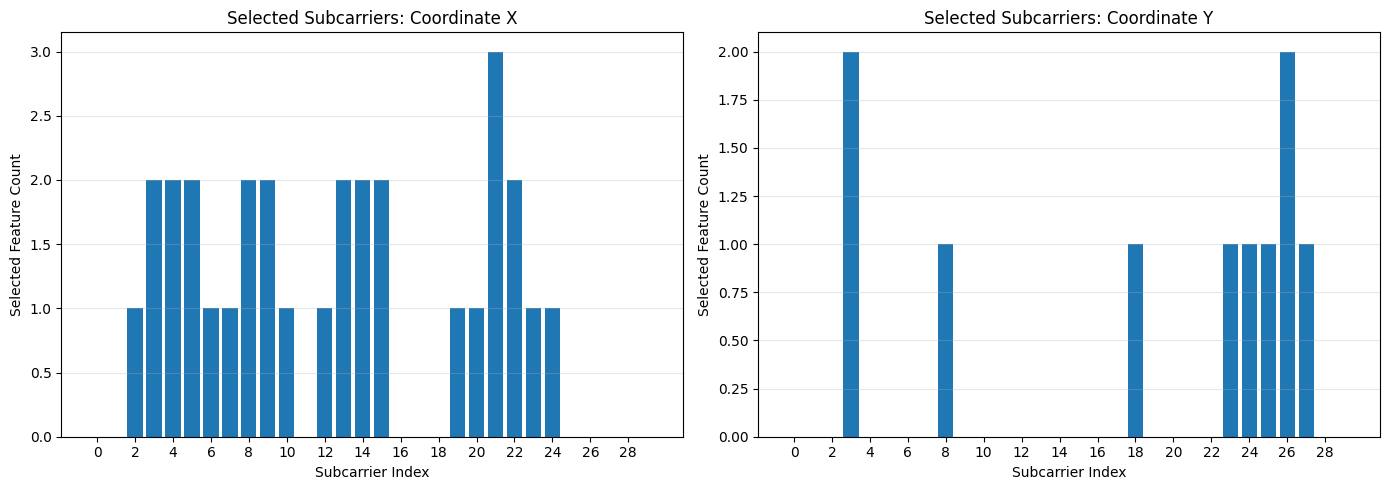


Selected feature analysis completed.


In [126]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# AXIS-SPECIFIC SELECTED FEATURE ANALYSIS
# =====================================================

N_CHANNELS = 6
N_SUBCARRIERS = 30

feature_records = []

for axis in ["X", "Y"]:

    pipeline = best_models[axis]["model"]
    selector = pipeline.named_steps["selector"]

    selected_indices = selector.get_support(indices=True)
    scores = selector.scores_

    for idx in selected_indices:

        # Feature extraction order:
        # First 180 = temporal mean
        # Next 180 = temporal std

        statistic_idx = idx // (N_CHANNELS * N_SUBCARRIERS)
        within_statistic = idx % (N_CHANNELS * N_SUBCARRIERS)

        channel_idx = within_statistic // N_SUBCARRIERS
        subcarrier_idx = within_statistic % N_SUBCARRIERS

        antenna_idx = channel_idx % 3 + 1

        feature_type = (
            "Amplitude" if channel_idx < 3 else "Phase"
        )

        statistic = (
            "Temporal Mean" if statistic_idx == 0
            else "Temporal STD"
        )

        feature_records.append({
            "Coordinate": axis,
            "Feature_Index": int(idx),
            "Antenna": antenna_idx,
            "Feature_Type": feature_type,
            "Statistic": statistic,
            "Subcarrier": subcarrier_idx,
            "F_Score": float(scores[idx])
        })

selected_features_df = pd.DataFrame(feature_records)

print("=== SELECTED CSI FEATURES ===")

display(
    selected_features_df.sort_values(
        ["Coordinate", "F_Score"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

# =====================================================
# FEATURE DISTRIBUTION BY ANTENNA
# =====================================================

antenna_distribution = (
    selected_features_df
    .groupby(["Coordinate", "Antenna"])
    .size()
    .unstack(fill_value=0)
)

print("\n=== SELECTED FEATURES BY ANTENNA ===")
display(antenna_distribution)

# =====================================================
# FEATURE DISTRIBUTION BY TYPE
# =====================================================

type_distribution = (
    selected_features_df
    .groupby(["Coordinate", "Feature_Type", "Statistic"])
    .size()
    .reset_index(name="Count")
)

print("\n=== SELECTED FEATURES BY TYPE ===")
display(type_distribution)

# =====================================================
# SUBCARRIER DISTRIBUTION
# =====================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, axis in enumerate(["X", "Y"]):

    subset = selected_features_df[
        selected_features_df["Coordinate"] == axis
    ]

    counts = (
        subset.groupby("Subcarrier")
        .size()
        .reindex(range(N_SUBCARRIERS), fill_value=0)
    )

    axes[i].bar(
        counts.index,
        counts.values
    )

    axes[i].set_title(
        f"Selected Subcarriers: Coordinate {axis}"
    )
    axes[i].set_xlabel("Subcarrier Index")
    axes[i].set_ylabel("Selected Feature Count")
    axes[i].set_xticks(range(0, N_SUBCARRIERS, 2))
    axes[i].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# =====================================================
# SAVE RESULTS
# =====================================================

selected_features_df.to_csv(
    "axis_specific_selected_features.csv",
    index=False
)

print("\nSelected feature analysis completed.")


In [127]:

import numpy as np

# =====================================================
# FIX FEATURE DIMENSIONS
# =====================================================

# Ambil data CSI yang sudah dinormalisasi
X_train_raw = np.asarray(
    X_train_normalized, dtype=np.float32
)

X_val_raw = np.asarray(
    X_val_normalized, dtype=np.float32
)

print("=== ORIGINAL CSI SHAPES ===")
print("Training:", X_train_raw.shape)
print("Validation:", X_val_raw.shape)

# =====================================================
# TEMPORAL FEATURE EXTRACTION
# =====================================================

def extract_csi_features(X):

    assert X.ndim == 4, (
        f"Expected 4D CSI, got {X.shape}"
    )

    # Expected: samples, channels, time, subcarriers
    assert X.shape[1:] == (6, 60, 30)

    temporal_mean = np.mean(X, axis=2)
    temporal_std = np.std(X, axis=2)

    # Flatten masing-masing menjadi 180 fitur
    mean_features = temporal_mean.reshape(
        X.shape[0], -1
    )

    std_features = temporal_std.reshape(
        X.shape[0], -1
    )

    # Mean terlebih dahulu, kemudian STD
    features = np.concatenate(
        [mean_features, std_features],
        axis=1
    )

    return features.astype(np.float32)


X_train_features = extract_csi_features(X_train_raw)
X_val_features = extract_csi_features(X_val_raw)

y_tr = np.asarray(y_train, dtype=np.float32)
y_va = np.asarray(y_val, dtype=np.float32)

# =====================================================
# VERIFICATION
# =====================================================

print("\n=== FEATURE VERIFICATION ===")
print("Training:", X_train_features.shape)
print("Validation:", X_val_features.shape)

assert X_train_features.shape == (63, 360)
assert X_val_features.shape == (13, 360)

assert np.isfinite(X_train_features).all()
assert np.isfinite(X_val_features).all()

assert y_tr.shape == (63, 2)
assert y_va.shape == (13, 2)

print("\nFEATURE EXTRACTION SUCCESSFUL")
print("Dataset ready for feature-group ablation.")


=== ORIGINAL CSI SHAPES ===
Training: (63, 6, 60, 30)
Validation: (13, 6, 60, 30)

=== FEATURE VERIFICATION ===
Training: (63, 360)
Validation: (13, 360)

FEATURE EXTRACTION SUCCESSFUL
Dataset ready for feature-group ablation.



=== COORDINATE X ===
All Features         | MAE: 1.1515 | Improvement: 51.64%
Amplitude            | MAE: 1.2694 | Improvement: 46.69%
Phase                | MAE: 1.3629 | Improvement: 42.76%
Temporal Mean        | MAE: 1.2672 | Improvement: 46.78%
Temporal STD         | MAE: 1.4213 | Improvement: 40.31%
Amplitude Mean       | MAE: 1.3461 | Improvement: 43.46%
Amplitude STD        | MAE: 1.3812 | Improvement: 41.99%
Phase Mean           | MAE: 1.3542 | Improvement: 43.12%
Phase STD            | MAE: 1.8554 | Improvement: 22.07%

=== COORDINATE Y ===
All Features         | MAE: 2.5323 | Improvement: 8.68%
Amplitude            | MAE: 2.8790 | Improvement: -3.83%
Phase                | MAE: 2.4633 | Improvement: 11.17%
Temporal Mean        | MAE: 2.5753 | Improvement: 7.13%
Temporal STD         | MAE: 2.6872 | Improvement: 3.09%
Amplitude Mean       | MAE: 2.9545 | Improvement: -6.55%
Amplitude STD        | MAE: 2.7945 | Improvement: -0.78%
Phase Mean           | MAE: 2.4571 | Improvemen

,Coordinate,Feature_Group,Feature_Count,MAE,RMSE,Baseline_MAE,Improvement_Percent,Prediction_STD
0,X,All Features,360,1.151538,1.558186,2.380952,51.635384,2.012539
1,X,Temporal Mean,180,1.267179,1.674405,2.380952,46.778461,1.829297
2,X,Amplitude,180,1.269359,1.713218,2.380952,46.686923,2.046443
3,X,Amplitude Mean,90,1.346090,1.790677,2.380952,43.464230,2.093483
4,X,Phase Mean,90,1.354167,1.756774,2.380952,43.124999,1.673327
5,X,Phase,180,1.362885,1.774877,2.380952,42.758846,1.751445
6,X,Amplitude STD,90,1.381218,1.650655,2.380952,41.988846,1.800201
7,X,Temporal STD,180,1.421282,1.691094,2.380952,40.306153,1.693248
8,X,Phase STD,90,1.855449,2.133378,2.380952,22.071153,1.103790
9,Y,Phase Mean,90,2.457115,2.868392,2.772893,11.388034,1.322324



=== BEST FEATURE GROUPS ===


,Coordinate,Feature_Group,Feature_Count,MAE,RMSE,Baseline_MAE,Improvement_Percent,Prediction_STD
0,X,All Features,360,1.151538,1.558186,2.380952,51.635384,2.012539
16,Y,Phase Mean,90,2.457115,2.868392,2.772893,11.388034,1.322324


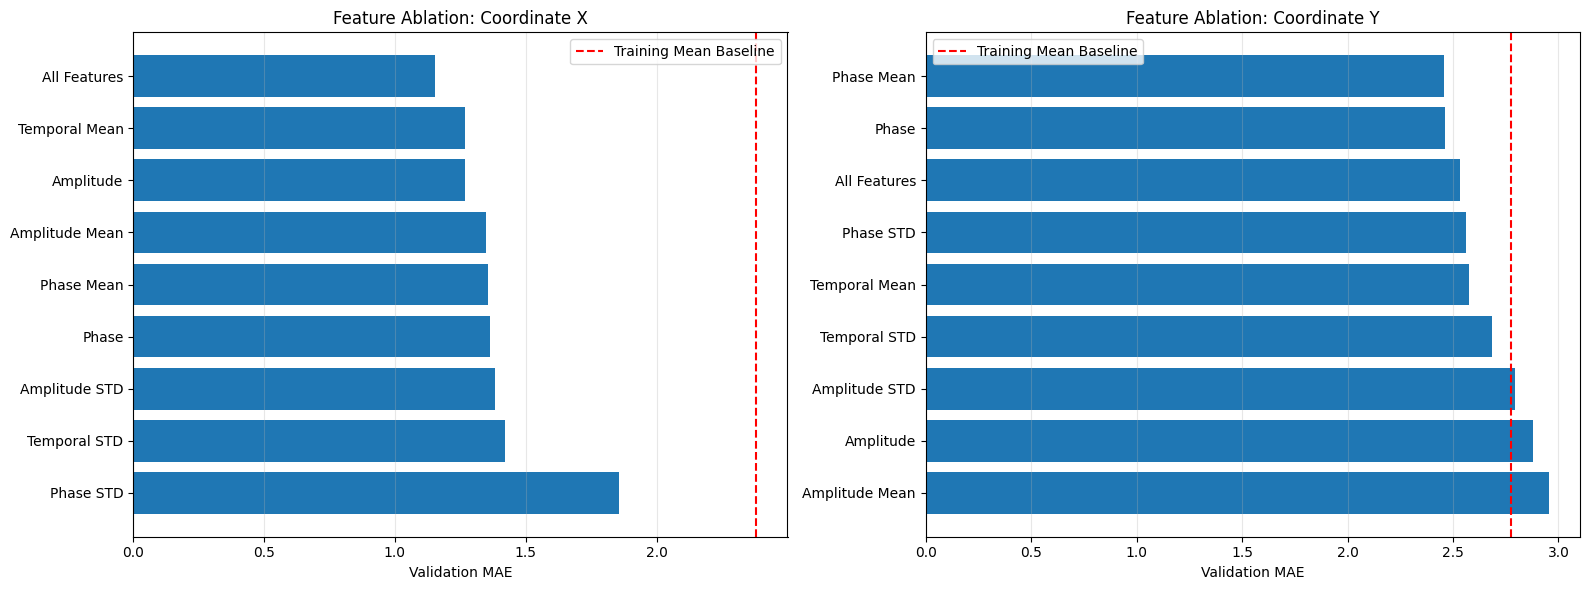

In [128]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# =====================================================
# CSI FEATURE-GROUP ABLATION
# =====================================================

SEED = 42

X_tr = X_train_features.copy()
X_va = X_val_features.copy()

y_tr = np.asarray(y_train, dtype=np.float32)
y_va = np.asarray(y_val, dtype=np.float32)

assert X_tr.shape[1] == 360
assert X_va.shape[1] == 360

# Feature ordering:
# 0:90     Amplitude Temporal Mean
# 90:180   Phase Temporal Mean
# 180:270  Amplitude Temporal STD
# 270:360  Phase Temporal STD

feature_groups = {
    "All Features": np.arange(360),

    "Amplitude": np.r_[
        0:90, 180:270
    ],

    "Phase": np.r_[
        90:180, 270:360
    ],

    "Temporal Mean": np.arange(0, 180),

    "Temporal STD": np.arange(180, 360),

    "Amplitude Mean": np.arange(0, 90),

    "Amplitude STD": np.arange(180, 270),

    "Phase Mean": np.arange(90, 180),

    "Phase STD": np.arange(270, 360)
}

results = []

for axis, coord in enumerate(["X", "Y"]):

    print(f"\n=== COORDINATE {coord} ===")

    target_train = y_tr[:, axis]
    target_val = y_va[:, axis]

    baseline_pred = np.full(
        len(target_val),
        target_train.mean()
    )

    baseline_mae = mean_absolute_error(
        target_val, baseline_pred
    )

    for group_name, indices in feature_groups.items():

        model = ExtraTreesRegressor(
            n_estimators=200,
            min_samples_leaf=2,
            max_features=0.7,
            random_state=SEED,
            n_jobs=-1
        )

        model.fit(
            X_tr[:, indices],
            target_train
        )

        predictions = model.predict(
            X_va[:, indices]
        )

        mae = mean_absolute_error(
            target_val, predictions
        )

        rmse = np.sqrt(
            mean_squared_error(
                target_val, predictions
            )
        )

        improvement = (
            (baseline_mae - mae)
            / baseline_mae * 100
        )

        results.append({
            "Coordinate": coord,
            "Feature_Group": group_name,
            "Feature_Count": len(indices),
            "MAE": mae,
            "RMSE": rmse,
            "Baseline_MAE": baseline_mae,
            "Improvement_Percent": improvement,
            "Prediction_STD": np.std(predictions)
        })

        print(
            f"{group_name:20s} | "
            f"MAE: {mae:.4f} | "
            f"Improvement: {improvement:.2f}%"
        )

# =====================================================
# RESULTS
# =====================================================

ablation_df = pd.DataFrame(results)

print("\n=== FEATURE-GROUP ABLATION RESULTS ===")

display(
    ablation_df.sort_values(
        ["Coordinate", "MAE"]
    ).reset_index(drop=True)
)

# =====================================================
# BEST CONFIGURATION PER COORDINATE
# =====================================================

best_groups = (
    ablation_df.sort_values("MAE")
    .groupby("Coordinate")
    .head(1)
    .sort_values("Coordinate")
)

print("\n=== BEST FEATURE GROUPS ===")
display(best_groups)

# =====================================================
# VISUALIZATION
# =====================================================

fig, axes = plt.subplots(
    1, 2, figsize=(16, 6)
)

for ax, coord in zip(axes, ["X", "Y"]):

    subset = (
        ablation_df[
            ablation_df["Coordinate"] == coord
        ]
        .sort_values("MAE")
    )

    ax.barh(
        subset["Feature_Group"],
        subset["MAE"]
    )

    ax.axvline(
        subset["Baseline_MAE"].iloc[0],
        color="red",
        linestyle="--",
        label="Training Mean Baseline"
    )

    ax.invert_yaxis()
    ax.set_title(f"Feature Ablation: Coordinate {coord}")
    ax.set_xlabel("Validation MAE")
    ax.legend()
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



=== COORDINATE X ===
All Features       | MAE: 1.5067 +/- 0.3060
Amplitude          | MAE: 1.4872 +/- 0.2967
Phase              | MAE: 1.6139 +/- 0.2739
Phase Mean         | MAE: 1.6078 +/- 0.2956
Temporal Mean      | MAE: 1.4935 +/- 0.2981

=== COORDINATE Y ===
All Features       | MAE: 2.3717 +/- 0.4223
Amplitude          | MAE: 2.6011 +/- 0.4360
Phase              | MAE: 2.2447 +/- 0.4190
Phase Mean         | MAE: 2.1956 +/- 0.3997
Temporal Mean      | MAE: 2.3073 +/- 0.4239

=== CROSS-VALIDATION RESULTS ===


,Coordinate,Feature_Group,Mean_MAE,STD_MAE,Baseline_MAE,Improvement_Percent
0,X,Amplitude,1.487213,0.296680,2.326191,36.066580
1,X,Temporal Mean,1.493464,0.298069,2.326191,35.797859
2,X,All Features,1.506739,0.305988,2.326191,35.227171
3,X,Phase Mean,1.607800,0.295566,2.326191,30.882693
4,X,Phase,1.613915,0.273905,2.326191,30.619829
5,Y,Phase Mean,2.195642,0.399714,2.533599,13.339025
6,Y,Phase,2.244737,0.419016,2.533599,11.401240
7,Y,Temporal Mean,2.307315,0.423890,2.533599,8.931329
8,Y,All Features,2.371745,0.422254,2.533599,6.388296
9,Y,Amplitude,2.601147,0.436042,2.533599,-2.666067


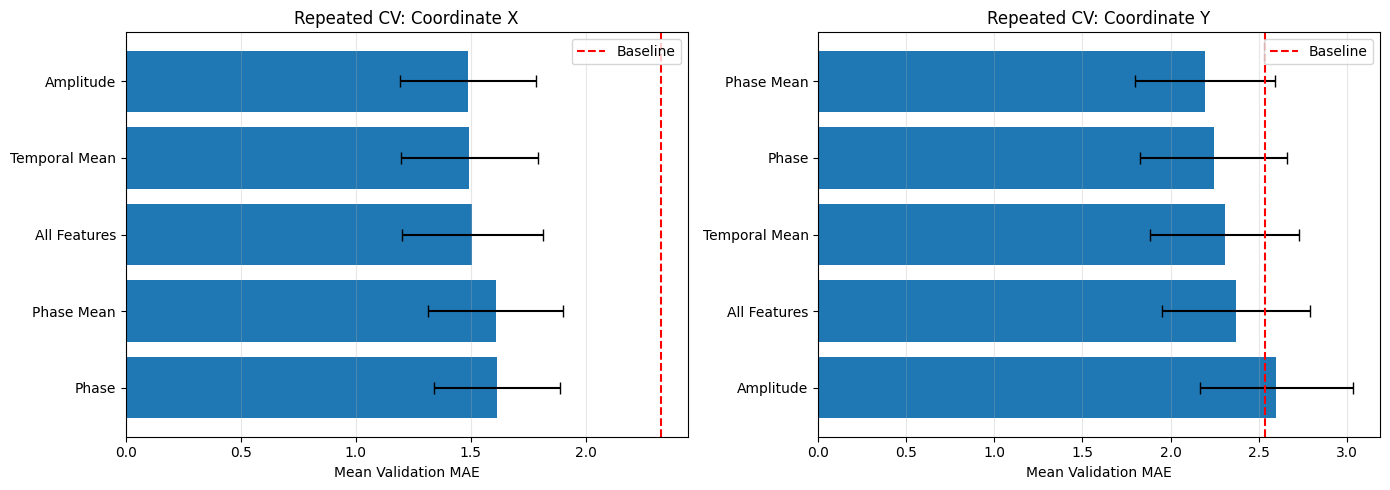

In [129]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error

# =====================================================
# REPEATED CROSS-VALIDATION
# =====================================================

SEED = 42

X_all = np.vstack([
    X_train_features,
    X_val_features
]).astype(np.float32)

y_all = np.vstack([
    y_train,
    y_val
]).astype(np.float32)

assert X_all.ndim == 2
assert X_all.shape[1] == 360
assert y_all.shape == (len(X_all), 2)

feature_configs = {
    "All Features": np.arange(360),
    "Amplitude": np.r_[0:90, 180:270],
    "Phase": np.r_[90:180, 270:360],
    "Phase Mean": np.arange(90, 180),
    "Temporal Mean": np.arange(0, 180)
}

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=SEED
)

results = []

for axis, coord in enumerate(["X", "Y"]):

    print(f"\n=== COORDINATE {coord} ===")

    for config_name, indices in feature_configs.items():

        fold_maes = []
        baseline_maes = []

        for train_idx, val_idx in cv.split(X_all):

            X_train_fold = X_all[train_idx][:, indices]
            X_val_fold = X_all[val_idx][:, indices]

            y_train_fold = y_all[train_idx, axis]
            y_val_fold = y_all[val_idx, axis]

            model = ExtraTreesRegressor(
                n_estimators=100,
                min_samples_leaf=2,
                max_features=0.7,
                random_state=SEED,
                n_jobs=-1
            )

            model.fit(X_train_fold, y_train_fold)

            pred = model.predict(X_val_fold)

            fold_maes.append(
                mean_absolute_error(y_val_fold, pred)
            )

            baseline_pred = np.full(
                len(y_val_fold),
                y_train_fold.mean()
            )

            baseline_maes.append(
                mean_absolute_error(
                    y_val_fold, baseline_pred
                )
            )

        results.append({
            "Coordinate": coord,
            "Feature_Group": config_name,
            "Mean_MAE": np.mean(fold_maes),
            "STD_MAE": np.std(fold_maes, ddof=1),
            "Baseline_MAE": np.mean(baseline_maes),
            "Improvement_Percent": (
                1 - np.mean(fold_maes)
                / np.mean(baseline_maes)
            ) * 100,
            "Fold_MAEs": fold_maes
        })

        print(
            f"{config_name:18s} | "
            f"MAE: {np.mean(fold_maes):.4f} "
            f"+/- {np.std(fold_maes, ddof=1):.4f}"
        )

# =====================================================
# RESULTS
# =====================================================

cv_df = pd.DataFrame(results)

print("\n=== CROSS-VALIDATION RESULTS ===")

display(
    cv_df.drop(columns=["Fold_MAEs"])
    .sort_values(["Coordinate", "Mean_MAE"])
    .reset_index(drop=True)
)

# =====================================================
# VISUALIZATION
# =====================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, coord in zip(axes, ["X", "Y"]):

    subset = cv_df[
        cv_df["Coordinate"] == coord
    ].sort_values("Mean_MAE")

    ax.barh(
        subset["Feature_Group"],
        subset["Mean_MAE"],
        xerr=subset["STD_MAE"],
        capsize=4
    )

    ax.axvline(
        subset["Baseline_MAE"].iloc[0],
        color="red",
        linestyle="--",
        label="Baseline"
    )

    ax.invert_yaxis()
    ax.set_title(f"Repeated CV: Coordinate {coord}")
    ax.set_xlabel("Mean Validation MAE")
    ax.legend()
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


Feature shape: (76, 360)
Target shape: (76, 2)
Fold 1/15 completed | Elapsed: 0.4s
Fold 2/15 completed | Elapsed: 0.8s
Fold 3/15 completed | Elapsed: 1.1s
Fold 4/15 completed | Elapsed: 1.5s
Fold 5/15 completed | Elapsed: 1.9s
Fold 6/15 completed | Elapsed: 2.3s
Fold 7/15 completed | Elapsed: 2.6s
Fold 8/15 completed | Elapsed: 3.0s
Fold 9/15 completed | Elapsed: 3.4s
Fold 10/15 completed | Elapsed: 3.8s
Fold 11/15 completed | Elapsed: 4.1s
Fold 12/15 completed | Elapsed: 4.5s
Fold 13/15 completed | Elapsed: 4.9s
Fold 14/15 completed | Elapsed: 5.2s
Fold 15/15 completed | Elapsed: 5.6s

=== AXIS-SPECIFIC COMPARISON ===


,Configuration,Mean_MDE,STD_MDE,Mean_RMSE,X_MAE,Y_MAE,Baseline_MDE,Improvement_Percent
0,All Features,3.031893,0.564166,3.366452,1.526544,2.393745,3.751969,19.191933
1,Axis-Specific,2.907225,0.532102,3.216591,1.548112,2.207525,3.751969,22.514677



=== PAIRED MDE DIFFERENCE ===
Mean difference: 0.1247
STD difference: 0.1644
Axis-specific better: 10/15 folds

Total execution time: 5.64s


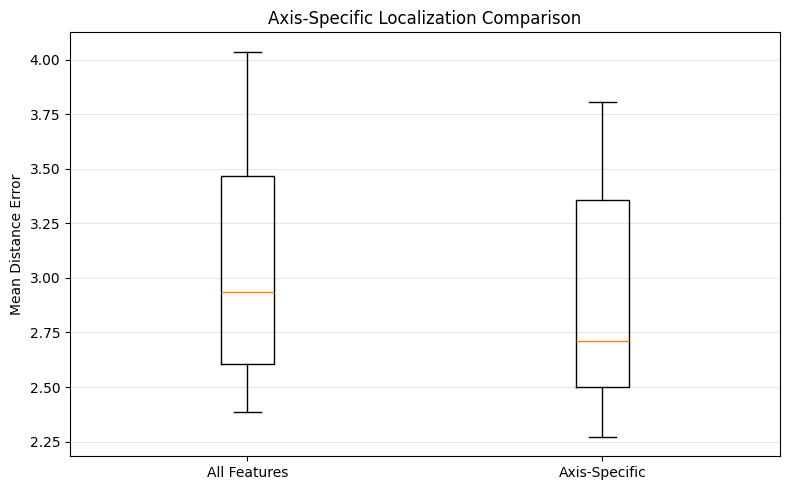

In [130]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import RepeatedKFold

SEED = 42
N_ESTIMATORS = 40

# ==========================================
# 1. DATA PREPARATION
# ==========================================

X = np.vstack([
    X_train_features,
    X_val_features
]).astype(np.float32)

y = np.vstack([
    y_train,
    y_val
]).astype(np.float32)

assert X.shape == (76, 360), X.shape
assert y.shape == (76, 2), y.shape
assert np.isfinite(X).all()
assert np.isfinite(y).all()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

# IMPORTANT:
# Assumed feature ordering:
# [Amplitude Mean: 90,
#  Phase Mean: 90,
#  Amplitude STD: 90,
#  Phase STD: 90]
#
# Verify this matches the feature extraction
# code before interpreting the results.

amplitude_idx = np.r_[0:90, 180:270]
phase_mean_idx = np.arange(90, 180)
all_idx = np.arange(360)

configs = {
    "All Features": {
        "X": all_idx,
        "Y": all_idx
    },
    "Axis-Specific": {
        "X": amplitude_idx,
        "Y": phase_mean_idx
    }
}

# ==========================================
# 2. CROSS-VALIDATION
# ==========================================

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=SEED
)

results = []
start = time.time()

splits = list(cv.split(X))
total_folds = len(splits)

for fold, (tr_idx, va_idx) in enumerate(splits, 1):

    y_tr = y[tr_idx]
    y_va = y[va_idx]

    baseline_pred = np.tile(
        y_tr.mean(axis=0),
        (len(va_idx), 1)
    )

    baseline_mde = np.linalg.norm(
        baseline_pred - y_va,
        axis=1
    ).mean()

    for config_name, feature_map in configs.items():

        predictions = np.zeros(
            (len(va_idx), 2),
            dtype=np.float32
        )

        for axis, coord in enumerate(["X", "Y"]):

            idx = feature_map[coord]

            model = ExtraTreesRegressor(
                n_estimators=N_ESTIMATORS,
                min_samples_leaf=2,
                max_features=0.7,
                random_state=SEED,
                n_jobs=2
            )

            model.fit(
                X[tr_idx][:, idx],
                y_tr[:, axis]
            )

            predictions[:, axis] = model.predict(
                X[va_idx][:, idx]
            )

        errors = predictions - y_va

        distance_errors = np.linalg.norm(
            errors, axis=1
        )

        results.append({
            "Fold": fold,
            "Configuration": config_name,
            "MDE": distance_errors.mean(),
            "RMSE": np.sqrt(
                np.mean(distance_errors ** 2)
            ),
            "X_MAE": np.abs(errors[:, 0]).mean(),
            "Y_MAE": np.abs(errors[:, 1]).mean(),
            "Baseline_MDE": baseline_mde
        })

    print(
        f"Fold {fold}/{total_folds} completed | "
        f"Elapsed: {time.time()-start:.1f}s",
        flush=True
    )

# ==========================================
# 3. RESULTS
# ==========================================

results_df = pd.DataFrame(results)

summary = (
    results_df.groupby("Configuration")
    .agg(
        Mean_MDE=("MDE", "mean"),
        STD_MDE=("MDE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        X_MAE=("X_MAE", "mean"),
        Y_MAE=("Y_MAE", "mean"),
        Baseline_MDE=("Baseline_MDE", "mean")
    )
    .reset_index()
)

summary["Improvement_Percent"] = (
    1 -
    summary["Mean_MDE"] /
    summary["Baseline_MDE"]
) * 100

print("\n=== AXIS-SPECIFIC COMPARISON ===")
display(summary)

# ==========================================
# 4. PAIRED COMPARISON
# ==========================================

paired = results_df.pivot(
    index="Fold",
    columns="Configuration",
    values="MDE"
)

difference = (
    paired["All Features"] -
    paired["Axis-Specific"]
)

print("\n=== PAIRED MDE DIFFERENCE ===")
print(f"Mean difference: {difference.mean():.4f}")
print(f"STD difference: {difference.std():.4f}")
print(
    f"Axis-specific better: "
    f"{(difference > 0).sum()}/{len(difference)} folds"
)

print(
    f"\nTotal execution time: "
    f"{time.time()-start:.2f}s"
)

# ==========================================
# 5. VISUALIZATION
# ==========================================

fig, ax = plt.subplots(figsize=(8, 5))

data = [
    results_df.loc[
        results_df["Configuration"] == name,
        "MDE"
    ].values
    for name in configs
]

ax.boxplot(
    data,
    tick_labels=list(configs.keys())
)

ax.set_title("Axis-Specific Localization Comparison")
ax.set_ylabel("Mean Distance Error")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Fold 1/5 | Selected X: Amplitude Mean | Selected Y: Phase Mean | Elapsed: 2.6s
Fold 2/5 | Selected X: Amplitude Mean | Selected Y: Phase Mean | Elapsed: 5.3s
Fold 3/5 | Selected X: Amplitude Mean | Selected Y: Phase Mean | Elapsed: 8.0s
Fold 4/5 | Selected X: Amplitude | Selected Y: Phase Mean | Elapsed: 10.7s
Fold 5/5 | Selected X: Amplitude Mean | Selected Y: Phase Mean | Elapsed: 13.4s

=== NESTED CV RESULTS ===


,Configuration,Mean_MDE,STD_MDE,Mean_RMSE,X_MAE,Y_MAE
0,All Features,3.052912,0.629493,3.392960,1.587688,2.378642
1,Mean Baseline,3.755057,0.477643,3.948055,2.368852,2.506127
2,Nested Axis-Specific,2.916462,0.580634,3.248042,1.543118,2.242059



=== FEATURE SELECTION BY FOLD ===


,Fold,X,Y
0,1,Amplitude Mean,Phase Mean
1,2,Amplitude Mean,Phase Mean
2,3,Amplitude Mean,Phase Mean
3,4,Amplitude,Phase Mean
4,5,Amplitude Mean,Phase Mean



=== FEATURE SELECTION FREQUENCY ===
X {'Amplitude Mean': 4, 'Amplitude': 1}
Y {'Phase Mean': 5}

=== PAIRED COMPARISON ===
Mean MDE difference: 0.13645034149314136
Nested model better: 4 / 5 folds


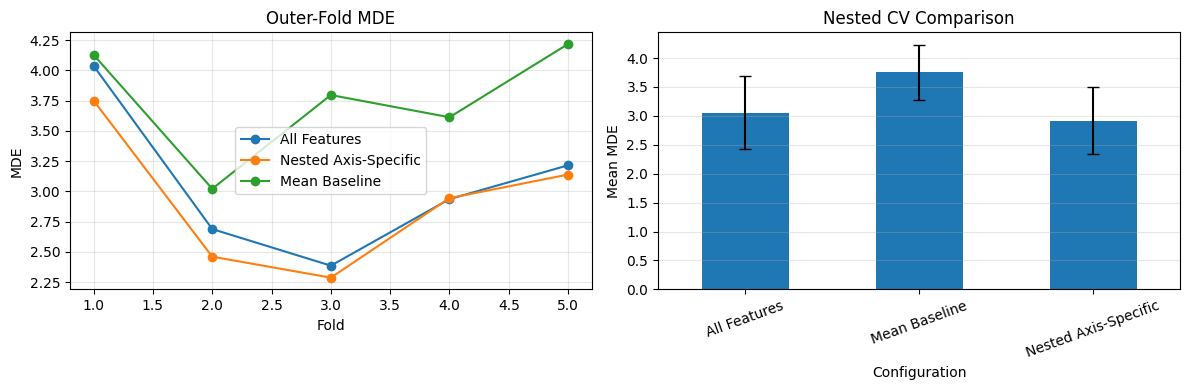


Total execution time: 13.85s


In [131]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
import time

SEED = 42
N_TREES = 40

# ==========================================
# 1. DATA PREPARATION
# ==========================================

X = np.vstack([
    X_train_features,
    X_val_features
]).astype(np.float32)

y = np.vstack([
    y_train,
    y_val
]).astype(np.float32)

assert X.shape == (76, 360), X.shape
assert y.shape == (76, 2), y.shape
assert np.isfinite(X).all()
assert np.isfinite(y).all()

# Assumed extraction order:
# Amplitude Mean, Phase Mean,
# Amplitude STD, Phase STD
# Each block contains 90 features.
# VERIFY against the extraction function.

feature_groups = {
    "All Features": np.arange(360),
    "Amplitude": np.r_[0:90, 180:270],
    "Phase": np.r_[90:180, 270:360],
    "Amplitude Mean": np.arange(0, 90),
    "Phase Mean": np.arange(90, 180)
}

def make_model():
    return ExtraTreesRegressor(
        n_estimators=N_TREES,
        min_samples_leaf=2,
        max_features=0.7,
        random_state=SEED,
        n_jobs=2
    )

# ==========================================
# 2. NESTED CROSS-VALIDATION
# ==========================================

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

results = []
selected_groups = []
start = time.time()

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X), 1
):

    X_outer_tr = X[train_idx]
    X_outer_va = X[val_idx]

    y_outer_tr = y[train_idx]
    y_outer_va = y[val_idx]

    inner_cv = KFold(
        n_splits=3,
        shuffle=True,
        random_state=SEED + fold
    )

    axis_predictions = np.zeros(
        (len(val_idx), 2)
    )

    all_predictions = np.zeros(
        (len(val_idx), 2)
    )

    fold_selection = {"Fold": fold}

    for axis, coord in enumerate(["X", "Y"]):

        group_scores = {}

        # Inner CV: select feature group
        for group_name, idx in feature_groups.items():

            errors = []

            for inner_tr, inner_va in inner_cv.split(
                X_outer_tr
            ):

                model = make_model()

                model.fit(
                    X_outer_tr[inner_tr][:, idx],
                    y_outer_tr[inner_tr, axis]
                )

                pred = model.predict(
                    X_outer_tr[inner_va][:, idx]
                )

                errors.append(
                    mean_absolute_error(
                        y_outer_tr[inner_va, axis],
                        pred
                    )
                )

            group_scores[group_name] = np.mean(errors)

        best_group = min(
            group_scores,
            key=group_scores.get
        )

        fold_selection[coord] = best_group

        # Fit selected model on outer training
        selected_idx = feature_groups[best_group]

        selected_model = make_model()
        selected_model.fit(
            X_outer_tr[:, selected_idx],
            y_outer_tr[:, axis]
        )

        axis_predictions[:, axis] = (
            selected_model.predict(
                X_outer_va[:, selected_idx]
            )
        )

        # Reference model using all features
        all_model = make_model()
        all_model.fit(
            X_outer_tr,
            y_outer_tr[:, axis]
        )

        all_predictions[:, axis] = (
            all_model.predict(X_outer_va)
        )

    selected_groups.append(fold_selection)

    baseline = np.tile(
        y_outer_tr.mean(axis=0),
        (len(val_idx), 1)
    )

    for name, pred in [
        ("All Features", all_predictions),
        ("Nested Axis-Specific", axis_predictions),
        ("Mean Baseline", baseline)
    ]:

        errors = pred - y_outer_va
        distances = np.linalg.norm(errors, axis=1)

        results.append({
            "Fold": fold,
            "Configuration": name,
            "MDE": distances.mean(),
            "RMSE": np.sqrt(
                np.mean(distances ** 2)
            ),
            "X_MAE": np.abs(errors[:, 0]).mean(),
            "Y_MAE": np.abs(errors[:, 1]).mean()
        })

    print(
        f"Fold {fold}/5 | "
        f"Selected X: {fold_selection['X']} | "
        f"Selected Y: {fold_selection['Y']} | "
        f"Elapsed: {time.time()-start:.1f}s",
        flush=True
    )

# ==========================================
# 3. SUMMARY
# ==========================================

results_df = pd.DataFrame(results)
selection_df = pd.DataFrame(selected_groups)

summary = (
    results_df.groupby("Configuration")
    .agg(
        Mean_MDE=("MDE", "mean"),
        STD_MDE=("MDE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        X_MAE=("X_MAE", "mean"),
        Y_MAE=("Y_MAE", "mean")
    )
    .reset_index()
)

print("\n=== NESTED CV RESULTS ===")
display(summary)

print("\n=== FEATURE SELECTION BY FOLD ===")
display(selection_df)

print("\n=== FEATURE SELECTION FREQUENCY ===")

for coord in ["X", "Y"]:
    print(coord, dict(Counter(selection_df[coord])))

# ==========================================
# 4. PAIRED DIFFERENCE
# ==========================================

paired = results_df.pivot(
    index="Fold",
    columns="Configuration",
    values="MDE"
)

diff = (
    paired["All Features"] -
    paired["Nested Axis-Specific"]
)

print("\n=== PAIRED COMPARISON ===")
print("Mean MDE difference:", diff.mean())
print(
    "Nested model better:",
    (diff > 0).sum(), "/ 5 folds"
)

# ==========================================
# 5. VISUALIZATION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name in [
    "All Features",
    "Nested Axis-Specific",
    "Mean Baseline"
]:
    subset = results_df[
        results_df["Configuration"] == name
    ]
    axes[0].plot(
        subset["Fold"],
        subset["MDE"],
        marker="o",
        label=name
    )

axes[0].set_title("Outer-Fold MDE")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("MDE")
axes[0].legend()
axes[0].grid(alpha=0.3)

plot_df = summary.set_index("Configuration")

plot_df["Mean_MDE"].plot(
    kind="bar",
    yerr=plot_df["STD_MDE"],
    capsize=4,
    ax=axes[1]
)

axes[1].set_title("Nested CV Comparison")
axes[1].set_ylabel("Mean MDE")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print(
    f"\nTotal execution time: "
    f"{time.time()-start:.2f}s"
)


In [132]:

import numpy as np

print("=== DATASET VARIABLE DIAGNOSTIC ===")

keywords = [
    "test", "train", "val",
    "feature", "csi", "target"
]

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if not any(
        keyword in name.lower()
        for keyword in keywords
    ):
        continue

    if isinstance(value, np.ndarray):
        print(
            f"{name:30s} | "
            f"Shape: {value.shape} | "
            f"Dtype: {value.dtype}"
        )

print("\n=== FEATURE EXTRACTION FUNCTIONS ===")

import inspect

for name, obj in list(globals().items()):

    if (
        inspect.isfunction(obj)
        and any(
            key in name.lower()
            for key in [
                "feature", "extract",
                "temporal", "statistic"
            ]
        )
    ):
        print(name)


=== DATASET VARIABLE DIAGNOSTIC ===
train_idx                      | Shape: (61,) | Dtype: int64
val_idx                        | Shape: (15,) | Dtype: int64
test_idx                       | Shape: (14,) | Dtype: int64
X_train                        | Shape: (63, 6, 60, 30) | Dtype: float32
X_val                          | Shape: (13, 6, 60, 30) | Dtype: float32
X_test                         | Shape: (14, 6, 60, 30) | Dtype: float32
y_train                        | Shape: (63, 2) | Dtype: float32
y_val                          | Shape: (13, 2) | Dtype: float32
y_test                         | Shape: (14, 2) | Dtype: float32
X_train_processed              | Shape: (63, 6, 60, 30) | Dtype: float32
X_val_processed                | Shape: (13, 6, 60, 30) | Dtype: float32
X_test_processed               | Shape: (14, 6, 60, 30) | Dtype: float32
X_train_normalized             | Shape: (63, 6, 60, 30) | Dtype: float32
X_val_normalized               | Shape: (13, 6, 60, 30) | Dtype: float32
X_

In [133]:

import numpy as np
import inspect

print("=== FEATURE COMPATIBILITY CHECK ===")

pairs = [
    ("Training", X_train_features, X_train_knn),
    ("Validation", X_val_features, X_val_knn)
]

for name, a, b in pairs:
    a = np.asarray(a)
    b = np.asarray(b)

    print(f"\n{name}")
    print("Feature shape:", a.shape)
    print("KNN shape:", b.shape)

    if a.shape == b.shape:
        print("Exactly equal:", np.array_equal(a, b))
        print("Numerically close:",
              np.allclose(a, b, rtol=1e-5, atol=1e-6))
        print("Mean absolute difference:",
              np.mean(np.abs(a - b)))
        print("Maximum absolute difference:",
              np.max(np.abs(a - b)))
    else:
        print("Shapes do not match")

print("\n=== EXTRACTION FUNCTION DEFINITIONS ===")

for name in [
    "extract_temporal_dynamics",
    "extract_csi_features",
    "extract_features"
]:
    func = globals().get(name)

    if callable(func):
        print(f"\n{name}")
        print("Signature:", inspect.signature(func))
        try:
            print(inspect.getsource(func))
        except (OSError, TypeError):
            print("Source code unavailable")


=== FEATURE COMPATIBILITY CHECK ===

Training
Feature shape: (63, 360)
KNN shape: (63, 360)
Exactly equal: False
Numerically close: False
Mean absolute difference: 0.4064081
Maximum absolute difference: 3.4019465

Validation
Feature shape: (13, 360)
KNN shape: (13, 360)
Exactly equal: False
Numerically close: False
Mean absolute difference: 0.42583272
Maximum absolute difference: 3.6913793

=== EXTRACTION FUNCTION DEFINITIONS ===

extract_temporal_dynamics
Signature: (X)
def extract_temporal_dynamics(X):
    """
    Input : (samples, channels, time, subcarriers)
    Output: (samples, channels * subcarriers * 2)
    """

    if X.ndim != 4:
        raise ValueError(
            f"Expected 4D CSI input, received {X.shape}"
        )

    temporal_mean = np.mean(X, axis=2)
    temporal_std = np.std(X, axis=2)

    mean_features = temporal_mean.reshape(len(X), -1)
    std_features = temporal_std.reshape(len(X), -1)

    return np.concatenate(
        [mean_features, std_features],
        

In [134]:

import numpy as np
import pandas as pd

# =====================================================
# IDENTIFY EXACT FEATURE EXTRACTION SOURCE
# =====================================================

sources = {
    "Raw CSI": (
        X_train,
        X_val,
        X_test
    ),
    "Processed CSI": (
        X_train_processed,
        X_val_processed,
        X_test_processed
    ),
    "Normalized CSI": (
        X_train_normalized,
        X_val_normalized,
        X_test_normalized
    )
}

reference_train = np.asarray(
    X_train_features, dtype=np.float32
)

reference_val = np.asarray(
    X_val_features, dtype=np.float32
)

results = []

for name, (train, val, test) in sources.items():

    train_feat = extract_csi_features(train)
    val_feat = extract_csi_features(val)

    train_diff = np.abs(
        train_feat - reference_train
    )

    val_diff = np.abs(
        val_feat - reference_val
    )

    train_match = np.allclose(
        train_feat,
        reference_train,
        rtol=1e-5,
        atol=1e-6
    )

    val_match = np.allclose(
        val_feat,
        reference_val,
        rtol=1e-5,
        atol=1e-6
    )

    results.append({
        "Source": name,
        "Train_MAE_Diff": train_diff.mean(),
        "Val_MAE_Diff": val_diff.mean(),
        "Train_Max_Diff": train_diff.max(),
        "Val_Max_Diff": val_diff.max(),
        "Train_Match": train_match,
        "Val_Match": val_match
    })

comparison_df = pd.DataFrame(results)

print("=== FEATURE SOURCE IDENTIFICATION ===")
display(comparison_df)

valid_sources = comparison_df[
    comparison_df["Train_Match"]
    & comparison_df["Val_Match"]
]

if len(valid_sources) == 1:

    selected_source = valid_sources.iloc[0]["Source"]

    X_test_features = extract_csi_features(
        sources[selected_source][2]
    )

    print("\nFEATURE SOURCE IDENTIFIED")
    print("Source:", selected_source)
    print("Test shape:", X_test_features.shape)

elif len(valid_sources) > 1:

    print("\nMultiple matching sources detected.")
    print("Verify preprocessing history before proceeding.")

else:

    print("\nNO EXACT MATCH FOUND")
    print("Feature extraction pipeline needs further inspection.")


=== FEATURE SOURCE IDENTIFICATION ===


,Source,Train_MAE_Diff,Val_MAE_Diff,Train_Max_Diff,Val_Max_Diff,Train_Match,Val_Match
0,Raw CSI,6.322108,6.302464,35.501896,35.143559,False,False
1,Processed CSI,6.417886,6.411868,35.466408,35.136467,False,False
2,Normalized CSI,0.000000,0.000000,0.000000,0.000000,True,True



FEATURE SOURCE IDENTIFIED
Source: Normalized CSI
Test shape: (14, 360)


In [135]:

import numpy as np
from sklearn.ensemble import ExtraTreesRegressor

# =====================================================
# FINAL MODEL PREPARATION
# =====================================================

SEED = 42

# Verify feature extraction
X_test_features = extract_csi_features(
    X_test_normalized
)

assert X_test_features.shape == (14, 360)
assert np.isfinite(X_test_features).all()

# Combine training and validation
X_dev = np.concatenate([
    X_train_features,
    X_val_features
], axis=0).astype(np.float32)

y_dev = np.concatenate([
    y_train,
    y_val
], axis=0).astype(np.float32)

assert X_dev.shape == (76, 360)
assert y_dev.shape == (76, 2)

# Feature layout:
# Mean: 0:180
# STD : 180:360
#
# Channels 0:3 = amplitude
# Channels 3:6 = phase
# Assumes channel ordering verified.

amplitude_mean_idx = np.arange(0, 90)
phase_mean_idx = np.arange(90, 180)

# Check feature indices
assert len(amplitude_mean_idx) == 90
assert len(phase_mean_idx) == 90

# Final model configuration
# Verify these hyperparameters match
# the nested-CV model before reporting results.

def make_model():
    return ExtraTreesRegressor(
        n_estimators=40,
        min_samples_leaf=2,
        max_features=0.7,
        random_state=SEED,
        n_jobs=2
    )

model_x = make_model()
model_y = make_model()

# Train on development data only
model_x.fit(
    X_dev[:, amplitude_mean_idx],
    y_dev[:, 0]
)

model_y.fit(
    X_dev[:, phase_mean_idx],
    y_dev[:, 1]
)

print("=== FINAL MODEL TRAINING ===")
print("Development samples:", len(X_dev))
print("Test samples:", len(X_test_features))
print("X features:", len(amplitude_mean_idx))
print("Y features:", len(phase_mean_idx))
print("Training completed.")

# Generate predictions without evaluating
pred_x = model_x.predict(
    X_test_features[:, amplitude_mean_idx]
)

pred_y = model_y.predict(
    X_test_features[:, phase_mean_idx]
)

final_predictions = np.column_stack([
    pred_x, pred_y
])

assert final_predictions.shape == (14, 2)
assert np.isfinite(final_predictions).all()

print("Prediction shape:", final_predictions.shape)
print("Predictions generated successfully.")


=== FINAL MODEL TRAINING ===
Development samples: 76
Test samples: 14
X features: 90
Y features: 90
Training completed.
Prediction shape: (14, 2)
Predictions generated successfully.



=== FINAL TEST RESULTS ===


,Configuration,MDE,Median_Error,Position_RMSE,X_MAE,Y_MAE,P90_Error
0,Mean Baseline,3.2977,3.6911,3.7264,1.9135,2.4981,5.3033
1,All Features,3.1168,2.9924,3.4478,1.7827,2.2000,4.5395
2,Axis-Specific,2.9655,2.5023,3.2028,1.6021,2.2485,4.1357



=== RELATIVE IMPROVEMENT ===
Axis-Specific vs Baseline: 10.07%
Axis-Specific vs All Features: 4.86%

=== PER-LOCATION TEST ERRORS ===


,Actual_X,Actual_Y,Predicted_X,Predicted_Y,Baseline_Error,All_Features_Error,Axis_Specific_Error
0,1.0,0.0,0.5375,4.2000,5.4932,4.6807,4.2254
1,8.0,6.0,5.3667,3.0875,4.1443,3.4202,3.9265
2,4.0,4.0,5.1792,2.8625,0.5298,2.5203,1.6384
3,6.0,9.0,6.0833,6.6583,4.8603,2.4730,2.3431
4,4.0,0.0,4.3625,2.0458,4.5151,2.8150,2.0777
5,3.0,5.0,4.9917,5.6708,1.2319,1.6424,2.1016
6,1.0,8.0,4.2417,5.9042,4.6867,4.2100,3.8602
7,2.0,8.0,3.7292,6.6458,4.0868,3.1699,2.1963
8,5.0,6.0,4.4917,4.1917,1.7219,0.9463,1.8784
9,3.0,3.0,4.9250,4.8750,1.8895,2.6187,2.6872


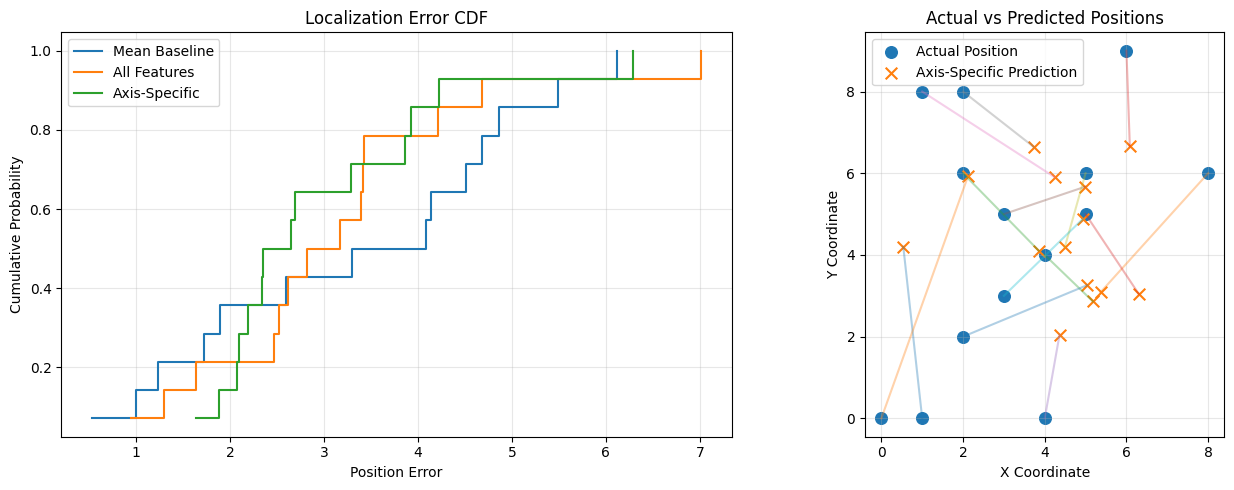


FINAL EVALUATION COMPLETED


In [136]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import ExtraTreesRegressor

# =====================================================
# FINAL LOCALIZATION EVALUATION
# =====================================================

SEED = 42

X_te = np.asarray(
    X_test_features, dtype=np.float32
)

y_te = np.asarray(
    y_test, dtype=np.float32
)

assert X_te.shape == (14, 360)
assert y_te.shape == (14, 2)
assert np.isfinite(X_te).all()
assert np.isfinite(y_te).all()

# ==========================================
# 1. MEAN POSITION BASELINE
# ==========================================

baseline_predictions = np.tile(
    y_dev.mean(axis=0),
    (len(y_te), 1)
)

# ==========================================
# 2. ALL FEATURES MODEL
# ==========================================

all_predictions = np.zeros(
    (len(y_te), 2),
    dtype=np.float64
)

for axis in range(2):

    model = ExtraTreesRegressor(
        n_estimators=40,
        min_samples_leaf=2,
        max_features=0.7,
        random_state=SEED,
        n_jobs=2
    )

    model.fit(
        X_dev,
        y_dev[:, axis]
    )

    all_predictions[:, axis] = model.predict(
        X_te
    )

# ==========================================
# 3. AXIS-SPECIFIC MODEL
# ==========================================

axis_predictions = np.asarray(
    final_predictions,
    dtype=np.float64
)

predictions = {
    "Mean Baseline": baseline_predictions,
    "All Features": all_predictions,
    "Axis-Specific": axis_predictions
}

# ==========================================
# 4. EVALUATION METRICS
# ==========================================

results = []
sample_errors = {}

for name, pred in predictions.items():

    errors = pred - y_te

    distances = np.linalg.norm(
        errors, axis=1
    )

    sample_errors[name] = distances

    results.append({
        "Configuration": name,
        "MDE": np.mean(distances),
        "Median_Error": np.median(distances),
        "Position_RMSE": np.sqrt(
            np.mean(distances ** 2)
        ),
        "X_MAE": np.mean(
            np.abs(errors[:, 0])
        ),
        "Y_MAE": np.mean(
            np.abs(errors[:, 1])
        ),
        "P90_Error": np.percentile(
            distances, 90
        )
    })

final_results_df = pd.DataFrame(results)

print("\n=== FINAL TEST RESULTS ===")
display(final_results_df.round(4))

# ==========================================
# 5. RELATIVE IMPROVEMENT
# ==========================================

mde = final_results_df.set_index(
    "Configuration"
)["MDE"]

print("\n=== RELATIVE IMPROVEMENT ===")

print(
    "Axis-Specific vs Baseline:",
    f"{(1 - mde['Axis-Specific'] / mde['Mean Baseline']) * 100:.2f}%"
)

print(
    "Axis-Specific vs All Features:",
    f"{(1 - mde['Axis-Specific'] / mde['All Features']) * 100:.2f}%"
)

# ==========================================
# 6. PER-LOCATION RESULTS
# ==========================================

location_results = pd.DataFrame({
    "Actual_X": y_te[:, 0],
    "Actual_Y": y_te[:, 1],
    "Predicted_X": axis_predictions[:, 0],
    "Predicted_Y": axis_predictions[:, 1],
    "Baseline_Error": sample_errors["Mean Baseline"],
    "All_Features_Error": sample_errors["All Features"],
    "Axis_Specific_Error": sample_errors["Axis-Specific"]
})

print("\n=== PER-LOCATION TEST ERRORS ===")
display(location_results.round(4))

# ==========================================
# 7. VISUALIZATION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Error distribution
for name, distances in sample_errors.items():

    sorted_errors = np.sort(distances)

    cumulative = (
        np.arange(1, len(distances) + 1)
        / len(distances)
    )

    axes[0].step(
        sorted_errors,
        cumulative,
        where="post",
        label=name
    )

axes[0].set_title("Localization Error CDF")
axes[0].set_xlabel("Position Error")
axes[0].set_ylabel("Cumulative Probability")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Actual vs predicted positions
axes[1].scatter(
    y_te[:, 0],
    y_te[:, 1],
    s=70,
    label="Actual Position"
)

axes[1].scatter(
    axis_predictions[:, 0],
    axis_predictions[:, 1],
    marker="x",
    s=70,
    label="Axis-Specific Prediction"
)

for actual, pred in zip(
    y_te,
    axis_predictions
):
    axes[1].plot(
        [actual[0], pred[0]],
        [actual[1], pred[1]],
        alpha=0.35
    )

axes[1].set_title("Actual vs Predicted Positions")
axes[1].set_xlabel("X Coordinate")
axes[1].set_ylabel("Y Coordinate")
axes[1].set_aspect("equal", adjustable="box")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nFINAL EVALUATION COMPLETED")


=== PAIRED TEST COMPARISON ===


,Comparison,Mean_Error_Reduction,Median_Error_Reduction,Axis_Better_Count,Axis_Worse_Count
0,Axis-Specific vs All Features,0.1514,0.2399,9,5
1,Axis-Specific vs Mean Baseline,0.3322,-0.0207,7,7



=== EXPLORATORY BOOTSTRAP ===
vs All Features
95% percentile interval: [-0.1968, 0.4864]
vs Mean Baseline
95% percentile interval: [-0.2744, 1.0050]

=== SAMPLE-LEVEL GAINS ===


,Sample,Actual_X,Actual_Y,All_Features_Error,Axis_Specific_Error,Axis_Gain
13,13,5.0,5.0,1.2979,2.3529,-1.0550
8,8,5.0,6.0,0.9463,1.8784,-0.9321
1,1,8.0,6.0,3.4202,3.9265,-0.5063
5,5,3.0,5.0,1.6424,2.1016,-0.4592
9,9,3.0,3.0,2.6187,2.6872,-0.0685
10,10,2.0,2.0,3.3943,3.2840,0.1103
3,3,6.0,9.0,2.4730,2.3431,0.1299
6,6,1.0,8.0,4.2100,3.8602,0.3498
0,0,1.0,0.0,4.6807,4.2254,0.4553
11,11,0.0,0.0,7.0160,6.2931,0.7228



=== EXACT RAW CSI DUPLICATE CHECK ===
Exact train/val-test matches: []


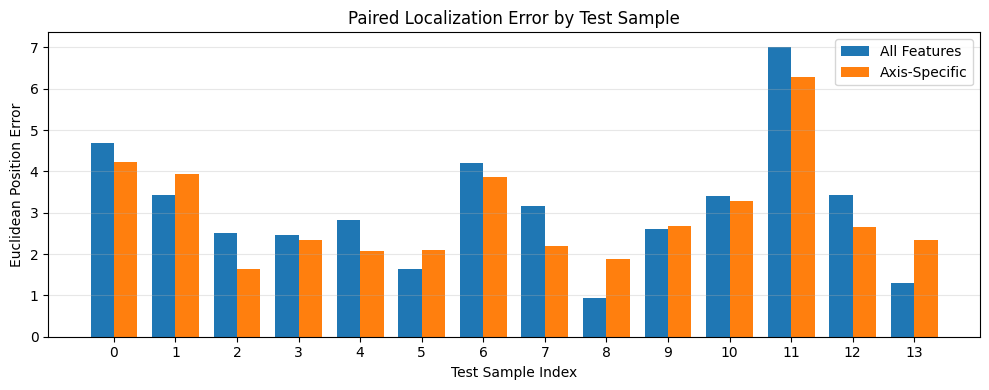


DIAGNOSTIC ANALYSIS COMPLETED


In [137]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# POST-EVALUATION DIAGNOSTICS
# No retraining or hyperparameter tuning
# =====================================================

err_base = np.asarray(
    sample_errors["Mean Baseline"], dtype=float
)

err_all = np.asarray(
    sample_errors["All Features"], dtype=float
)

err_axis = np.asarray(
    sample_errors["Axis-Specific"], dtype=float
)

n = len(err_axis)

assert n == 14
assert all(len(e) == n for e in [
    err_base, err_all, err_axis
])

# Positive values mean Axis-Specific is better
gain_vs_all = err_all - err_axis
gain_vs_base = err_base - err_axis

print("=== PAIRED TEST COMPARISON ===")

paired_summary = pd.DataFrame({
    "Comparison": [
        "Axis-Specific vs All Features",
        "Axis-Specific vs Mean Baseline"
    ],
    "Mean_Error_Reduction": [
        gain_vs_all.mean(),
        gain_vs_base.mean()
    ],
    "Median_Error_Reduction": [
        np.median(gain_vs_all),
        np.median(gain_vs_base)
    ],
    "Axis_Better_Count": [
        np.sum(gain_vs_all > 0),
        np.sum(gain_vs_base > 0)
    ],
    "Axis_Worse_Count": [
        np.sum(gain_vs_all < 0),
        np.sum(gain_vs_base < 0)
    ]
})

display(paired_summary.round(4))

# ==========================================
# PAIRED BOOTSTRAP
# Exploratory uncertainty estimate
# ==========================================

rng = np.random.default_rng(42)
B = 10000

bootstrap_indices = rng.integers(
    0, n, size=(B, n)
)

boot_gain_all = gain_vs_all[
    bootstrap_indices
].mean(axis=1)

boot_gain_base = gain_vs_base[
    bootstrap_indices
].mean(axis=1)

print("\n=== EXPLORATORY BOOTSTRAP ===")

for label, boot in [
    ("vs All Features", boot_gain_all),
    ("vs Mean Baseline", boot_gain_base)
]:
    lo, hi = np.percentile(boot, [2.5, 97.5])

    print(label)
    print("95% percentile interval:",
          f"[{lo:.4f}, {hi:.4f}]")

# ==========================================
# SAMPLE-LEVEL COMPARISON
# ==========================================

diagnostic_df = pd.DataFrame({
    "Sample": np.arange(n),
    "Actual_X": y_te[:, 0],
    "Actual_Y": y_te[:, 1],
    "All_Features_Error": err_all,
    "Axis_Specific_Error": err_axis,
    "Axis_Gain": gain_vs_all
})

print("\n=== SAMPLE-LEVEL GAINS ===")
display(
    diagnostic_df.sort_values(
        "Axis_Gain"
    ).round(4)
)

# ==========================================
# RAW DATA DUPLICATE CHECK
# ==========================================

dev_raw = np.concatenate([
    X_train, X_val
], axis=0)

test_raw = np.asarray(X_test)

dev_flat = dev_raw.reshape(len(dev_raw), -1)
test_flat = test_raw.reshape(len(test_raw), -1)

exact_matches = []

for i, sample in enumerate(test_flat):
    matches = np.flatnonzero(
        np.all(dev_flat == sample, axis=1)
    )
    if len(matches):
        exact_matches.append(
            (i, matches.tolist())
        )

print("\n=== EXACT RAW CSI DUPLICATE CHECK ===")
print("Exact train/val-test matches:", exact_matches)

# ==========================================
# PLOT PAIRED ERRORS
# ==========================================

plt.figure(figsize=(10, 4))

positions = np.arange(n)
width = 0.38

plt.bar(
    positions - width / 2,
    err_all,
    width,
    label="All Features"
)

plt.bar(
    positions + width / 2,
    err_axis,
    width,
    label="Axis-Specific"
)

plt.xlabel("Test Sample Index")
plt.ylabel("Euclidean Position Error")
plt.title("Paired Localization Error by Test Sample")
plt.xticks(positions)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nDIAGNOSTIC ANALYSIS COMPLETED")



In [138]:

import inspect

print("=== PREPROCESSING FUNCTION AUDIT ===");

keywords = [
    "normal",
    "standard",
    "scale",
    "preprocess",
    "split"
]

for name, obj in list(globals().items()):

    if (
        inspect.isfunction(obj)
        and any(
            key in name.lower()
            for key in keywords
        )
    ):
        print("\nFUNCTION:", name);
        print("SIGNATURE:", inspect.signature(obj));

        try:
            print(inspect.getsource(obj))
        except (OSError, TypeError):
            print("Source code unavailable")

print("\n=== DATASET SHAPES ===");

for name in [
    "X_train", "X_val", "X_test",
    "X_train_normalized",
    "X_val_normalized",
    "X_test_normalized",
    "train_idx", "val_idx", "test_idx"
]:
    obj = globals().get(name)

    if obj is not None:
        print(name, np.shape(obj));


=== PREPROCESSING FUNCTION AUDIT ===

FUNCTION: train_test_split
SIGNATURE: (*arrays, test_size=None, train_size=None, random_state=None, shuffle=True, stratify=None)
@validate_params(
    {
        "test_size": [
            Interval(RealNotInt, 0, 1, closed="neither"),
            Interval(numbers.Integral, 1, None, closed="left"),
            None,
        ],
        "train_size": [
            Interval(RealNotInt, 0, 1, closed="neither"),
            Interval(numbers.Integral, 1, None, closed="left"),
            None,
        ],
        "random_state": ["random_state"],
        "shuffle": ["boolean"],
        "stratify": ["array-like", None],
    },
    prefer_skip_nested_validation=True,
)
def train_test_split(
    *arrays,
    test_size=None,
    train_size=None,
    random_state=None,
    shuffle=True,
    stratify=None,
):
    """Split arrays or matrices into random train and test subsets.

    Quick utility that wraps input validation,
    ``next(ShuffleSplit().split(X, y))``

In [139]:

import numpy as np

print("=== COMPACT DATA AUDIT ===")

# Recompute normalization from current raw splits
a, b, c = normalize_spatial_data(
    X_train_processed,
    X_val_processed,
    X_test_processed
)

for name, actual, reconstructed in [
    ("Train", X_train_normalized, a),
    ("Val", X_val_normalized, b),
    ("Test", X_test_normalized, c)
]:
    print(
        name,
        "normalization match:",
        np.allclose(
            actual, reconstructed,
            rtol=1e-5, atol=1e-6
        )
    )

# Check overlap among current raw splits
def sample_keys(X):
    X = np.ascontiguousarray(X)
    return {
        X[i].tobytes()
        for i in range(len(X))
    }

train_keys = sample_keys(X_train)
val_keys = sample_keys(X_val)
test_keys = sample_keys(X_test)

print(
    "Train-Val overlap:",
    len(train_keys & val_keys)
)
print(
    "Train-Test overlap:",
    len(train_keys & test_keys)
)
print(
    "Val-Test overlap:",
    len(val_keys & test_keys)
)

print(
    "Saved index lengths:",
    len(train_idx),
    len(val_idx),
    len(test_idx)
)

print("AUDIT COMPLETED")


=== COMPACT DATA AUDIT ===
Train normalization match: False
Val normalization match: False
Test normalization match: False
Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0
Saved index lengths: 61 15 14
AUDIT COMPLETED


In [140]:

import numpy as np

print("=== NORMALIZATION SOURCE AUDIT ===")

for source_name, data in [
    ("Raw", (X_train, X_val, X_test)),
    ("Processed", (
        X_train_processed,
        X_val_processed,
        X_test_processed
    ))
]:
    try:
        reconstructed = normalize_spatial_data(*data)

        matches = [
            np.allclose(
                actual, rebuilt,
                rtol=1e-5,
                atol=1e-6
            )
            for actual, rebuilt in zip(
                (
                    X_train_normalized,
                    X_val_normalized,
                    X_test_normalized
                ),
                reconstructed
            )
        ]

        print(source_name, "matches:", matches)

    except Exception as e:
        print(source_name, "error:", str(e)[:100])

print("\n=== FEATURE CHANNEL AUDIT ===")

print("Assumed amplitude mean indices: 0-89")
print("Assumed phase mean indices: 90-179")

print("Preprocessing channel arrangement:")
for antenna in range(3):
    print(
        f"Antenna {antenna + 1}: "
        f"amplitude={antenna * 2}, "
        f"phase={antenna * 2 + 1}"
    )

print("\nCorrect indices for interleaved channels:")

amplitude_channels = [0, 2, 4]
phase_channels = [1, 3, 5]

amp_idx = np.concatenate([
    np.arange(ch * 30, (ch + 1) * 30)
    for ch in amplitude_channels
])

phase_idx = np.concatenate([
    np.arange(ch * 30, (ch + 1) * 30)
    for ch in phase_channels
])

print("Amplitude mean:", amp_idx.shape)
print("Phase mean:", phase_idx.shape)
print("Amplitude first indices:", amp_idx[:5])
print("Phase first indices:", phase_idx[:5])

print("\nAUDIT COMPLETED")


=== NORMALIZATION SOURCE AUDIT ===
Raw matches: [False, False, False]
Processed matches: [False, False, False]

=== FEATURE CHANNEL AUDIT ===
Assumed amplitude mean indices: 0-89
Assumed phase mean indices: 90-179
Preprocessing channel arrangement:
Antenna 1: amplitude=0, phase=1
Antenna 2: amplitude=2, phase=3
Antenna 3: amplitude=4, phase=5

Correct indices for interleaved channels:
Amplitude mean: (90,)
Phase mean: (90,)
Amplitude first indices: [0 1 2 3 4]
Phase first indices: [30 31 32 33 34]

AUDIT COMPLETED


In [141]:

import numpy as np

print("=== CHANNEL MAPPING VERIFICATION ===")

# Verify that statistical features follow
# the expected channel-major ordering.
reconstructed = extract_csi_features(
    X_train_normalized
)

mean_channels = X_train_normalized.mean(axis=2)

checks = []

for channel in range(6):
    start = channel * 30
    end = start + 30

    match = np.allclose(
        reconstructed[:, start:end],
        mean_channels[:, channel, :],
        rtol=1e-5,
        atol=1e-6
    )

    checks.append(match)

    print(
        f"Channel {channel}:",
        "MATCH" if match else "MISMATCH"
    )

print("All channels match:", all(checks))

# Correct mean feature indices
amp_mean_idx = np.concatenate([
    np.arange(ch * 30, (ch + 1) * 30)
    for ch in [0, 2, 4]
])

phase_mean_idx = np.concatenate([
    np.arange(ch * 30, (ch + 1) * 30)
    for ch in [1, 3, 5]
])

print("\nAmplitude indices:", len(amp_mean_idx))
print("Phase indices:", len(phase_mean_idx))
print("Feature overlap:",
      len(set(amp_mean_idx) & set(phase_mean_idx)))

print("\n=== NORMALIZATION DIFFERENCE ===")

for source_name, arrays in [
    ("Raw", (X_train, X_val, X_test)),
    ("Processed", (
        X_train_processed,
        X_val_processed,
        X_test_processed
    ))
]:
    rebuilt = normalize_spatial_data(*arrays)

    diffs = [
        np.mean(np.abs(a - b))
        for a, b in zip(
            rebuilt,
            (
                X_train_normalized,
                X_val_normalized,
                X_test_normalized
            )
        )
    ]

    print(
        source_name,
        "MAE differences:",
        np.round(diffs, 6)
    )

print("\nAUDIT COMPLETED")


=== CHANNEL MAPPING VERIFICATION ===
Channel 0: MATCH
Channel 1: MATCH
Channel 2: MATCH
Channel 3: MATCH
Channel 4: MATCH
Channel 5: MATCH
All channels match: True

Amplitude indices: 90
Phase indices: 90
Feature overlap: 0

=== NORMALIZATION DIFFERENCE ===
Raw MAE differences: [0. 0. 0.]
Processed MAE differences: [0.616964 0.636072 0.625252]

AUDIT COMPLETED


In [142]:

import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import RepeatedKFold

# =====================================================
# CORRECTED FEATURE GROUP VALIDATION
# Development data only
# =====================================================

SEED = 42

X = np.asarray(X_dev, dtype=np.float32)
y = np.asarray(y_dev, dtype=np.float32)

assert X.shape == (76, 360)
assert y.shape == (76, 2)

# Correct interleaved-channel mapping
amp_mean_idx = np.concatenate([
    np.arange(ch * 30, (ch + 1) * 30)
    for ch in [0, 2, 4]
])

phase_mean_idx = np.concatenate([
    np.arange(ch * 30, (ch + 1) * 30)
    for ch in [1, 3, 5]
])

all_idx = np.arange(360)

configurations = {
    "All Features": (
        all_idx, all_idx
    ),
    "Corrected Axis-Specific": (
        amp_mean_idx, phase_mean_idx
    ),
    "Reversed Axis-Specific": (
        phase_mean_idx, amp_mean_idx
    )
}

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=SEED
)

def make_model():
    return ExtraTreesRegressor(
        n_estimators=40,
        min_samples_leaf=2,
        max_features=0.7,
        random_state=SEED,
        n_jobs=2
    )

results = []

for fold, (tr, va) in enumerate(cv.split(X), 1):

    for name, (idx_x, idx_y) in configurations.items():

        model_x = make_model()
        model_y = make_model()

        model_x.fit(
            X[tr][:, idx_x],
            y[tr, 0]
        )

        model_y.fit(
            X[tr][:, idx_y],
            y[tr, 1]
        )

        predictions = np.column_stack([
            model_x.predict(X[va][:, idx_x]),
            model_y.predict(X[va][:, idx_y])
        ])

        errors = predictions - y[va]

        distances = np.linalg.norm(
            errors, axis=1
        )

        results.append({
            "Fold": fold,
            "Configuration": name,
            "MDE": distances.mean(),
            "RMSE": np.sqrt(
                np.mean(distances ** 2)
            ),
            "X_MAE": np.abs(
                errors[:, 0]
            ).mean(),
            "Y_MAE": np.abs(
                errors[:, 1]
            ).mean()
        })

results_df = pd.DataFrame(results)

summary = results_df.groupby(
    "Configuration"
).agg(
    Mean_MDE=("MDE", "mean"),
    STD_MDE=("MDE", "std"),
    Mean_RMSE=("RMSE", "mean"),
    X_MAE=("X_MAE", "mean"),
    Y_MAE=("Y_MAE", "mean")
).sort_values("Mean_MDE")

print("=== CORRECTED FEATURE VALIDATION ===")
display(summary.round(4))

pivot = results_df.pivot(
    index="Fold",
    columns="Configuration",
    values="MDE"
)

print("\n=== PAIRED FOLD COMPARISON ===")

for name in [
    "Corrected Axis-Specific",
    "Reversed Axis-Specific"
]:
    difference = (
        pivot["All Features"] - pivot[name]
    )

    print(
        name,
        "| Mean MDE reduction:",
        round(difference.mean(), 4),
        "| Better folds:",
        int((difference > 0).sum()),
        "/ 15"
    )

print("\nVALIDATION COMPLETED")


=== CORRECTED FEATURE VALIDATION ===


,Mean_MDE,STD_MDE,Mean_RMSE,X_MAE,Y_MAE
Configuration,,,,,
All Features,3.0319,0.5642,3.3665,1.5265,2.3937
Corrected Axis-Specific,3.1156,0.5513,3.4657,1.5302,2.4840
Reversed Axis-Specific,3.3915,0.4908,3.6550,2.1260,2.2934



=== PAIRED FOLD COMPARISON ===
Corrected Axis-Specific | Mean MDE reduction: -0.0837 | Better folds: 4 / 15
Reversed Axis-Specific | Mean MDE reduction: -0.3596 | Better folds: 1 / 15

VALIDATION COMPLETED


In [143]:

import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import RepeatedKFold

# =====================================================
# LEAKAGE-AWARE CROSS-VALIDATION
# Normalization fitted inside each fold
# =====================================================

SEED = 42

X_raw_dev = np.concatenate(
    [X_train, X_val], axis=0
).astype(np.float32)

y_raw_dev = np.concatenate(
    [y_train, y_val], axis=0
).astype(np.float32)

assert X_raw_dev.shape == (76, 6, 60, 30)
assert y_raw_dev.shape == (76, 2)

amp_mean_idx = np.concatenate([
    np.arange(ch * 30, (ch + 1) * 30)
    for ch in [0, 2, 4]
])

phase_mean_idx = np.concatenate([
    np.arange(ch * 30, (ch + 1) * 30)
    for ch in [1, 3, 5]
])

configs = {
    "All Features": (
        np.arange(360),
        np.arange(360)
    ),
    "Corrected Axis-Specific": (
        amp_mean_idx,
        phase_mean_idx
    ),
    "Reversed Axis-Specific": (
        phase_mean_idx,
        amp_mean_idx
    )
}

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=SEED
)

def make_model():
    return ExtraTreesRegressor(
        n_estimators=40,
        min_samples_leaf=2,
        max_features=0.7,
        random_state=SEED,
        n_jobs=2
    )

records = []

for fold, (tr, va) in enumerate(
    cv.split(X_raw_dev), 1
):

    # Fit normalization using training fold only
    X_tr_norm, X_va_norm, _ = normalize_spatial_data(
        X_raw_dev[tr],
        X_raw_dev[va],
        X_raw_dev[va]
    )

    F_tr = extract_csi_features(X_tr_norm)
    F_va = extract_csi_features(X_va_norm)

    for name, (idx_x, idx_y) in configs.items():

        model_x = make_model()
        model_y = make_model()

        model_x.fit(
            F_tr[:, idx_x],
            y_raw_dev[tr, 0]
        )

        model_y.fit(
            F_tr[:, idx_y],
            y_raw_dev[tr, 1]
        )

        pred = np.column_stack([
            model_x.predict(F_va[:, idx_x]),
            model_y.predict(F_va[:, idx_y])
        ])

        error = pred - y_raw_dev[va]

        distance = np.linalg.norm(
            error, axis=1
        )

        records.append({
            "Fold": fold,
            "Configuration": name,
            "MDE": distance.mean(),
            "RMSE": np.sqrt(
                np.mean(distance ** 2)
            ),
            "X_MAE": np.abs(
                error[:, 0]
            ).mean(),
            "Y_MAE": np.abs(
                error[:, 1]
            ).mean()
        })

cv_results = pd.DataFrame(records)

summary = cv_results.groupby(
    "Configuration"
).agg(
    Mean_MDE=("MDE", "mean"),
    STD_MDE=("MDE", "std"),
    Mean_RMSE=("RMSE", "mean"),
    X_MAE=("X_MAE", "mean"),
    Y_MAE=("Y_MAE", "mean")
).sort_values("Mean_MDE")

print("=== LEAKAGE-AWARE CV RESULTS ===")
display(summary.round(4))

pivot = cv_results.pivot(
    index="Fold",
    columns="Configuration",
    values="MDE"
)

print("\n=== PAIRED COMPARISON ===")

for name in [
    "Corrected Axis-Specific",
    "Reversed Axis-Specific"
]:
    gain = (
        pivot["All Features"] - pivot[name]
    )

    print(
        name,
        "| Mean MDE reduction:",
        round(gain.mean(), 4),
        "| Better folds:",
        int((gain > 0).sum()),
        "/ 15"
    )

print("\nLEAKAGE-AWARE CV COMPLETED")


=== LEAKAGE-AWARE CV RESULTS ===


,Mean_MDE,STD_MDE,Mean_RMSE,X_MAE,Y_MAE
Configuration,,,,,
All Features,3.0319,0.5642,3.3665,1.5265,2.3937
Corrected Axis-Specific,3.1156,0.5513,3.4657,1.5302,2.4840
Reversed Axis-Specific,3.3915,0.4908,3.6550,2.1260,2.2934



=== PAIRED COMPARISON ===
Corrected Axis-Specific | Mean MDE reduction: -0.0837 | Better folds: 4 / 15
Reversed Axis-Specific | Mean MDE reduction: -0.3596 | Better folds: 1 / 15

LEAKAGE-AWARE CV COMPLETED


In [144]:

import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor

# =====================================================
# FINAL ALL-FEATURES MODEL REPRODUCTION
# Frozen configuration, no hyperparameter search
# =====================================================

SEED = 42

# Raw development and test data
X_dev_raw = np.concatenate([
    X_train,
    X_val
], axis=0).astype(np.float32)

y_dev_final = np.concatenate([
    y_train,
    y_val
], axis=0).astype(np.float32)

X_test_raw = np.asarray(
    X_test, dtype=np.float32
)

y_test_final = np.asarray(
    y_test, dtype=np.float32
)

# Fit normalization on development only
X_dev_norm, _, X_test_norm = normalize_spatial_data(
    X_dev_raw,
    X_dev_raw,
    X_test_raw
)

# Extract statistical CSI features
F_dev = extract_csi_features(X_dev_norm)
F_test = extract_csi_features(X_test_norm)

assert F_dev.shape == (76, 360)
assert F_test.shape == (14, 360)

def make_final_model():
    return ExtraTreesRegressor(
        n_estimators=40,
        min_samples_leaf=2,
        max_features=0.7,
        random_state=SEED,
        n_jobs=2
    )

# One model for each coordinate
model_x_final = make_final_model()
model_y_final = make_final_model()

model_x_final.fit(
    F_dev,
    y_dev_final[:, 0]
)

model_y_final.fit(
    F_dev,
    y_dev_final[:, 1]
)

pred_final = np.column_stack([
    model_x_final.predict(F_test),
    model_y_final.predict(F_test)
])

# Evaluation
errors = pred_final - y_test_final

distances = np.linalg.norm(
    errors, axis=1
)

final_metrics = {
    "MDE": distances.mean(),
    "Median_Error": np.median(distances),
    "Position_RMSE": np.sqrt(
        np.mean(distances ** 2)
    ),
    "X_MAE": np.mean(
        np.abs(errors[:, 0])
    ),
    "Y_MAE": np.mean(
        np.abs(errors[:, 1])
    ),
    "P90_Error": np.percentile(
        distances, 90
    )
}

print("=== FINAL ALL-FEATURES TEST ===")

for metric, value in final_metrics.items():
    print(f"{metric:18s}: {value:.4f}")

print("\n=== REPRODUCIBILITY CHECK ===")

previous_all = np.asarray(
    all_predictions
)

print(
    "Prediction match:",
    np.allclose(
        pred_final,
        previous_all,
        rtol=1e-5,
        atol=1e-6
    )
)

print(
    "Prediction mean absolute difference:",
    np.mean(
        np.abs(pred_final - previous_all)
    )
)

print("\nFINAL REPRODUCTION COMPLETED")


=== FINAL ALL-FEATURES TEST ===
MDE               : 3.1168
Median_Error      : 2.9924
Position_RMSE     : 3.4478
X_MAE             : 1.7827
Y_MAE             : 2.2000
P90_Error         : 4.5395

=== REPRODUCIBILITY CHECK ===
Prediction match: True
Prediction mean absolute difference: 7.930164461608261e-17

FINAL REPRODUCTION COMPLETED


In [145]:

import numpy as np
import pandas as pd

print("=== LOCATION GENERALIZATION AUDIT ===")

# Use exact coordinates as location identifiers
# Appropriate when targets represent a discrete grid
dev_locations = {
    tuple(row)
    for row in np.asarray(y_dev_final)
}

test_locations = [
    tuple(row)
    for row in np.asarray(y_test_final)
]

seen_mask = np.array([
    location in dev_locations
    for location in test_locations
])

unseen_mask = ~seen_mask

print("Development samples:", len(y_dev_final))
print("Unique development locations:", len(dev_locations))
print("Test samples:", len(y_test_final))
print("Unique test locations:", len(set(test_locations)))
print("Test samples at seen locations:",
      int(seen_mask.sum()))
print("Test samples at unseen locations:",
      int(unseen_mask.sum()))

# Final model per-sample errors
position_errors = np.linalg.norm(
    pred_final - y_test_final,
    axis=1
)

for label, mask in [
    ("Seen locations", seen_mask),
    ("Unseen locations", unseen_mask)
]:
    if mask.any():
        print(
            f"{label} MDE:",
            round(position_errors[mask].mean(), 4),
            "| Samples:", int(mask.sum())
        )
    else:
        print(f"{label}: no samples")

print("\n=== FINAL MODEL DOCUMENTATION ===")

documentation = pd.DataFrame([{
    "Model": "Extra Trees Regressor",
    "Features": "CSI Temporal Mean + STD",
    "Feature_Count": 360,
    "Development_Samples": 76,
    "Test_Samples": 14,
    "Trees": 40,
    "Min_Samples_Leaf": 2,
    "Max_Features": 0.7,
    "CV_MDE": 3.0319,
    "Test_MDE": float(position_errors.mean()),
    "Test_RMSE": float(
        np.sqrt(np.mean(position_errors ** 2))
    ),
    "Test_X_MAE": float(
        np.mean(np.abs(
            pred_final[:, 0] - y_test_final[:, 0]
        ))
    ),
    "Test_Y_MAE": float(
        np.mean(np.abs(
            pred_final[:, 1] - y_test_final[:, 1]
        ))
    )
}])

display(documentation.round(4))

print("\nLOCATION AUDIT COMPLETED")


=== LOCATION GENERALIZATION AUDIT ===
Development samples: 76
Unique development locations: 76
Test samples: 14
Unique test locations: 14
Test samples at seen locations: 0
Test samples at unseen locations: 14
Seen locations: no samples
Unseen locations MDE: 3.1168 | Samples: 14

=== FINAL MODEL DOCUMENTATION ===


,Model,Features,Feature_Count,Development_Samples,Test_Samples,Trees,Min_Samples_Leaf,Max_Features,CV_MDE,Test_MDE,Test_RMSE,Test_X_MAE,Test_Y_MAE
0,Extra Trees Regressor,CSI Temporal Mean + STD,360,76,14,40,2,0.7,3.0319,3.1168,3.4478,1.7827,2.2



LOCATION AUDIT COMPLETED


In [146]:

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

print("=== SPATIAL DISTANCE AUDIT ===")

dev_coords = np.asarray(y_dev_final, dtype=float)
test_coords = np.asarray(y_test_final, dtype=float)

# Distance from each test coordinate
# to every development coordinate
distance_matrix = cdist(
    test_coords,
    dev_coords,
    metric="euclidean"
)

nearest_dev_distance = distance_matrix.min(axis=1)

prediction_error = np.linalg.norm(
    pred_final - test_coords,
    axis=1
)

audit_table = pd.DataFrame({
    "Test_ID": np.arange(1, len(test_coords) + 1),
    "True_X": test_coords[:, 0],
    "True_Y": test_coords[:, 1],
    "Nearest_Dev_Distance": nearest_dev_distance,
    "Prediction_Error": prediction_error
})

print("\n=== DISTANCE SUMMARY ===")

print(
    "Minimum nearest distance:",
    round(nearest_dev_distance.min(), 4)
)

print(
    "Median nearest distance:",
    round(np.median(nearest_dev_distance), 4)
)

print(
    "Mean nearest distance:",
    round(nearest_dev_distance.mean(), 4)
)

print(
    "Maximum nearest distance:",
    round(nearest_dev_distance.max(), 4)
)

print("\n=== ERROR RELATIONSHIP ===")

if np.std(nearest_dev_distance) > 0:
    correlation = np.corrcoef(
        nearest_dev_distance,
        prediction_error
    )[0, 1]

    print(
        "Correlation (distance vs error):",
        round(correlation, 4)
    )
else:
    print(
        "Correlation unavailable:",
        "all nearest distances are equal"
    )

print("\n=== PER-SAMPLE AUDIT ===")

display(
    audit_table.round(4).sort_values(
        "Nearest_Dev_Distance",
        ascending=False
    )
)

print("\nSPATIAL AUDIT COMPLETED")


=== SPATIAL DISTANCE AUDIT ===

=== DISTANCE SUMMARY ===
Minimum nearest distance: 1.0
Median nearest distance: 1.0
Mean nearest distance: 1.0
Maximum nearest distance: 1.0

=== ERROR RELATIONSHIP ===
Correlation unavailable: all nearest distances are equal

=== PER-SAMPLE AUDIT ===


,Test_ID,True_X,True_Y,Nearest_Dev_Distance,Prediction_Error
0,1,1.0,0.0,1.0,4.6807
1,2,8.0,6.0,1.0,3.4202
2,3,4.0,4.0,1.0,2.5203
3,4,6.0,9.0,1.0,2.4730
4,5,4.0,0.0,1.0,2.8150
5,6,3.0,5.0,1.0,1.6424
6,7,1.0,8.0,1.0,4.2100
7,8,2.0,8.0,1.0,3.1699
8,9,5.0,6.0,1.0,0.9463
9,10,3.0,3.0,1.0,2.6187



SPATIAL AUDIT COMPLETED


In [147]:

import numpy as np

print("=== FINAL BASELINE COMPARISON ===")

y_true = np.asarray(y_test_final)
pred_model = np.asarray(pred_final)

# Development mean baseline
mean_position = np.mean(y_dev_final, axis=0)

pred_baseline = np.tile(
    mean_position,
    (len(y_true), 1)
)

model_errors = np.linalg.norm(
    pred_model - y_true,
    axis=1
)

baseline_errors = np.linalg.norm(
    pred_baseline - y_true,
    axis=1
)

improvement = baseline_errors - model_errors

print("Baseline MDE:",
      round(baseline_errors.mean(), 4))

print("Extra Trees MDE:",
      round(model_errors.mean(), 4))

print("Mean improvement:",
      round(improvement.mean(), 4))

print("Relative improvement (%):",
      round(
          100 * improvement.mean()
          / baseline_errors.mean(),
          2
      ))

print("Model better samples:",
      int((improvement > 0).sum()),
      "/", len(improvement))

# Paired bootstrap
rng = np.random.default_rng(42)

bootstrap_improvements = []

for _ in range(10000):
    idx = rng.integers(
        0,
        len(improvement),
        len(improvement)
    )

    bootstrap_improvements.append(
        improvement[idx].mean()
    )

ci_low, ci_high = np.percentile(
    bootstrap_improvements,
    [2.5, 97.5]
)

print("\n=== BOOTSTRAP UNCERTAINTY ===")

print("95% bootstrap interval:",
      round(ci_low, 4),
      "to",
      round(ci_high, 4))

print("\nBASELINE AUDIT COMPLETED")


=== FINAL BASELINE COMPARISON ===
Baseline MDE: 3.2977
Extra Trees MDE: 3.1168
Mean improvement: 0.1809
Relative improvement (%): 5.48
Model better samples: 7 / 14

=== BOOTSTRAP UNCERTAINTY ===
95% bootstrap interval: -0.3907 to 0.7691

BASELINE AUDIT COMPLETED
